In [ ]:
# @title Ячейка 1: Быстрая подготовка окружения (~5-10 сек)
# @markdown Единый ноутбук этапов 1-12, версия 3.1.1. Код проекта лежит в пакете `support_router`
# @markdown (папка `src/` репозитория), ноутбук только импортирует его. Где взять код: задайте
# @markdown `PROJECT_REPO` (адрес на GitHub) или загрузите архив `support-ticket-router.zip`.
import os, sys, subprocess, importlib.metadata, zipfile
from pathlib import Path
# Windows: дочерние процессы (тесты, приложение, проверки) пишут и читают в UTF-8, а не в кодировке системы.
os.environ.setdefault('PYTHONUTF8', '1')
os.environ.setdefault('PYTHONIOENCODING', 'utf-8')
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('MKL_NUM_THREADS', '1')
PROJECT_REPO = ''  # например 'https://github.com/<команда>/support-ticket-router.git'
PROJECT_ARCHIVE = 'support-ticket-router.zip'

def find_project():
    here = Path.cwd().resolve()
    for folder in [here, here.parent, here/'support-ticket-router', Path('/content/support-ticket-router')]:
        if (folder/'src/support_router/__init__.py').exists():
            return folder.resolve()
    found = sorted(Path('support-ticket-router').glob('**/src/support_router/__init__.py')) if Path('support-ticket-router').exists() else []
    return found[0].parents[2].resolve() if found else None

PROJECT_DIR = find_project()
if PROJECT_DIR is None and PROJECT_REPO:
    subprocess.check_call(['git', 'clone', '--depth', '1', PROJECT_REPO, 'support-ticket-router'])
    PROJECT_DIR = find_project()
if PROJECT_DIR is None:
    archive = Path(PROJECT_ARCHIVE)
    if not archive.exists() and 'google.colab' in sys.modules and os.environ.get('SUPPORT_NONINTERACTIVE') != '1':
        from google.colab import files
        print('Загрузите архив проекта support-ticket-router.zip')
        uploaded = [Path(name) for name in files.upload() if name.endswith('.zip')]
        archive = uploaded[0] if uploaded else archive
    if archive.exists():
        with zipfile.ZipFile(archive) as zf:
            zf.extractall('support-ticket-router')
        PROJECT_DIR = find_project()
if PROJECT_DIR is None:
    raise FileNotFoundError('Нет кода проекта: задайте PROJECT_REPO или положите support-ticket-router.zip рядом с ноутбуком.')
os.chdir(PROJECT_DIR)

required = {'scikit-learn': '1.8.0', 'gradio': '6.0.0', 'wordcloud': '1.9.6',
            'onnxruntime': '1.23.2', 'tokenizers': '0.22.1', 'prometheus-client': '0.26.0'}
missing = []
for name, version in required.items():
    try:
        if importlib.metadata.version(name) != version:
            missing.append(f'{name}=={version}')
    except importlib.metadata.PackageNotFoundError:
        missing.append(f'{name}=={version}')
for name in ['numpy', 'pandas', 'scipy', 'joblib', 'matplotlib', 'seaborn', 'pytest', 'fastapi', 'uvicorn', 'httpx', 'PyYAML']:
    try: importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError: missing.append(name)
if missing:
    if 'sklearn' in sys.modules and any(x.startswith('scikit-learn') for x in missing):
        raise RuntimeError('Перезапустите среду и выполните ноутбук с первой ячейки: sklearn уже импортирован.')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
RAW_DIR = PROJECT_DIR / 'data/raw'
PROCESSED_DIR = PROJECT_DIR / 'data/processed'
MODELS_DIR = PROJECT_DIR / 'models'
REPORTS_DIR = PROJECT_DIR / 'reports'
for p in [RAW_DIR, PROCESSED_DIR, MODELS_DIR, REPORTS_DIR]:
    p.mkdir(parents=True, exist_ok=True)

for folder in [PROJECT_DIR, PROJECT_DIR / 'src']:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
os.environ['PYTHONPATH'] = os.pathsep.join([str(PROJECT_DIR / 'src'), str(PROJECT_DIR)])
import importlib
import support_router as sc
from support_router import scenario_data, semantic_encoder, category_examples, manual_cases
# Семантический энкодер понадобится только при обучении semantic_* конфигураций.
# На Colab x86_64 он загружается при первом использовании; для офлайн smoke тестов
# допускается SUPPORT_SKIP_SEMANTIC_TESTS=1, но полный эксперимент требует загрузки.
import json, random, time, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import f1_score, accuracy_score, classification_report
from threadpoolctl import threadpool_limits
SEED = sc.SEED
random.seed(SEED); np.random.seed(SEED)
pd.set_option('display.max_colwidth', 110)
sns.set_theme(style='whitegrid')
print('Версии:', sc.runtime_versions())
print('Проект:', PROJECT_DIR)
print('Признаки: только текст. category — цель; intent, flags, row_id, group — диагностика/разбиение.')
print('MiniLM (если используются semantic_*): локальный ONNX, первая загрузка ~24 МБ. Операционная автоотправка заблокирована до внешней проверки.')


Версии: {'numpy': '2.4.6', 'pandas': '2.2.3', 'scipy': '1.16.3', 'scikit-learn': '1.8.0', 'joblib': '1.6.0', 'matplotlib': '3.10.0', 'seaborn': '0.13.2', 'wordcloud': '1.9.6', 'gradio': '6.0.0', 'nbformat': '5.11.1', 'nbclient': '0.10.4', 'pytest': '8.4.2', 'onnxruntime': '1.23.2', 'tokenizers': '0.22.1'}
Проект: support-ticket-router
Признаки: только текст. category — цель; intent, flags, row_id, group — диагностика/разбиение.
MiniLM (если используются semantic_*): локальный ONNX, первая загрузка ~24 МБ. Операционная автоотправка заблокирована до внешней проверки.


**Этап 2. Загрузка и первичное изучение датасета**

Работаем с CSV **Bitext Sample Pre-built Customer Support Dataset for English (2020)**: 27 интентов и 11 категорий. Официальные значения **12 лингвистических flags** подтверждены карточкой [Bitext на Kaggle](https://www.kaggle.com/datasets/bitext/training-dataset-for-chatbotsvirtual-assistants/metadata). SLA и правила бизнес-приоритетов датасетом **не** определяются. Флаги — метаданные для диагностики, не признаки модели и не метки P1.

In [ ]:
# @title Ячейка 2: Загрузка датасета
RAW_NAME = '20000-Utterances-Training-dataset-for-chatbots-virtual-assistant-Bitext-sample.csv'
raw_path = RAW_DIR / RAW_NAME
if not raw_path.exists():
    candidates = []
    for folder in [PROJECT_DIR, Path.cwd(), Path('/content')]:
        if folder.exists():
            candidates += list(folder.glob('20000-Utterances-Training-dataset-for-chatbots-virtual-assistant-Bitext-sample*.csv'))
    candidates = sorted(set(p.resolve() for p in candidates))
    if len(candidates) == 1:
        raw_path = candidates[0]
    elif len(candidates) > 1:
        raise ValueError('Несколько исходных CSV: оставьте нужный файл или явно задайте raw_path.')
    elif 'google.colab' in sys.modules and os.environ.get('SUPPORT_NONINTERACTIVE') != '1':
        from google.colab import files
        uploaded = files.upload()
        matches = [Path(n) for n in uploaded if n.endswith('.csv')]
        if len(matches) != 1: raise ValueError('Загрузите один исходный CSV.')
        raw_path = matches[0]
    else:
        raise FileNotFoundError(f'Положите исходный CSV в {RAW_DIR} или текущую папку.')
raw = pd.read_csv(raw_path)
df = raw.copy()
required_columns = {'utterance', 'category', 'intent', 'flags'}
assert required_columns.issubset(df.columns), df.columns.tolist()
print('Размер:', df.shape, '| SHA256:', sc.sha256_file(raw_path))
display(df.head())
display(df.isna().sum().rename('missing'))


Saving 20000-Utterances-Training-dataset-for-chatbots-virtual-assistant-Bitext-sample.csv to 20000-Utterances-Training-dataset-for-chatbots-virtual-assistant-Bitext-sample.csv
Размер: (21534, 4) | SHA256: 19a3031d649ce432202acd807630b1b52884507185f32832d58714f3fac7d82b


,flags,utterance,category,intent
0,BILC,"I don't have an online account, what do I have to do to register?",ACCOUNT,create_account
1,BILQZ,can you tell me if i can regisger two accounts with a single email address?,ACCOUNT,create_account
2,BPLC,"I have no online account, open one, please",ACCOUNT,create_account
3,BIPLD,"could you ask an agent how to open an account, please?",ACCOUNT,create_account
4,BLQC,"i want an online account, create one",ACCOUNT,create_account


,missing
flags,0
utterance,0
category,0
intent,0


In [ ]:
# @title Ячейка 3: Примеры интентов по категориям
# @markdown Не все категории содержат несколько интентов: исключения LOIO показываются отдельно.

intents_by_cat = df.groupby('category')['intent'].unique().reset_index()
intents_by_cat['n_intents'] = intents_by_cat['intent'].apply(len)
display(intents_by_cat)
print(f"\nВсего категорий: {df['category'].nunique()}")
print(f"Всего интентов: {df['intent'].nunique()}")


,category,intent,n_intents
0,ACCOUNT,"[create_account, delete_account, edit_account, recover_password, registration_problems, switch_account]",6
1,CANCELLATION_FEE,[check_cancellation_fee],1
2,CONTACT,"[contact_customer_service, contact_human_agent]",2
3,DELIVERY,"[delivery_options, delivery_period]",2
4,FEEDBACK,"[complaint, review]",2
5,INVOICES,"[check_invoices, get_invoice]",2
6,NEWSLETTER,[newsletter_subscription],1
7,ORDER,"[cancel_order, change_order, place_order, track_order]",4
8,PAYMENT,"[check_payment_methods, payment_issue]",2
9,REFUNDS,"[check_refund_policy, get_refund, track_refund]",3



Всего категорий: 11
Всего интентов: 27


In [ ]:
# @title Ячейка 4: Примеры флагов
# @markdown Официальный словарь Bitext 2020. Один запрос может иметь несколько флагов; пропуски не превращаются в буквы 'NAN'.

flags_series = df['flags']
parsed_flags = flags_series.map(sc.parse_linguistic_flags)
unique_flags = flags_series.dropna().astype(str).unique()
flag_dictionary = pd.DataFrame([
    {'flag': code, 'definition_from_Bitext': desc}
    for code, desc in sc.LINGUISTIC_FLAGS.items()
])
print(f'Уникальных непустых значений flags: {len(unique_flags)}')
print('Примеры (первые 30):', list(unique_flags[:30]))
display(flag_dictionary)
unknown_flag_codes = sorted({f for flags in parsed_flags for f in flags} - set(sc.LINGUISTIC_FLAGS))
missing_flag_count = int(parsed_flags.map(len).eq(0).sum())
print('Строк без распознанных буквенных флагов:', missing_flag_count)
print('Неизвестные документации коды:', unknown_flag_codes)
if unknown_flag_codes:
    print('ВНИМАНИЕ: неизвестные коды не интерпретируем без подтверждения первоисточника.')


Уникальных непустых значений flags: 511
Примеры (первые 30): ['BILC', 'BILQZ', 'BPLC', 'BIPLD', 'BLQC', 'BSLC', 'BLZ', 'BPLQ', 'BIMLQW', 'BMLQ', 'BIL', 'BILQC', 'BMQ', 'BILCZ', 'BL', 'BPL', 'BSLCZ', 'BLC', 'BLQ', 'BSLQ', 'BML', 'BIC', 'BLQCZ', 'BPSLQWC', 'BI', 'BSLEQCZ', 'BILQ', 'BPLQD', 'BILEQC', 'BPML']


,flag,definition_from_Bitext
0,B,Basic syntactic structure
1,S,Syntactic structure
2,L,Lexical variation (synonyms)
3,M,"Morphological variation (plurals, tenses)"
4,I,Interrogative structure
5,C,Complex/Coordinated syntactic structure
6,P,Politeness variation
7,Q,Colloquial variation
8,W,Offensive language
9,E,Expanded abbreviations


Строк без распознанных буквенных флагов: 0
Неизвестные документации коды: []


In [ ]:
# @title Ячейка 5: Проверка плейсхолдеров
# Считаем уникальные строки с любым плейсхолдером, а не сумму пересекающихся regex.
placeholder_mask = df.utterance.fillna('').str.contains(sc._PLACEHOLDER, regex=True)
print(f'Строк с плейсхолдерами: {placeholder_mask.sum()} ({placeholder_mask.mean():.2%})')
display(df.loc[placeholder_mask, ['utterance']].head(10))


Строк с плейсхолдерами: 0 (0.00%)


,utterance


In [ ]:
# @title Ячейка 6: Дубликаты и пустые тексты
# @markdown Описательная статистика исходного корпуса, не метрика качества модели.

# Точные дубликаты по utterance
n_dup_text = df['utterance'].duplicated().sum()
# Полные дубликаты строк
n_dup_full = df.duplicated().sum()
# Пустые тексты
n_empty = (df['utterance'].astype(str).str.strip() == '').sum()

# Конфликты: один utterance — несколько category
conflicts = (df.groupby('utterance')['category'].nunique() > 1).sum()

print(f"Дубликаты по utterance: {n_dup_text}")
print(f"Полные дубликаты:       {n_dup_full}")
print(f"Пустые тексты:          {n_empty}")
print(f"Utterance с конфликтом категорий: {conflicts}")


Дубликаты по utterance: 21
Полные дубликаты:       12
Пустые тексты:          0
Utterance с конфликтом категорий: 0


,n_words,n_chars
count,21534.00,21534.00
mean,10.86,52.54
std,3.72,16.79
min,2.00,10.00
25%,8.00,41.00
50%,10.00,51.00
75%,13.00,61.00
max,28.00,128.00


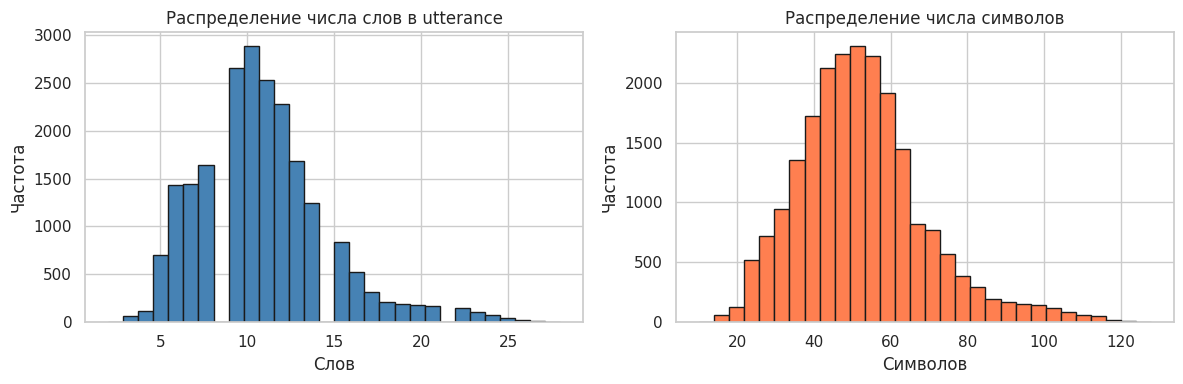

In [ ]:
# @title Ячейка 7: Длины текстов
# @markdown Описательная статистика исходного корпуса, не метрика качества модели.

df['n_words'] = df['utterance'].astype(str).str.split().str.len()
df['n_chars'] = df['utterance'].astype(str).str.len()

display(df[['n_words','n_chars']].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['n_words'], bins=30, color='steelblue', edgecolor='k')
axes[0].set_title('Распределение числа слов в utterance')
axes[0].set_xlabel('Слов'); axes[0].set_ylabel('Частота')

axes[1].hist(df['n_chars'], bins=30, color='coral', edgecolor='k')
axes[1].set_title('Распределение числа символов')
axes[1].set_xlabel('Символов'); axes[1].set_ylabel('Частота')

plt.tight_layout(); plt.show()


In [ ]:
# @title Ячейка 8: Частоты отдельных флагов
# @markdown Одна строка учитывается не более одного раза для каждого флага. Флаги могут пересекаться.

from collections import Counter
all_chars = Counter(flag for codes in parsed_flags for flag in codes)
flag_freq = pd.DataFrame([
    {'flag_char':fc, 'meaning':sc.LINGUISTIC_FLAGS.get(fc, 'UNKNOWN'),
     'n_utterances':int(all_chars.get(fc, 0)),
     'share_of_rows':all_chars.get(fc, 0)/len(df)}
    for fc in sc.LINGUISTIC_FLAGS
]).sort_values('n_utterances', ascending=False).reset_index(drop=True)
display(flag_freq)
print('Сумма долей может быть >100%: у обращения может быть несколько языковых флагов.')


,flag_char,meaning,n_utterances,share_of_rows
0,B,Basic syntactic structure,21534,1.000000
1,L,Lexical variation (synonyms),18752,0.870809
2,I,Interrogative structure,12766,0.592830
3,C,Complex/Coordinated syntactic structure,10911,0.506687
4,Q,Colloquial variation,9552,0.443578
5,Z,"Noise (spelling, punctuation)",3412,0.158447
6,P,Politeness variation,2888,0.134113
7,M,"Morphological variation (plurals, tenses)",2836,0.131699
8,D,Indirect speech,2596,0.120554
9,S,Syntactic structure,1884,0.087490


Сумма долей может быть >100%: у обращения может быть несколько языковых флагов.


**Этап 3. EDA (Разведочный анализ)**

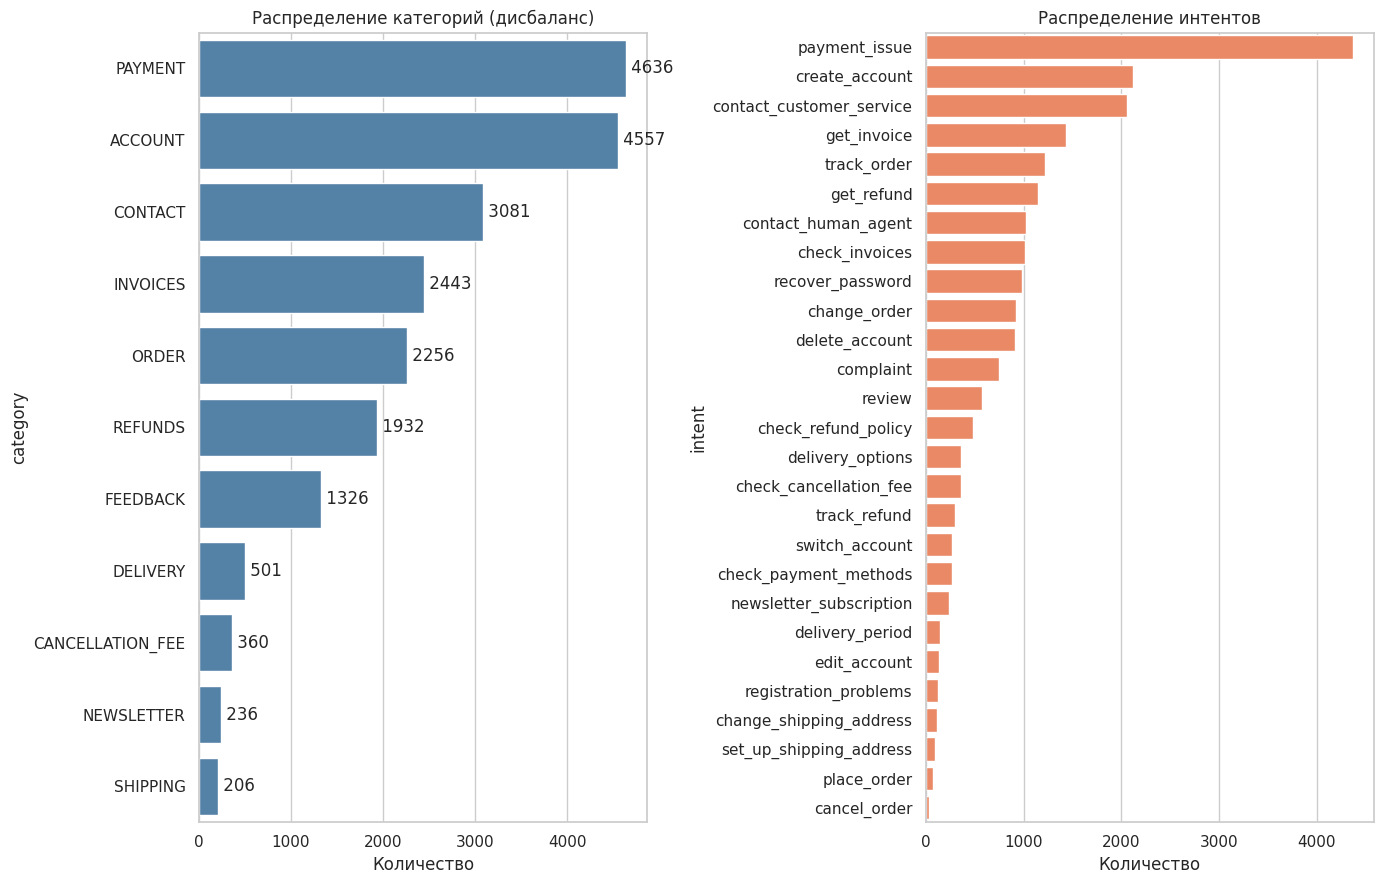

Соотношение самого большого и самого маленького класса: 22.50:1


In [ ]:
# @title Ячейка 9: Распределение категорий и интентов
# @markdown Дисбаланс измеряем по фактическим данным. Он учитывается через macro-F1, recall и поддержку классов.

fig, axes = plt.subplots(1, 2, figsize=(14, 9))
cat_counts = df['category'].value_counts()
sns.barplot(y=cat_counts.index, x=cat_counts.values, ax=axes[0], color='steelblue')
axes[0].set_title('Распределение категорий (дисбаланс)')
axes[0].set_xlabel('Количество')
for i, v in enumerate(cat_counts.values):
    axes[0].text(v, i, f' {v}', va='center')

intent_counts = df['intent'].value_counts()
sns.barplot(y=intent_counts.index, x=intent_counts.values, ax=axes[1], color='coral')
axes[1].set_title('Распределение интентов')
axes[1].set_xlabel('Количество')

plt.tight_layout(); plt.show()

ratio = cat_counts.iloc[0] / cat_counts.iloc[-1]
print(f"Соотношение самого большого и самого маленького класса: {ratio:.2f}:1")


In [ ]:
# @title Ячейка 10: Дубликаты — подробно
# @markdown Промежуточная нормализация lower+strip; окончательная очистка будет в ячейке 20.

df_norm = df.copy()
df_norm['utterance_norm'] = df_norm['utterance'].astype(str).str.lower().str.strip()

# Конфликты на нормализованных данных
conflict_cat = (df_norm.groupby('utterance_norm')['category'].nunique() > 1).sum()
conflict_int = (df_norm.groupby('utterance_norm')['intent'].nunique() > 1).sum()
print(f"Нормализованные дубликаты: {df_norm['utterance_norm'].duplicated().sum()}")
print(f"Конфликты по категории: {conflict_cat}")
print(f"Конфликты по интенту:   {conflict_int}")

# Топ частых дубликатов
top_dup = df_norm['utterance_norm'].value_counts().head(10)
print("\nТоп-10 повторяющихся текстов:")
for text, cnt in top_dup.items():
    print(f"  {cnt}× {text[:80]}")


Нормализованные дубликаты: 1778
Конфликты по категории: 0
Конфликты по интенту:   0

Топ-10 повторяющихся текстов:
  4× i ordered something, how do i change my order?
  4× i purchased an item, what do i have to do to modify my purchase?
  4× i purchased an item, what can i do to modify my purchase?
  3× i ordered something, how can i modify my purchase?
  3× i ordered a product, can i change my order?
  3× i ordered a product, how do i change my order?
  3× i ordered something, how do i modify my order?
  3× i want to know if i can see some bills
  3× i want to see the mail to contact client service
  3× i want to know if i can download a bill


In [ ]:
# @title Ячейка 11: Топ слов и биграмм по категориям
# @markdown EDA CountVectorizer со стоп-словами; обучаемый TF-IDF дальше имеет собственный словарь.

from sklearn.feature_extraction.text import CountVectorizer

def top_ngrams(texts, n=1, top_k=10):
    vec = CountVectorizer(ngram_range=(n, n), stop_words='english').fit(texts)
    sums = vec.transform(texts).sum(axis=0).A1
    vocab = vec.get_feature_names_out()
    return sorted(zip(vocab, sums), key=lambda x: -x[1])[:top_k]

for cat in df['category'].unique()[:4]:  # первые 4 категории для краткости
    sub = df[df['category']==cat]['utterance']
    print(f"\n--- {cat} (n={len(sub)}) ---")
    print("Unigrams:", top_ngrams(sub, 1, 8))
    print("Bigrams: ", top_ngrams(sub, 2, 5))



--- ACCOUNT (n=4557) ---
Unigrams: [('account', np.int64(2760)), ('want', np.int64(1044)), ('user', np.int64(944)), ('online', np.int64(917)), ('create', np.int64(815)), ('profile', np.int64(765)), ('email', np.int64(687)), ('password', np.int64(620))]
Bigrams:  [('user account', np.int64(804)), ('online account', np.int64(753)), ('ask agent', np.int64(350)), ('email address', np.int64(345)), ('single email', np.int64(344))]

--- CANCELLATION_FEE (n=360) ---
Unigrams: [('cancellation', np.int64(343)), ('check', np.int64(95)), ('fee', np.int64(94)), ('penalty', np.int64(93)), ('view', np.int64(89)), ('penalties', np.int64(88)), ('want', np.int64(83)), ('fees', np.int64(82))]
Bigrams:  [('check cancellation', np.int64(91)), ('cancellation fee', np.int64(90)), ('cancellation penalty', np.int64(90)), ('cancellation penalties', np.int64(85)), ('view cancellation', np.int64(78))]

--- CONTACT (n=3081) ---
Unigrams: [('service', np.int64(1367)), ('customer', np.int64(1317)), ('contact', np.i

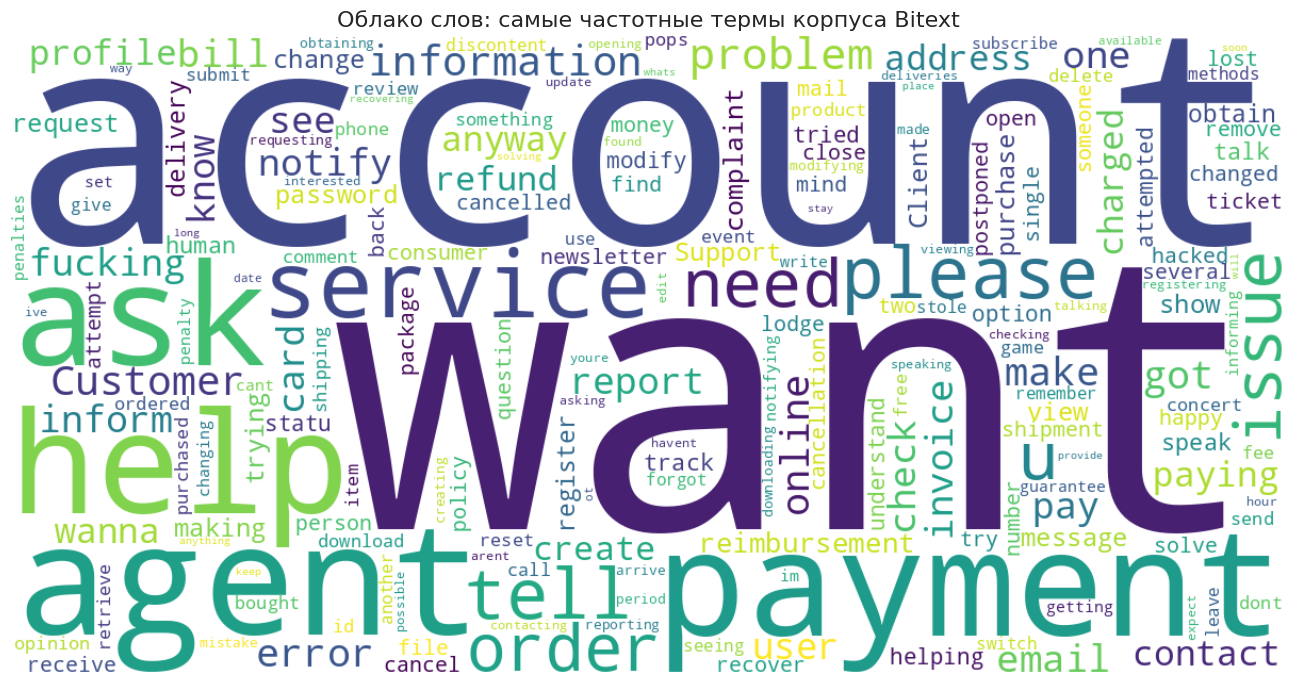

In [ ]:
# @title Ячейка 12: 🌥 ОБЛАКО СЛОВ (добавлено)
# @markdown Описательная статистика исходного корпуса, не метрика качества модели.

from wordcloud import WordCloud

# Собираем весь текст в одну строку
full_text = " ".join(df['utterance'].astype(str).tolist())

# Строим облако
wc = WordCloud(
    width=1200, height=600,
    background_color='white',
    colormap='viridis',
    max_words=200,
    stopwords=None,          # стандартные стоп-слова WordCloud; это только иллюстрация
    collocations=False,
    random_state=SEED,
).generate(full_text)

plt.figure(figsize=(14, 7))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Облако слов: самые частотные термы корпуса Bitext', fontsize=16)
plt.tight_layout(); plt.show()


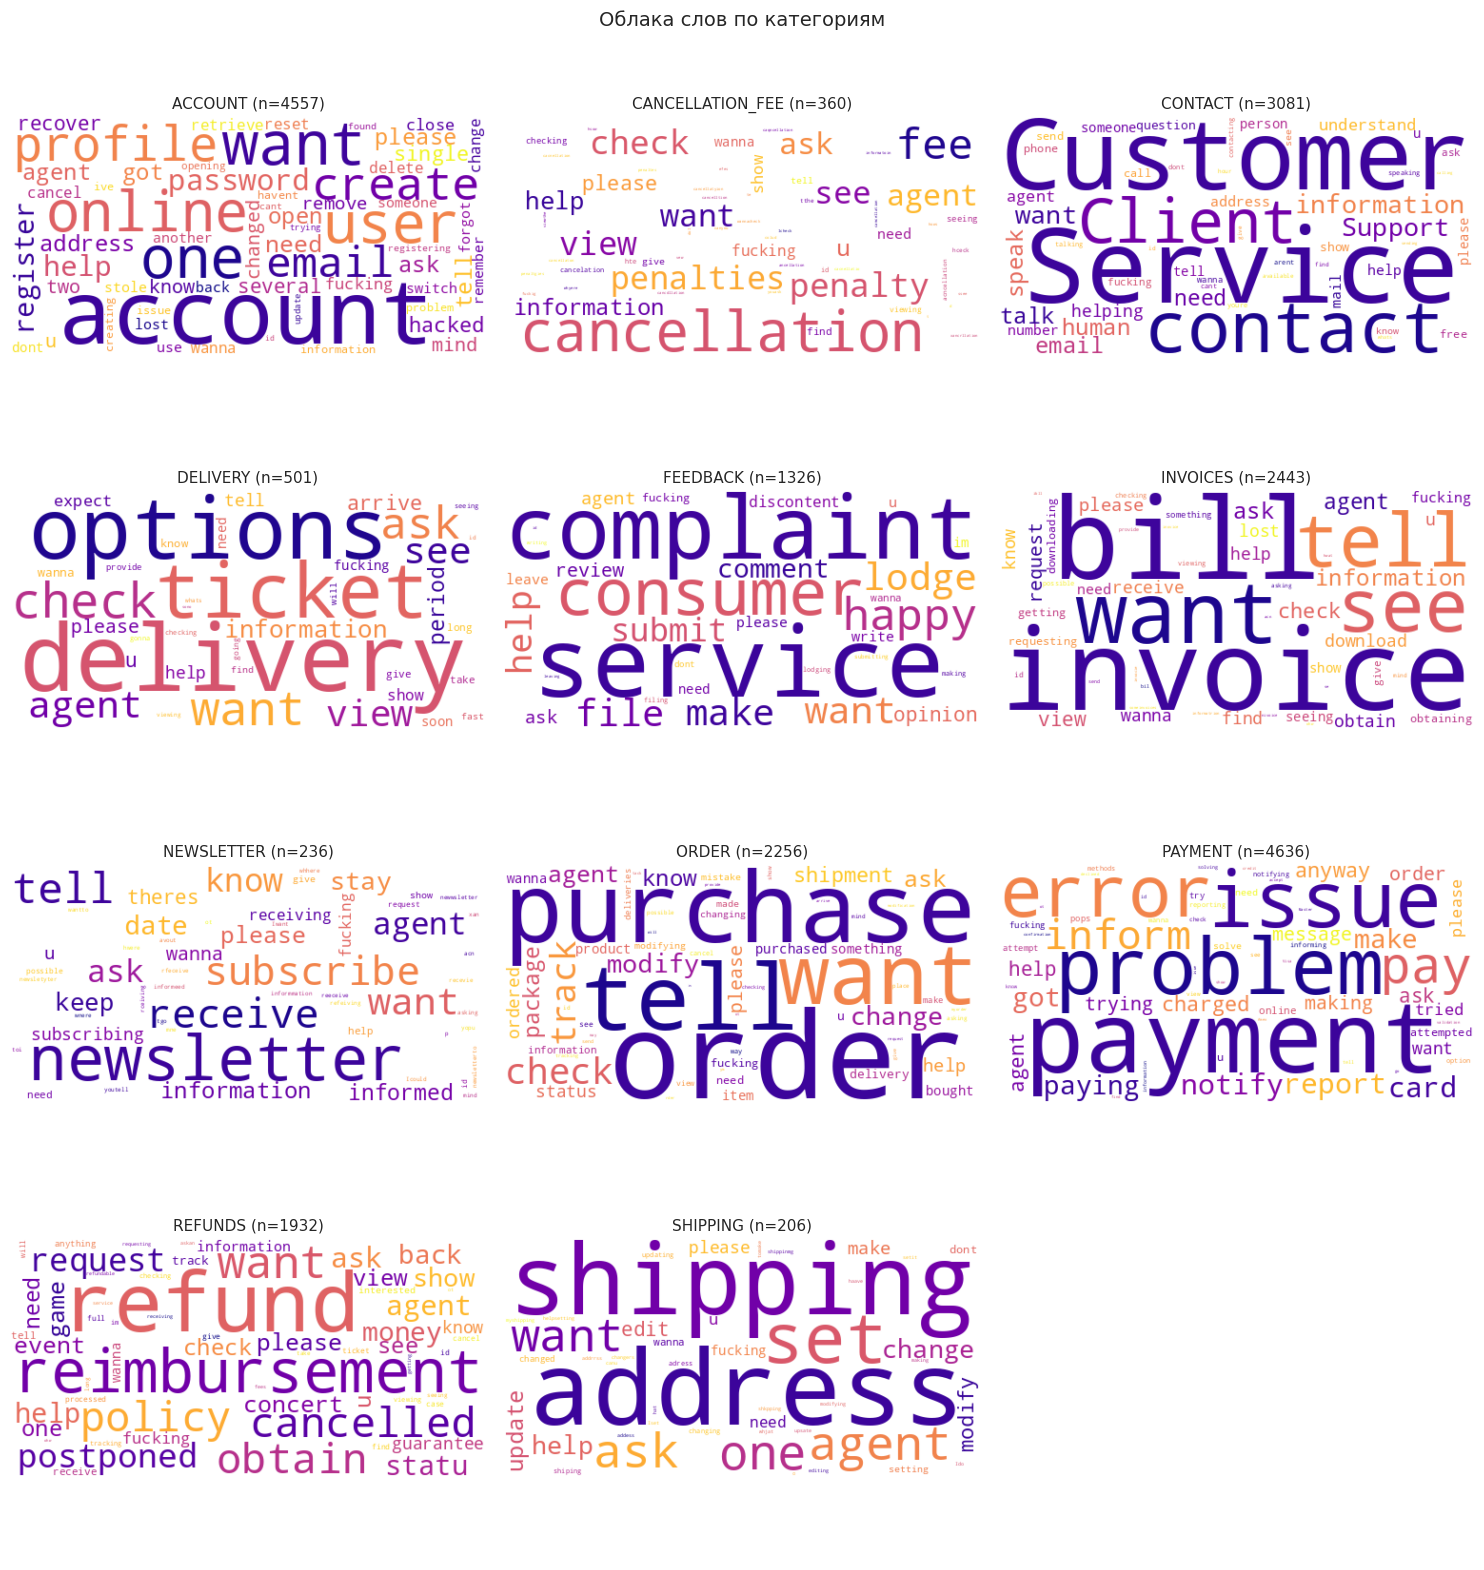

In [ ]:
# @title Ячейка 13: 🌥 Облако слов по классам (добавлено)
# @markdown Описательная статистика исходного корпуса, не метрика качества модели.

from wordcloud import WordCloud

def plot_wordcloud(texts, title, ax):
    full = " ".join(texts.astype(str).tolist())
    if len(full.strip()) == 0:
        ax.set_title(title + " (пусто)"); ax.axis('off'); return
    wc = WordCloud(width=500, height=250, background_color='white',
                   colormap='plasma', max_words=60, collocations=False,
                   random_state=SEED).generate(full)
    ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(title, fontsize=11)

cats = df['category'].unique()
n = len(cats)
n_cols = 3
n_rows = (n + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4*n_rows))
axes = axes.flatten()
for i, cat in enumerate(cats):
    sub = df[df['category']==cat]['utterance']
    plot_wordcloud(sub, f"{cat} (n={len(sub)})", axes[i])
for j in range(i+1, len(axes)):
    axes[j].axis('off')
plt.suptitle('Облака слов по категориям', fontsize=14)
plt.tight_layout(); plt.show()


In [ ]:
# @title Ячейка 14: Доля текстов с ключевыми маркерами
# @markdown str.contains(regex=False) считает подстроки; это EDA, а не правило приоритета или модель.

markers = {
    'payment': 'payment', 'error': 'error', 'account': 'account',
    'invoice': 'invoice', 'order': 'order', 'refund': 'refund',
    'reimbursement': 'reimbursement', 'delivery': 'delivery',
    'address': 'address', 'complaint': 'complaint',
}
texts = df['utterance'].astype(str).str.lower()
pen = pd.DataFrame({m: texts.str.contains(k, regex=False) for m, k in markers.items()})
pen['category'] = df['category'].values
penetration = pen.groupby('category').mean().round(3)
display(penetration)


,payment,error,account,invoice,order,refund,reimbursement,delivery,address,complaint
category,,,,,,,,,,
ACCOUNT,0.000,0.000,0.696,0.000,0.000,0.000,0.000,0.000,0.077,0.000
CANCELLATION_FEE,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
CONTACT,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.103,0.000
DELIVERY,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.838,0.000,0.000
FEEDBACK,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.554
INVOICES,0.000,0.000,0.000,0.489,0.000,0.000,0.000,0.000,0.000,0.000
NEWSLETTER,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
ORDER,0.000,0.000,0.000,0.000,0.442,0.000,0.000,0.061,0.000,0.000
PAYMENT,0.565,0.272,0.000,0.000,0.139,0.000,0.000,0.000,0.000,0.000


In [ ]:
# @title Ячейка 15: Похожие классы (косинусное сходство)
# @markdown Сходство центроидов — лексическая диагностика, не измеренная вероятность ошибки.

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

tfv = TfidfVectorizer(max_features=3000, stop_words='english')
X = tfv.fit_transform(df['utterance'].astype(str))

centroids = {}
for cat in df['category'].unique():
    idx = df['category'].values == cat
    centroids[cat] = np.asarray(X[idx].mean(axis=0)).ravel()

cats = list(centroids)
M = cosine_similarity(np.array([centroids[c] for c in cats]))

pairs = []
for i in range(len(cats)):
    for j in range(i+1, len(cats)):
        pairs.append((cats[i], cats[j], M[i, j]))
pairs_df = pd.DataFrame(pairs, columns=['category_a','category_b','cosine']).sort_values('cosine', ascending=False)
display(pairs_df.head(10).round(3))


,category_a,category_b,cosine
41,INVOICES,ORDER,0.283
20,CONTACT,FEEDBACK,0.236
43,INVOICES,REFUNDS,0.230
40,INVOICES,NEWSLETTER,0.175
30,DELIVERY,ORDER,0.173
50,ORDER,REFUNDS,0.160
13,CANCELLATION_FEE,INVOICES,0.151
21,CONTACT,INVOICES,0.148
4,ACCOUNT,INVOICES,0.143
28,DELIVERY,INVOICES,0.141


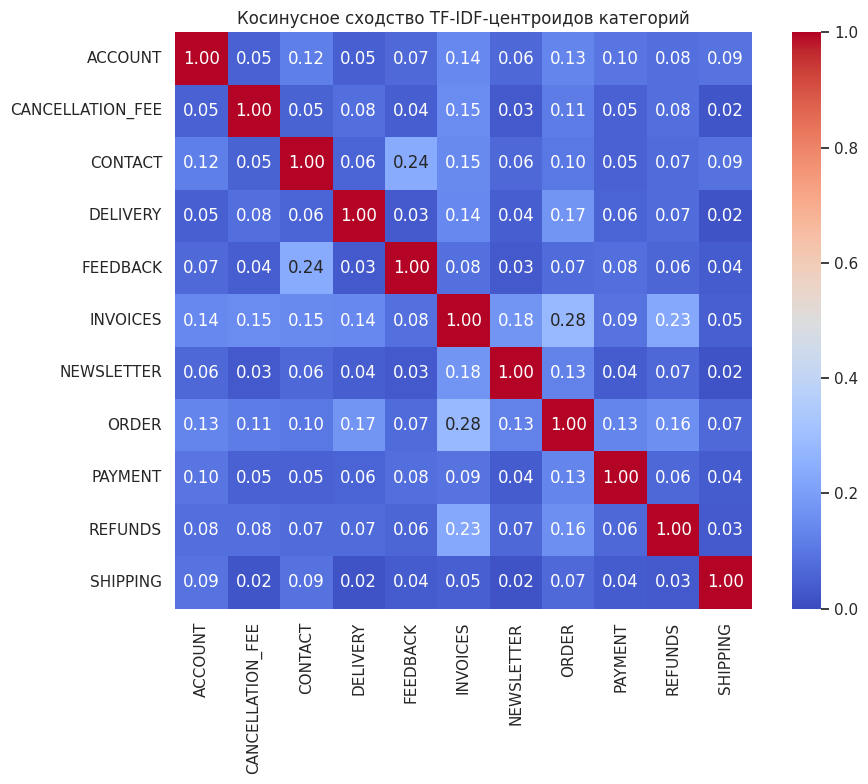

In [ ]:
# @title Ячейка 16: Тепловая карта сходства классов
# @markdown Высокое сходство требует проверки реальной матрицей ошибок; не объявляем пары ошибочными заранее.

plt.figure(figsize=(10, 8))
sns.heatmap(pd.DataFrame(M, index=cats, columns=cats), annot=True, fmt='.2f',
            cmap='coolwarm', vmin=0, vmax=1, square=True)
plt.title('Косинусное сходство TF-IDF-центроидов категорий')
plt.tight_layout(); plt.show()


In [ ]:
# @title Ячейка 17: Флаги по категориям
# @markdown Описательная связь лингвистических flags и категорий. χ² + BH/FDR; не причинная связь.

from scipy.stats import chi2_contingency
flag_chars = list(sc.LINGUISTIC_FLAGS)
rows = []
for fc in flag_chars:
    has_flag = sc.flag_membership(df['flags'], fc)
    ct = pd.crosstab(df['category'], has_flag)
    if ct.shape[1] < 2:
        p, v = float('nan'), float('nan')
    else:
        chi2, p, dof, expected = chi2_contingency(ct)
        n = ct.values.sum()
        v = float(np.sqrt(chi2 / (n * (min(ct.shape) - 1)))) if min(ct.shape) > 1 else float('nan')
    rows.append({'flag': fc, 'meaning':sc.LINGUISTIC_FLAGS[fc],
                 'n_rows_with_flag':int(has_flag.sum()),
                 'share':float(has_flag.mean()),
                 'cramers_v':v,'p_value':p})
flag_assoc = pd.DataFrame(rows)
# Benjamini-Hochberg adjustment across documented flags only.
valid = flag_assoc['p_value'].notna()
p_values = flag_assoc.loc[valid, 'p_value'].to_numpy(float)
if len(p_values):
    order = np.argsort(p_values)
    sorted_p = p_values[order]
    adjusted_sorted = np.minimum.accumulate((sorted_p * len(p_values) /
                           np.arange(1, len(p_values) + 1))[::-1])[::-1]
    adjusted = np.empty_like(p_values)
    adjusted[order] = np.minimum(1.0, adjusted_sorted)
    flag_assoc.loc[valid, 'p_fdr_bh'] = adjusted
flag_assoc = flag_assoc.sort_values('cramers_v', ascending=False)
display(flag_assoc)
print('Связи с категориями описывают структуру Bitext и НЕ подтверждают причинное влияние флага на качество.')


,flag,meaning,n_rows_with_flag,share,cramers_v,p_value,p_fdr_bh
3,M,"Morphological variation (plurals, tenses)",2836,0.131699,0.422072,0.000000e+00,0.000000e+00
1,S,Syntactic structure,1884,0.087490,0.391414,0.000000e+00,0.000000e+00
5,C,Complex/Coordinated syntactic structure,10911,0.506687,0.268414,0.000000e+00,0.000000e+00
2,L,Lexical variation (synonyms),18752,0.870809,0.178572,4.542414e-141,1.249164e-140
10,D,Indirect speech,2596,0.120554,0.131077,2.278700e-73,5.013140e-73
4,I,Interrogative structure,12766,0.592830,0.110722,6.170582e-51,1.131273e-50
9,E,Expanded abbreviations,392,0.018204,0.106678,5.927337e-47,9.314387e-47
7,Q,Colloquial variation,9552,0.443578,0.068472,3.500819e-17,4.813627e-17
6,P,Politeness variation,2888,0.134113,0.017669,7.513585e-01,8.670247e-01
11,Z,"Noise (spelling, punctuation)",3412,0.158447,0.017124,7.882043e-01,8.670247e-01


Связи с категориями описывают структуру Bitext и НЕ подтверждают причинное влияние флага на качество.


### Выводы по этапам 2–3

EDA описывает **шаблонный англоязычный Bitext**, а не реальные обращения магазина. По [официальной карточке Bitext 2020](https://www.kaggle.com/datasets/bitext/training-dataset-for-chatbotsvirtual-assistants/metadata) подтверждены **12 кодов**: B (базовый синтаксис), S (синтаксис), L (лексическая вариативность), M (морфология), I (вопросы), C (сложные/сочинённые конструкции), P (вежливость), Q (разговорность), W (грубая лексика), E (развёрнутые сокращения), D (косвенная речь), Z (шум/опечатки/пунктуация).

Коды могут встречаться совместно. **Z — не автоматически OOD**, **W — не автоматически P1**, а C **не является разметкой нескольких независимых запросов**. Исследование флагов выявляет срезы ошибок, но не доказывает причинную устойчивость модели и не заменяет независимый тест на реальных данных.

**Этап 4. Предобработка и разбиение**

Очистка → char/word-n-gram группы перефразировок и опечаток → непересекающиеся `train/calibration/val/test`. Stratification **приближённая**, поскольку группы нельзя разрезать. Если обнаруживаются очень большие компоненты, код требует проверки. Текст test нельзя использовать для исправления сплита после просмотра метрик.

In [ ]:
# @title Ячейка 18: Очистка данных
# Промежуточная проверка; окончательный набор строит clean_frame в ячейке 20.
preliminary = raw.copy()
preliminary['normalized'] = preliminary.utterance.fillna('').str.lower().str.strip()
print('Дубликаты lower+strip:', preliminary.normalized.duplicated().sum())
print('Пустые/пропущенные:', preliminary.normalized.eq('').sum())
print('Конфликтов категорий:', (preliminary.groupby('normalized').category.nunique() > 1).sum())


Дубликаты lower+strip: 1778
Пустые/пропущенные: 0
Конфликтов категорий: 0


In [ ]:
# @title Ячейка 19: Функция preprocess()
preprocess = sc.preprocess
examples_preprocess = ["I can't log in", 'I can log in', 'Invoice for {{Order Number}}',
                       'Invoice for {Order Number}', 'Invoice for <Order Number>', '  HELLO   there  ']
display(pd.DataFrame({'raw': examples_preprocess, 'normalized': list(map(preprocess, examples_preprocess))}))
assert all(preprocess(preprocess(t)) == preprocess(t) for t in examples_preprocess)
assert preprocess("I can't log in") != preprocess('I can log in')


,raw,normalized
0,I can't log in,i can not log in
1,I can log in,i can log in
2,Invoice for {{Order Number}},invoice for
3,Invoice for {Order Number},invoice for
4,Invoice for <Order Number>,invoice for
5,HELLO there,hello there


In [ ]:
# @title Ячейка 20: Очистка и подготовка к сплиту
d, short, cleaning_info = sc.clean_frame(raw)
display(pd.Series(cleaning_info, name='cleaning'))
display(short[['utterance', 'category', 'intent', 'n_words']])
print('Короткие обращения сохранены. Flags одинаковых нормализованных текстов объединены.')


,cleaning
raw_rows,21534
clean_rows,19700
deduplicated_rows,1834
short_rows_retained,7
flags_policy,union_of_unique_parsed_flags_for_identical_normalized_text
unrecognized_flag_codes,[]
short_policy,retained_in_main_splits_and_reported_as_a_slice


,utterance,category,intent,n_words
1073,can Iregister?,ACCOUNT,create_account,2
3852,registration issue,ACCOUNT,registration_problems,2
3854,registration issues,ACCOUNT,registration_problems,2
3857,registration problem,ACCOUNT,registration_problems,2
6772,contact someone,CONTACT,contact_human_agent,2
12188,change myorder,ORDER,change_order,2
18225,refund policy,REFUNDS,check_refund_policy,2


Короткие обращения сохранены. Flags одинаковых нормализованных текстов объединены.


In [ ]:
# @title Ячейка 21: Разбиение (стратифицированное)
# Исторический заголовок сохранён: групповой split с ПРИБЛИЖЁННОЙ балансировкой классов.
# До разбиения образуем char_wb 3-5 OR word 1-2 группы при порогах 0.85 / 0.90.
# Пороги фиксированы заранее, test используется только после финального выбора.
d['group'], group_info = sc.lexical_groups(d.text.tolist(),threshold=.85)
cluster_sizes=d.group.value_counts()
ambiguous_clusters=d.groupby('group').agg(categories=('category','nunique'),
    intents=('intent','nunique'),rows=('group','size')).query('categories > 1 or intents > 1')
cluster_examples=d[d.group.isin(ambiguous_clusters.index)].sort_values('group')
cluster_examples[['group','text','category','intent']].to_csv(REPORTS_DIR/'mixed_label_groups_review.csv',index=False)
assert cluster_sizes.max()/len(d) < .30, 'Крупная компонента: проверьте случаи переобъединения (mixed_label_groups_review.csv)'
print('Largest groups:',cluster_sizes.head(10).to_dict())
print('Cross-label clusters for manual audit:',len(ambiguous_clusters))
assert sc.lexical_groups(['I need to pay for my roder','I need to pay for my order'],.85)[0][0] == sc.lexical_groups(['I need to pay for my roder','I need to pay for my order'],.85)[0][1]
assert sc.lexical_groups(['problem whlie creating a profile','problem creating a profile'],.85)[0][0] == sc.lexical_groups(['problem whlie creating a profile','problem creating a profile'],.85)[0][1]
splits = sc.make_splits(d)
train,calibration,val,test=[splits[k] for k in ['train','calibration','val','test']]
display(pd.Series(group_info))
split_summary=pd.DataFrame([{'split':k,'n':len(v),'fraction':len(v)/len(d),
                             'groups':v.group.nunique(),'categories':v.category.nunique()} for k,v in splits.items()])
display(split_summary)
display(pd.DataFrame({k:v.category.value_counts() for k,v in splits.items()}).fillna(0).astype(int))
print('Важно: отсутствие общих компонентов не гарантирует отсутствия смысловых парафразов.')

Largest groups: {2756: 1891, 0: 740, 2753: 700, 879: 568, 1390: 461, 1: 368, 2754: 329, 882: 304, 1316: 277, 2398: 194}
Cross-label clusters for manual audit: 14


,0
method,connected_components_char_wb_3_5_OR_word_1_2
threshold,0.85
views,"{'word_1_2': {'cosine_threshold': 0.9, 'undirected_edges': 6147, 'vocabulary': 7774}, 'char_wb_3_5': {'cos..."
n_groups,3646
largest_group,1891
largest_fraction,0.09599
edges_undirected_before_dedup,92263
semantic_equivalence_verified,False
warning,Heuristic groups can overmerge; inspect largest clusters and cross-label groups


,split,n,fraction,groups,categories
0,train,11970,0.607614,2041,11
1,calibration,2240,0.113706,511,11
2,val,2368,0.120203,547,11
3,test,3122,0.158477,547,11


,train,calibration,val,test
category,,,,
ACCOUNT,2395,467,374,920
CANCELLATION_FEE,283,24,24,8
CONTACT,1636,428,315,487
DELIVERY,337,31,58,34
FEEDBACK,873,98,245,50
INVOICES,1092,425,331,405
NEWSLETTER,168,6,18,31
ORDER,1301,419,210,176
PAYMENT,2540,141,585,844


Важно: отсутствие общих компонентов не гарантирует отсутствия смысловых парафразов.


In [ ]:
# @title Ячейка 22: Проверка на утечку (после дедупликации)
overlap_checks=sc.assert_split_integrity(splits)
display(pd.DataFrame(overlap_checks).T)
similarity_checks={}
for name in ['calibration','val','test']:
    summary,pairs=sc.cross_split_similarity(train,splits[name])
    similarity_checks[name]=summary
    pairs.to_csv(REPORTS_DIR/f'similar_train_{name}.csv',index=False)
    print(name,summary)
    display(pairs.head(8))
print('Два пространства диагностики — word и char, обучаются ТОЛЬКО на train.')
print('Если остаются пары ≥0.85, задокументируйте их; НЕ пересоздавайте split по результатам test.')

,text,row_id,group
train__calibration,0,0,0
train__val,0,0,0
train__test,0,0,0
calibration__val,0,0,0
calibration__test,0,0,0
val__test,0,0,0


calibration {'n': 2240, 'mean': 0.7739931260444353, 'p95': 0.8616469308924349, 'n_ge_085': 180, 'n_ge_090': 30, 'method': 'train-only max(word_1_2, char_wb_3_5)', 'warning': 'Residual lexical similarity remains possible; never prove semantic disjointness'}


,cosine_max_views,train_text,heldout_text
0,0.989225,"i do not want my online account, can i close it?","i do not want my online account, whqt can i do to close it?"
1,0.978560,help me contact customer service,"i have a queestion, help me contact customer service"
2,0.978059,"i have an issue making an payment with card, what do i have to do to notify it?","i have an issue making a payment with card, whgat do i have to do to notify it?"
3,0.973933,"i dont have a shipping address, what can i do to set it up?","i dont have a shipping address, canu set it up?"
4,0.970705,"my account was hacked, help me recover it","my usr account was hacked, help me recover it"
5,0.950746,can u ask an agent how i can view my invoices?,canu ask an agent if i can view my invoices?
6,0.949308,"my online account's been hacked, how do i recover it?","my online account's been hacked, how can irecover it?"
7,0.947272,ask an agent to check the cancellation penalty,ask an agent how i can checvk the cancellation penalty


val {'n': 2368, 'mean': 0.7776447967259432, 'p95': 0.8699650930170907, 'n_ge_085': 228, 'n_ge_090': 49, 'method': 'train-only max(word_1_2, char_wb_3_5)', 'warning': 'Residual lexical similarity remains possible; never prove semantic disjointness'}


,cosine_max_views,train_text,heldout_text
0,0.997764,"i want to track my packages, tell me how to do it","i want to track my packages, tell me how i axn do it"
1,0.992892,tell me where to download a bill,can tou tell me where to download a bill?
2,0.984482,help me speak with client service,"i have a questgion, help me speak with client service"
3,0.984480,can you tell me where to subscribe to the newsletter?,can you tell me whhere i can subscribe to the newsletter?
4,0.977521,"i have an issue when trying to pay for my order, what can i do?","i have an issue when trying to pay for my order, shat can i do?"
5,0.975065,"i want to check my package, tell me how i can do it","i want to check my package, tell me hopw to do it"
6,0.973765,i want to know if i can request some invoices,i want toknow if i can request some invoices
7,0.973221,"i changed my mind, can you delete my account?","i changed my mind, can you delete my usef account?"


test {'n': 3122, 'mean': 0.7799559681225868, 'p95': 0.8810670102942474, 'n_ge_085': 448, 'n_ge_090': 56, 'method': 'train-only max(word_1_2, char_wb_3_5)', 'warning': 'Residual lexical similarity remains possible; never prove semantic disjointness'}


,cosine_max_views,train_text,heldout_text
0,0.975355,how to obtain a bill,i want toknow how to obtain a bill
1,0.970079,"i want to track my orders, tell me where to do it","i want to track my orders, tell me wherei can do it"
2,0.969025,"i do not want my account, what should i do to remove it?","i do not want my usaer account, what should i do to remove it?"
3,0.968354,"i have an issue when trying to pay with card, how can i notify it?","i have an issue when trying to pau with card, how can i notify it?"
4,0.964646,"you're not helping, what can i do to contact a human?","you're not helping, what xhould i do to contact a human?"
5,0.962262,"i have not got an account, can you open one?","i have not got an noline account, can you open one?"
6,0.959427,"i want information, i need help talking to customer service","i want information, i need help talking to customer suppoort"
7,0.954184,i have an issue when trying to make a payment with card and i want to inform of it,i have an issue when trying to mke an payment with card and i want to inform of it


Два пространства диагностики — word и char, обучаются ТОЛЬКО на train.
Если остаются пары ≥0.85, задокументируйте их; НЕ пересоздавайте split по результатам test.


In [ ]:
# @title Ячейка 23: Сохранение сплитов
for name, frame in splits.items():
    frame.to_csv(PROCESSED_DIR/f'{name}.csv', index=False)
short.to_csv(PROCESSED_DIR/'short_examples_retained.csv', index=False)
split_manifest = {'seed': SEED, 'raw_sha256': sc.sha256_file(raw_path),
                  'cleaning': cleaning_info, 'grouping': group_info,
                  'overlap_checks': overlap_checks, 'similarity_checks': similarity_checks,
                  'roles': {'train':'model selection and fitting', 'calibration':'sigmoid calibration only',
                            'val':'routing policy selection', 'test':'final in-corpus evaluation'},
                  'splits': {k:{'rows':len(v), 'sha256':sc.sha256_file(PROCESSED_DIR/f'{k}.csv'),
                                 'class_counts':v.category.value_counts().to_dict()} for k,v in splits.items()}}
sc.write_json(PROCESSED_DIR/'split_manifest.json', split_manifest)
print('Сохранены четыре CSV и проверяемый манифест.')


Сохранены четыре CSV и проверяемый манифест.


### 📝 Выводы по этапу 4

Группы строятся по `char_wb` 3–5 и word 1–2, чтобы опечатки вроде `roder/order` и `whlie/while` не проходили в разные выборки. Проверка высокой близости выполняется отдельным train-only пространством, в отчёте сохраняются оставшиеся пары ≥0.85. Группы — лексическая эвристика, а не гарантия отсутствия смысловых повторов.

# *Этап 5. Baseline*

Все признаки обучаются внутри Pipeline. Диагностики групп/интентов/flags выполняются на train. Validation ниже даёт описательные baseline-метрики, но выбор модели делается только по DEV-LOIO внутри train.


In [ ]:
# @title Ячейка 24: Загрузка сплитов из data/processed
splits = {k:pd.read_csv(PROCESSED_DIR/f'{k}.csv', keep_default_na=False) for k in ['train','calibration','val','test']}
train, calibration, val, test = [splits[k] for k in ['train','calibration','val','test']]
sc.assert_split_integrity(splits)
print({k: len(v) for k,v in splits.items()})


{'train': 11970, 'calibration': 2240, 'val': 2368, 'test': 3122}


In [ ]:
# @title Ячейка 25: DummyClassifier — нижняя граница
from sklearn.dummy import DummyClassifier
dummy = DummyClassifier(strategy='most_frequent').fit(np.zeros((len(train),1)), train.category)
dummy_pred = dummy.predict(np.zeros((len(val),1)))
dummy_metrics = sc.classification_metrics(val.category, dummy_pred)
print('Dummy на val:', {k:dummy_metrics[k] for k in ['accuracy','macro_f1','errors']})


Dummy на val: {'accuracy': 0.24704391891891891, 'macro_f1': 0.03601884062432657, 'errors': 1783}


In [ ]:
# @title Ячейка 26: Baseline — TF-IDF + LogisticRegression
BASELINE_NAME = 'lr_word (baseline)'
def make_lr_baseline(): return sc.make_model(BASELINE_NAME)
baseline = sc.fit_model(BASELINE_NAME, train)
base_val_metrics = sc.classification_metrics(val.category, baseline.predict(val.text.tolist()))
display(pd.DataFrame(base_val_metrics['report']).T)
print('Pipeline использует только текст; class_weight=balanced. Val не используется для fitting.')


,precision,recall,f1-score,support
ACCOUNT,0.989390,0.997326,0.993342,374.000000
CANCELLATION_FEE,1.000000,1.000000,1.000000,24.000000
CONTACT,1.000000,0.968254,0.983871,315.000000
DELIVERY,1.000000,1.000000,1.000000,58.000000
FEEDBACK,1.000000,1.000000,1.000000,245.000000
INVOICES,0.996979,0.996979,0.996979,331.000000
NEWSLETTER,0.642857,1.000000,0.782609,18.000000
ORDER,0.981308,1.000000,0.990566,210.000000
PAYMENT,0.998276,0.989744,0.993991,585.000000
REFUNDS,0.982857,0.977273,0.980057,176.000000


Pipeline использует только текст; class_weight=balanced. Val не используется для fitting.


In [ ]:
# @title Ячейка 27: Топ-признаки по классам
feature_names = baseline.named_steps['features'].get_feature_names_out()
clf = baseline.named_steps['clf']
top_features = []
for j, category in enumerate(clf.classes_):
    idx = np.argsort(clf.coef_[j])[-8:][::-1]
    top_features.append({'category': category, 'positive_terms': ', '.join(feature_names[idx])})
display(pd.DataFrame(top_features))
print('Коэффициенты линейной модели: связь с решением, не причинное объяснение.')


,category,positive_terms
0,ACCOUNT,"account, profile, password, my profile, register, user, create, online"
1,CANCELLATION_FEE,"cancellation, the cancellation, penalties, fees, penalty, fee, the, cancellation penalties"
2,CONTACT,"customer, contact, service, client, human, client service, support, customer service"
3,DELIVERY,"delivery, options, the delivery, ticket, delivery options, the, options for, arrive"
4,FEEDBACK,"complaint, comment, review, leave, service, lodge, write, the service"
5,INVOICES,"bill, invoice, bills, some, invoices, an invoice, my bills, my invoices"
6,NEWSLETTER,"newsletter, the newsletter, receive, newsletter can, subscribe, subscribe to, receive the, to the"
7,ORDER,"order, purchase, my, my order, my purchase, track my, check my, package"
8,PAYMENT,"payment, paying, problem, report, notify, issue, pay, problems"
9,REFUNDS,"reimbursement, refund, policy, was, my refund, money, money back, my reimbursement"


Коэффициенты линейной модели: связь с решением, не причинное объяснение.


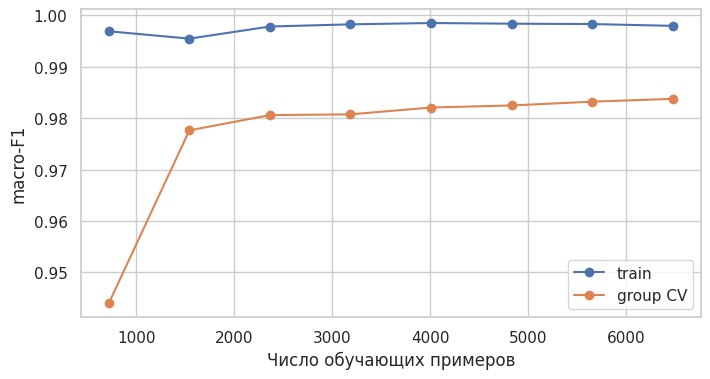

Векторизатор заново обучается внутри каждого фолда; группы не пересекаются с валидацией.


In [ ]:
# @title Ячейка 28: Кривая обучения (bias/variance)
from sklearn.model_selection import learning_curve, StratifiedGroupKFold
cv = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED).split(train.text, train.category, train.group))
with threadpool_limits(limits=1):
    sizes, train_scores, cv_scores = learning_curve(make_lr_baseline(), train.text.tolist(), train.category,
        cv=cv, train_sizes=np.linspace(.1,.9,8), scoring='f1_macro', n_jobs=1, shuffle=True, random_state=SEED,
        error_score='raise')
plt.figure(figsize=(8,4))
plt.plot(sizes, train_scores.mean(1), 'o-', label='train')
plt.plot(sizes, cv_scores.mean(1), 'o-', label='group CV')
plt.xlabel('Число обучающих примеров'); plt.ylabel('macro-F1'); plt.legend(); plt.show()
print('Векторизатор заново обучается внутри каждого фолда; группы не пересекаются с валидацией.')


In [ ]:
# @title Ячейка 29: GroupSplit — разбиение по группам перефразировок
# Holdout целых групп, а не тест только на одиночках. Внешние val/test не участвуют.
tr_gs, te_gs = sc.balanced_group_holdout(train, .20, seed=99)
assert not set(tr_gs.group) & set(te_gs.group)
baseline_gs = sc.fit_model(BASELINE_NAME, tr_gs)
base_group_metrics = sc.classification_metrics(te_gs.category, baseline_gs.predict(te_gs.text.tolist()))
print('Group diagnostic:', {'train':len(tr_gs), 'heldout':len(te_gs), 'macro_f1':base_group_metrics['macro_f1']})


Group diagnostic: {'train': 9838, 'heldout': 2132, 'macro_f1': 0.9951054725472616}


In [ ]:
# @title Ячейка 30: clean → noisy по флагам
# @markdown Историческое название: это не контролируемое превращение clean→noisy, а однокорпусной FLAG-HOLDOUT.
# @markdown Флаги могут пересекаться; категории и интенты не сбалансированы между подвыборками.
FLAG_MEANINGS = sc.LINGUISTIC_FLAGS  # Все 12 кодов из Bitext datacard, не только Z/Q/W/M/E/S.
def flag_diagnostic(frame, model_name):
    rows = []
    for flag, meaning in FLAG_MEANINGS.items():
        mask = sc.flag_membership(frame['flags'], flag)
        te = frame[mask]
        tr = frame[~mask & ~frame.group.isin(te.group)]
        absent_categories = sorted(set(te.category) - set(tr.category))
        row = {'model':model_name,'flag':flag,'meaning':meaning,
               'train':len(tr),'heldout':len(te),
               'heldout_share':len(te)/len(frame),
               'heldout_categories':int(te.category.nunique()),
               'missing_train_categories':absent_categories}
        if len(te) < 30 or tr.category.nunique() < 2 or absent_categories:
            row.update(status='INSUFFICIENT_DATA',macro_f1=None)
        else:
            m = sc.fit_model(model_name, tr)
            # Macro-F1 is defined over all categories in this held-out flagged slice.
            metrics = sc.classification_metrics(te.category,
                m.predict(te.text.tolist()), labels=sorted(te.category.unique()))
            row.update(status='OBSERVATIONAL_FLAG_HOLDOUT', macro_f1=metrics['macro_f1'])
        rows.append(row)
    return pd.DataFrame(rows)
flag_df = flag_diagnostic(train, BASELINE_NAME)
display(flag_df)
print('Срезы пересекаются, поэтому 12 строк нельзя считать независимыми экспериментами.')
print('Z=шум/опечатки, Q=разговорность, W=грубая речь, M=морфология, E=развёрнутые сокращения.')


,model,flag,meaning,train,heldout,heldout_share,heldout_categories,missing_train_categories,status,macro_f1
0,lr_word (baseline),B,Basic syntactic structure,0,11970,1.000000,11,"[ACCOUNT, CANCELLATION_FEE, CONTACT, DELIVERY, FEEDBACK, INVOICES, NEWSLETTER, ORDER, PAYMENT, REFUNDS, SH...",INSUFFICIENT_DATA,NaN
1,lr_word (baseline),S,Syntactic structure,6983,799,0.066750,11,[],OBSERVATIONAL_FLAG_HOLDOUT,0.974968
2,lr_word (baseline),L,Lexical variation (synonyms),627,10378,0.867001,11,[],OBSERVATIONAL_FLAG_HOLDOUT,0.807676
3,lr_word (baseline),M,"Morphological variation (plurals, tenses)",8333,1569,0.131078,7,[],OBSERVATIONAL_FLAG_HOLDOUT,0.815623
4,lr_word (baseline),I,Interrogative structure,1173,7144,0.596825,11,[],OBSERVATIONAL_FLAG_HOLDOUT,0.986642
5,lr_word (baseline),C,Complex/Coordinated syntactic structure,3134,5753,0.480618,11,[],OBSERVATIONAL_FLAG_HOLDOUT,0.968769
6,lr_word (baseline),P,Politeness variation,2284,1790,0.149541,11,[],OBSERVATIONAL_FLAG_HOLDOUT,0.995339
7,lr_word (baseline),Q,Colloquial variation,1149,5259,0.439348,11,[],OBSERVATIONAL_FLAG_HOLDOUT,0.995103
8,lr_word (baseline),W,Offensive language,3873,654,0.054637,11,[],OBSERVATIONAL_FLAG_HOLDOUT,0.995732
9,lr_word (baseline),E,Expanded abbreviations,6759,249,0.020802,10,[],OBSERVATIONAL_FLAG_HOLDOUT,1.000000


Срезы пересекаются, поэтому 12 строк нельзя считать независимыми экспериментами.
Z=шум/опечатки, Q=разговорность, W=грубая речь, M=морфология, E=развёрнутые сокращения.


In [ ]:
# @title Ячейка 31: LOIO — Leave-Intent-Out (главный честный тест)
DEV_INTENTS, DIAG_INTENTS, loio_excluded = sc.intent_protocol(train)
print('DEV-интенты (без повторных seed):', DEV_INTENTS)
print('Оставшиеся диагностические интенты:', len(DIAG_INTENTS))
print('Категории с одним интентом: обычный LOIO невозможен без удаления всего класса.')
display(loio_excluded)
base_dev_rows, base_dev_preds = sc.loio_evaluate(train, BASELINE_NAME, DEV_INTENTS)
display(base_dev_rows)
print('Средний recall по DEV-интентам:', base_dev_rows.recall.mean())


DEV-интенты (без повторных seed): ['get_invoice', 'payment_issue', 'delete_account', 'review', 'edit_account', 'track_refund', 'registration_problems', 'check_refund_policy', 'contact_customer_service', 'check_payment_methods']
Оставшиеся диагностические интенты: 15
Категории с одним интентом: обычный LOIO невозможен без удаления всего класса.


,category,intent
2395,CANCELLATION_FEE,check_cancellation_fee
6616,NEWSLETTER,newsletter_subscription


,intent,n_train,n_test,remaining_class_train_n,class_starvation_warning,category,status,recall,n_groups_removed,n_training_rows_removed_for_group_overlap
0,get_invoice,11245,690,367,False,INVOICES,PASS,0.478261,2,35
1,payment_issue,9591,2379,161,True,PAYMENT,PASS,0.530475,0,0
2,delete_account,11490,475,1915,False,ACCOUNT,PASS,0.987368,2,5
3,review,11632,338,535,False,FEEDBACK,PASS,0.721893,0,0
4,edit_account,11868,102,2293,False,ACCOUNT,PASS,0.970588,0,0
5,track_refund,11584,240,840,False,REFUNDS,PASS,0.033333,2,146
6,registration_problems,11882,88,2307,False,ACCOUNT,PASS,0.522727,0,0
7,check_refund_policy,11742,228,997,False,REFUNDS,PASS,0.298246,0,0
8,contact_customer_service,10768,1202,434,False,CONTACT,PASS,0.440100,0,0
9,check_payment_methods,11809,161,2379,False,PAYMENT,PASS,0.285714,0,0


Средний recall по DEV-интентам: 0.5268706345948238


In [ ]:
# @title Ячейка 32: Итоговая таблица baseline
baseline_overview = pd.DataFrame([
    {'protocol':'val', 'metric':'macro_f1', 'value':base_val_metrics['macro_f1']},
    {'protocol':'group holdout within train', 'metric':'macro_f1', 'value':base_group_metrics['macro_f1']},
    {'protocol':'DEV LOIO within train', 'metric':'mean_intent_recall', 'value':base_dev_rows.recall.mean()}])
display(baseline_overview)
print('Эти протоколы отвечают на разные вопросы; средний recall одного интента не называем macro-F1.')


,protocol,metric,value
0,val,macro_f1,0.973231
1,group holdout within train,macro_f1,0.995105
2,DEV LOIO within train,mean_intent_recall,0.526871


Эти протоколы отвечают на разные вопросы; средний recall одного интента не называем macro-F1.


### 📝 Выводы по этапу 5

Baseline и диагностики измеряются на разных срезах: `val` — внутридатасетная проверка, GroupSplit — новые лексические группы, LOIO — исключённый интент при сохранённом классе. Когда `payment_issue` составляет почти весь PAYMENT, оставшееся обучение «голодает»: recall в этом фолде нельзя приравнять к оценке настоящего нового интента. Исходный test остаётся закрыт до этапа 7.

# **Этап 6. Улучшение модели**

Сравниваются **11 названий / 10 различимых LOIO-моделей на всех 25 допустимых интентах**. Авторские 33 DEV и 8 обучающих фраз не получают никакого веса в ранжировании; `semantic_aug_lr` и `semantic_lr` идентичны в честном LOIO и это явно показывается. Нестабильность по интентам оценивается 2000 парными bootstrap-пересэмплированиями интентов. Разработка на 25 интентах не является независимым доказательством обобщения.

In [ ]:
# @title Ячейка 33: Фабрики моделей (8 конфигураций)
# Историческое название сохранено: реально 11 имен, 10 различимых LOIO-протоколов.
from functools import partial
CONFIGS={name:partial(sc.make_model,name) for name in sc.CONFIG_NAMES}
manual_dev,manual_holdout=manual_cases.frames()
manual_dev.to_csv(REPORTS_DIR/'manual_dev_cases.csv',index=False)
manual_holdout.to_csv(REPORTS_DIR/'manual_holdout_cases.csv',index=False)
added_training=pd.DataFrame(category_examples.EXAMPLES)
added_training.to_csv(PROCESSED_DIR/'supplemental_training_examples.csv',index=False)
all_authored=pd.concat([manual_dev,manual_holdout,added_training],ignore_index=True)
assert not all_authored.text.map(sc.preprocess).duplicated().any()
assert not set(all_authored.text.map(sc.preprocess)) & set(d.text)
print('Авторские 33 DEV + 33 HOLDOUT + 8 TRAIN не независимы по источнику/авторству.')
print('8 примеров отписки не включены в LOIO и НЕ могут решить выбор модели. Они также не используются финальным победителем по умолчанию.')
display(pd.DataFrame([{'model':name,'classifier':type(factory().named_steps['clf']).__name__,
    'features':type(factory().named_steps['features']).__name__} for name,factory in CONFIGS.items()]))

Авторские 33 DEV + 33 HOLDOUT + 8 TRAIN не независимы по источнику/авторству.
8 примеров отписки не включены в LOIO и НЕ могут решить выбор модели. Они также не используются финальным победителем по умолчанию.


,model,classifier,features
0,lr_word (baseline),LogisticRegression,TfidfVectorizer
1,sgd_w_a1e-4,SGDClassifier,TfidfVectorizer
2,sgd_w_a5e-5,SGDClassifier,TfidfVectorizer
3,sgd_w_a2e-5,SGDClassifier,TfidfVectorizer
4,linsvc_w_C0.5,LinearSVC,TfidfVectorizer
5,linsvc_w_C1,LinearSVC,TfidfVectorizer
6,linsvc_w_C3,LinearSVC,TfidfVectorizer
7,linsvc_wc_C1,LinearSVC,FeatureUnion
8,semantic_lr_C1,LogisticRegression,FrozenSentenceEncoder
9,semantic_svc_C1,LinearSVC,FrozenSentenceEncoder


In [ ]:
# @title Ячейка 34: LOIO-тюнинг по 10 seed × 8 конфигураций (с диагностикой)
# Название унаследовано. Фактически ВСЕ 25 допустимых интентов × 11 названий,
# причем semantic_aug_lr_C1 является идентичным semantic_lr_C1 в LOIO (синтетические TRAIN исключаются).
ALL_LOIO_INTENTS=DEV_INTENTS+DIAG_INTENTS
print('Число допустимых LOIO интентов:',len(ALL_LOIO_INTENTS))
tuning_cache={};tuning_rows=[]
for name in CONFIGS:
    started=time.monotonic()
    if name=='semantic_aug_lr_C1':
        rows,preds=tuning_cache['semantic_lr_C1']
        rows=rows.copy();preds=preds.copy();preds['model']=name
        distinguishable=False
    else:
        rows,preds=sc.loio_evaluate(train,name,ALL_LOIO_INTENTS)
        distinguishable=True
    tuning_cache[name]=(rows,preds)
    assert rows.intent.nunique()==len(ALL_LOIO_INTENTS)
    mean=float(rows.recall.mean())
    tuning_rows.append({'model':name,'mean_intent_recall':mean,
         'std_between_intents':float(rows.recall.std()),
         'standard_error_exploratory':float(rows.recall.std()/np.sqrt(rows.recall.notna().sum())),
         'n_intents':int(rows.recall.notna().sum()),'class_starvation_folds':int(rows.class_starvation_warning.sum()),
         'loio_indistinguishable_from_semantic_lr':not distinguishable,
         'selection_eligible':distinguishable,'seconds':time.monotonic()-started})
    print(name, 'LOIO',round(mean,4),'folds',len(rows),
          'starved',int(rows.class_starvation_warning.sum()),flush=True)
    # Encoder caching, if used, is for frozen pre-trained features only; no test fitting.
    if name.startswith('semantic_'):
        semantic_encoder.save_cache()
tune_df=pd.DataFrame(tuning_rows).sort_values('mean_intent_recall',ascending=False).reset_index(drop=True)
assert set(tune_df.model) == set(sc.CONFIG_NAMES) and tune_df.model.is_unique
assert tune_df.n_intents.eq(len(ALL_LOIO_INTENTS)).all()
tune_df.to_csv(REPORTS_DIR/'loio_all_configurations.csv',index=False)
pd.concat([v[0].assign(model=k) for k,v in tuning_cache.items()]).to_csv(
   REPORTS_DIR/'loio_all_models_per_intent.csv',index=False)
pd.concat([v[1].assign(model=k) for k,v in tuning_cache.items()]).to_csv(
   REPORTS_DIR/'loio_all_models_predictions.csv',index=False)
display(tune_df)
print('ВЫБОР пока не выполнен. Авторский DEV не получает вес 50%.')

In [ ]:
# @title Ячейка 35: Правило выбора модели
# Reference задан до оценки: char+word LinearSVC. Полная таблица LOIO участвует в разработке,
# т.е. bootstrap-интервалы НЕ являются независимой проверкой победителя.
SELECTION_REFERENCE='linsvc_wc_C1'
loio_all_models=pd.concat([v[0].assign(model=k) for k,v in tuning_cache.items()],ignore_index=True)
selection_bootstrap=[sc.paired_intent_bootstrap(loio_all_models,SELECTION_REFERENCE,name,iterations=2000)
     for name in CONFIGS if name!=SELECTION_REFERENCE]
selection_ci_df=pd.DataFrame(selection_bootstrap)
selection_ci_df['ci_lower']=selection_ci_df.paired_delta_ci95.map(lambda z:z[0])
selection_ci_df['ci_upper']=selection_ci_df.paired_delta_ci95.map(lambda z:z[1])
selection_ci_df.to_csv(REPORTS_DIR/'loio_paired_bootstrap.csv',index=False)
observed=tune_df[tune_df.selection_eligible].iloc[0]
if observed.model==SELECTION_REFERENCE:
    best_model_name=SELECTION_REFERENCE
    selection_reason='Reference has highest observable mean on eligible candidates'
else:
    ci=selection_ci_df.set_index('candidate').loc[observed.model]
    if ci.ci_lower>0:
        best_model_name=observed.model
        selection_reason='Exploratory paired-intent CI lower bound above fixed reference'
    else:
        best_model_name=SELECTION_REFERENCE
        selection_reason='Observed difference vs fixed reference overlaps zero; prefer parsimonious reference'
# Distinguishability rule: no author-written extension can win on identical LOIO predictions.
assert best_model_name!='semantic_aug_lr_C1'
selection_record={'selected':best_model_name,'reference':SELECTION_REFERENCE,
   'observed_leader':observed.model,'reason':selection_reason,
   'manual_dev_selection_weight':0,'validation_roles':'25 LOIO intents for development; val for shadow policy; test untouched',
   'not_independent':'Selection and bootstrap both use same 25 intent folds'}
display(selection_ci_df.sort_values('paired_mean_delta',ascending=False))
display(pd.Series(selection_record))
print('Нет выводов о реальном потоке из этой процедуры: 25 интентов внутри Bitext.')

In [ ]:
# @title Ячейка 36: Независимые оценки обобщаемости (LOIO, GroupSplit, clean→noisy) — БЕЗ test
# Исторический заголовок: 25 LOIO использованы для выбора, поэтому они НЕ независимые.
# DEV-10 / remaining-15 сохраняются для воспроизведения ревью, но НЕ являются отложенным тестом.
loio_all={k:v[0] for k,v in tuning_cache.items()}
loio_predictions={k:v[1] for k,v in tuning_cache.items()}
loio_summary=[]
for name, rows in loio_all.items():
    preds=loio_predictions[name]
    metric=sc.classification_metrics(preds.y_true,preds.y_pred,labels=sorted(preds.y_true.unique()))
    dev=rows[rows.intent.isin(DEV_INTENTS)]
    rest=rows[rows.intent.isin(DIAG_INTENTS)]
    loio_summary.append({'model':name,'dev10_mean_recall':float(dev.recall.mean()),
       'remaining15_mean_recall':float(rest.recall.mean()),
       'all25_mean_recall':float(rows.recall.mean()),
       'aggregate_macro_f1_eligible_categories':metric['macro_f1'],
       'n_intents':len(rows),'class_starvation_folds':int(rows.class_starvation_warning.sum()),
       'selection_eligible':name!='semantic_aug_lr_C1'})
loio_summary_df=pd.DataFrame(loio_summary).sort_values('all25_mean_recall',ascending=False)
display(loio_summary_df)
loio_summary_df.to_csv(REPORTS_DIR/'loio_comparison_all_11.csv',index=False)
loio_excluded.to_csv(REPORTS_DIR/'loio_single_intent_categories.csv',index=False)
comparison_names=list(dict.fromkeys([BASELINE_NAME,'linsvc_wc_C1',best_model_name]))
group_rows=[]
for name in comparison_names:
    m=sc.fit_model(name,tr_gs)
    group_rows.append({'model':name,**{k:v for k,v in sc.classification_metrics(
       te_gs.category,m.predict(te_gs.text.tolist())).items() if k in ['macro_f1','accuracy','n']}})
group_df=pd.DataFrame(group_rows)
display(group_df)
best_flag_df=flag_diagnostic(train,best_model_name)
display(pd.concat([flag_df,best_flag_df],ignore_index=True))
# Авторские DEV (33) теперь только post-selection диагностика, не критерий.
authored_dev_model=sc.fit_calibrated_bundle(best_model_name,train,calibration)
manual_dev_pred=authored_dev_model.predict(manual_dev.text.tolist())
manual_dev_metrics=sc.classification_metrics(manual_dev.category,manual_dev_pred)
pd.DataFrame({'text':manual_dev.text,'category':manual_dev.category,
              'prediction':manual_dev_pred}).to_csv(REPORTS_DIR/'manual_dev_predictions_selected.csv',index=False)
print('Авторские DEV: верных',len(manual_dev)-manual_dev_metrics['errors'],'/',len(manual_dev),
      'Wilson lower',sc.wilson_lower(len(manual_dev)-manual_dev_metrics['errors'],len(manual_dev)))
print('Это самодельный набор того же автора, НЕЛЬЗЯ считать внешней валидацией.')

# **Этап 7. Финальная оценка, уверенность, маршрутизация**

Обучение — только `train`, calibration — только `calibration`, выбор *shadow* порогов — `val + авторский OOD-dev`; test используется ровно для финального контроля. **Операционная автоматика выключена по умолчанию**: нет 300–500 независимых размеченных реальных ID, ≥200 реальных OOD, P1-метрик и утверждённых потерь ошибок. Shadow — диагностическая симуляция, а не одобрение очереди.

In [ ]:
# @title Ячейка 37: Обучение финальной модели на train+val
# Исторический заголовок сохранён. Fit: только train; calibration: только calibration;
# порог shadow-кандидата: только val и синтетические OOD-dev. Val НЕ используется в fit.
ood_dev,ood_test=scenario_data.frames()
assert not set(ood_dev.text.map(sc.preprocess)) & set(ood_test.text.map(sc.preprocess))
assert not set(pd.concat([ood_dev,ood_test]).text.map(sc.preprocess)) & set(d.text)
final_bundle=sc.fit_calibrated_bundle(best_model_name,train,calibration)
baseline_final=sc.fit_calibrated_bundle(BASELINE_NAME,train,calibration)
policy,policy_table=sc.select_policy(final_bundle,val,ood_dev,
    target_error_upper=.01,min_auto=30,false_auto_cost=25.,review_cost=1.)
assert policy['auto_enabled'] is False
shadow_model=sc.shadow_bundle(final_bundle)
final_bundle.metadata={'split_manifest':split_manifest,'model_selection':selection_record,
   'fit_rows':len(train),'calibration_rows':len(calibration),'policy_rows':len(val),
   'synthetic_ood_dev_rows':len(ood_dev),'training_extension':[],
   'manual_dev_n':len(manual_dev),'manual_holdout_n':len(manual_holdout),
   'operational_auto_enabled':False,'real_external_validation':False,
   'feature_columns':['text'],'excluded_feature_columns':['intent','flags','group','row_id','category'],
   'encoder_revision':semantic_encoder.REVISION if best_model_name.startswith('semantic_') else None}
calibration_val=sc.calibration_diagnostics(final_bundle,val)
final_model=final_router_model=final_bundle
print('Финальная модель:',final_bundle.model_name,final_bundle.model_id)
display(pd.Series(policy))
manual_holdout_routes=sc.batch_route(final_bundle,manual_holdout.text.tolist())
manual_holdout_shadow=sc.batch_route(shadow_model,manual_holdout.text.tolist())
manual_holdout_pred=final_bundle.predict(manual_holdout.text.tolist())
manual_holdout_metrics=sc.classification_metrics(manual_holdout.category,manual_holdout_pred)
manual_holdout_routing=sc.routing_metrics(manual_holdout_routes,manual_holdout.category.to_numpy())
manual_holdout_shadow_routing=sc.routing_metrics(manual_holdout_shadow,manual_holdout.category.to_numpy())
manual_holdout_report=manual_holdout.assign(prediction=manual_holdout_pred,
    deployed_status=[r['status'] for r in manual_holdout_routes],
    shadow_status=[r['status'] for r in manual_holdout_shadow],
    shadow_confidence=[r['confidence'] for r in manual_holdout_shadow],
    shadow_similarity=[r['similarity'] for r in manual_holdout_shadow],
    reasons=[r['reason_codes'] for r in manual_holdout_shadow])
manual_holdout_report.to_csv(REPORTS_DIR/'manual_holdout_predictions.csv',index=False)
display(manual_holdout_report)
print('Авторский HOLDOUT:',len(manual_holdout)-manual_holdout_metrics['errors'],'/',len(manual_holdout),
      'category Wilson lower:',sc.wilson_lower(len(manual_holdout)-manual_holdout_metrics['errors'],len(manual_holdout)))
print('SHADOW coverage',manual_holdout_shadow_routing['coverage'],
      '| реально auto_disabled всегда. Не меняем модель/пороги после просмотра.')

Финальная модель: linsvc_wc_C1 router-dd2742f49d8d41ad


,0
version,selective-v3-shadow
auto_enabled,False
candidate_auto_enabled,True
confidence_threshold,0.85
similarity_threshold,0.45
parameter_status,SHADOW_ONLY_NO_BUSINESS_APPROVAL
target_error_upper,0.01
min_auto_validation,30
assumed_false_auto_cost,25.0
assumed_review_cost,1.0


,text,category,role,source,used_for_training,prediction,deployed_status,shadow_status,shadow_confidence,shadow_similarity,reasons
0,My login credentials no longer work and I need to reset the password.,ACCOUNT,post_selection_diagnostic,author_written,False,ACCOUNT,MANUAL_REVIEW,AUTO_RECOMMENDED,0.986310,0.496318,[CATEGORY_AND_POLICY_ACCEPTED]
1,I want to replace the email associated with my customer profile.,ACCOUNT,post_selection_diagnostic,author_written,False,ACCOUNT,MANUAL_REVIEW,MANUAL_REVIEW,0.522827,0.432992,"[LOW_CONFIDENCE, LOW_TRAINING_SIMILARITY]"
2,Please erase my registered user account.,ACCOUNT,post_selection_diagnostic,author_written,False,ACCOUNT,MANUAL_REVIEW,AUTO_RECOMMENDED,0.996244,0.626804,[CATEGORY_AND_POLICY_ACCEPTED]
3,"Before I cancel, tell me the amount of the cancellation penalty.",CANCELLATION_FEE,post_selection_diagnostic,author_written,False,CANCELLATION_FEE,MANUAL_REVIEW,AUTO_RECOMMENDED,0.984144,0.590431,[CATEGORY_AND_POLICY_ACCEPTED]
4,Do you deduct a cancellation charge when a booking is called off?,CANCELLATION_FEE,post_selection_diagnostic,author_written,False,CANCELLATION_FEE,MANUAL_REVIEW,MANUAL_REVIEW,0.831204,0.374461,"[LOW_CONFIDENCE, LOW_TRAINING_SIMILARITY]"
5,What is the fee for cancelling my reservation?,CANCELLATION_FEE,post_selection_diagnostic,author_written,False,CANCELLATION_FEE,MANUAL_REVIEW,MANUAL_REVIEW,0.586288,0.549210,[LOW_CONFIDENCE]
6,I need a phone number for the customer care team.,CONTACT,post_selection_diagnostic,author_written,False,CONTACT,MANUAL_REVIEW,AUTO_RECOMMENDED,0.984252,0.659138,[CATEGORY_AND_POLICY_ACCEPTED]
7,Could you transfer this chat to a real person from support?,CONTACT,post_selection_diagnostic,author_written,False,CONTACT,MANUAL_REVIEW,AUTO_RECOMMENDED,0.987401,0.524383,[CATEGORY_AND_POLICY_ACCEPTED]
8,How do I reach a human advisor instead of the bot?,CONTACT,post_selection_diagnostic,author_written,False,CONTACT,MANUAL_REVIEW,MANUAL_REVIEW,0.981251,0.406199,[LOW_TRAINING_SIMILARITY]
9,"Before placing a purchase, I want to know the usual delivery timeframe.",DELIVERY,post_selection_diagnostic,author_written,False,ORDER,MANUAL_REVIEW,MANUAL_REVIEW,0.739942,0.489279,[LOW_CONFIDENCE]


Авторский HOLDOUT: 26 / 33 category Wilson lower: 0.6224802241287064
SHADOW coverage 0.36363636363636365 | реально auto_disabled всегда. Не меняем модель/пороги после просмотра.


In [ ]:
# @title Ячейка 38: ЕДИНСТВЕННАЯ оценка на test + McNemar
# Test на Bitext — регрессионный контроль шаблонного корпуса, НЕ независимый реальный поток.
y_test=test.category.to_numpy()
pred_base=baseline_final.predict(test.text.tolist())
pred_best=final_bundle.predict(test.text.tolist())
base_test_metrics=sc.classification_metrics(y_test,pred_base)
test_metrics=sc.classification_metrics(y_test,pred_best)
mcnemar_result=sc.paired_error_test(y_test,pred_base,pred_best)
test_routes=sc.batch_route(final_bundle,test.text.tolist())
test_routing=sc.routing_metrics(test_routes,y_test)
test_shadow_routes=sc.batch_route(shadow_model,test.text.tolist())
test_shadow_routing=sc.routing_metrics(test_shadow_routes,y_test)
display(pd.DataFrame(test_metrics['report']).T)
print('Baseline:',{k:base_test_metrics[k] for k in ['macro_f1','accuracy','errors']})
print('Selected:',{k:test_metrics[k] for k in ['macro_f1','accuracy','errors']})
print('McNemar:',mcnemar_result)
print('Реальная (не включенная) автоматика:',test_routing)
print('Только SHADOW-кандидат (category accuracy):',test_shadow_routing)
print('Насыщенный test не различает модели надёжно. Пояснение: переобученные шаблоны и близкие парафразы.')
test_predictions=test[['row_id','group','utterance','category','intent']].copy()
test_predictions['baseline_prediction']=pred_base
test_predictions['model_prediction']=pred_best
for field in ['category','decision_category','accepted_category','queue','confidence','similarity','status','priority','reason_codes']:
    test_predictions['route_'+field]=[r[field] for r in test_shadow_routes]
test_predictions['deployed_status']=[r['status'] for r in test_routes]
test_predictions.to_csv(REPORTS_DIR/'test_predictions.csv',index=False)
short_test_mask=test.n_words.lt(3).to_numpy()
short_test_metrics={'n':int(short_test_mask.sum()),
    'classification_accuracy':float(np.mean(pred_best[short_test_mask]==y_test[short_test_mask])) if short_test_mask.any() else None,
    'shadow_routing':sc.routing_metrics([r for r,ok in zip(test_shadow_routes,short_test_mask) if ok],
                                  y_test[short_test_mask]) if short_test_mask.any() else None,
    'limitation':'Small corpus slice, not evidence of robust short real customer tickets'}
print('Короткие тексты:',short_test_metrics)

,precision,recall,f1-score,support
ACCOUNT,1.000000,1.000000,1.000000,920.000000
CANCELLATION_FEE,1.000000,1.000000,1.000000,8.000000
CONTACT,1.000000,1.000000,1.000000,487.000000
DELIVERY,1.000000,1.000000,1.000000,34.000000
FEEDBACK,1.000000,1.000000,1.000000,50.000000
INVOICES,1.000000,1.000000,1.000000,405.000000
NEWSLETTER,1.000000,1.000000,1.000000,31.000000
ORDER,1.000000,1.000000,1.000000,176.000000
PAYMENT,1.000000,0.988152,0.994041,844.000000
REFUNDS,0.933775,1.000000,0.965753,141.000000


Baseline: {'macro_f1': 0.9935017511164279, 'accuracy': 0.9948750800768738, 'errors': 16}
Selected: {'macro_f1': 0.996344904462853, 'accuracy': 0.9967969250480462, 'errors': 10}
McNemar: {'a_correct_b_wrong': 0, 'a_wrong_b_correct': 6, 'p_value': 0.03125, 'interpretation': 'paired binary errors, not significance of macro-F1; dependent templates limit inference'}
Реальная (не включенная) автоматика: {'n': 3122, 'automatic_n': 0, 'manual_n': 3122, 'coverage': 0.0, 'manual_rate': 1.0, 'automatic_category_errors': 0, 'accuracy_automatic_category': None, 'automatic_queue_errors': 0, 'accuracy_automatic_queue': None, 'manual_is_not_a_classification_error': True, 'automatic_category_error_upper_wilson_95': None, 'automatic_queue_error_upper_wilson_95': None, 'id_other_decision_rate': 1.0, 'per_category': {'ACCOUNT': {'n': 920, 'coverage': 0.0, 'auto_n': 0, 'auto_category_accuracy': None, 'auto_queue_accuracy': None}, 'CANCELLATION_FEE': {'n': 8, 'coverage': 0.0, 'auto_n': 0, 'auto_category_acc

In [ ]:
# @title Ячейка 39: Bootstrap CI95 для macro-F1
bootstrap_result=sc.paired_group_bootstrap(test,pred_base,pred_best,iterations=2000)
display(pd.Series(bootstrap_result))
print('2000 paired cluster resamples. Это лишь вариация внутри шаблонных лексических групп Bitext.')

,0
iterations,2000
unit,lexical_group
labels,"[ACCOUNT, CANCELLATION_FEE, CONTACT, DELIVERY, FEEDBACK, INVOICES, NEWSLETTER, ORDER, PAYMENT, REFUNDS, SH..."
baseline_ci95,"[0.9770597080975709, 0.998371605660907]"
router_classifier_ci95,"[0.9839223448564336, 1.0]"
paired_delta_ci95,"[0.0006493271272654172, 0.01141020684570383]"
limitation,zero observed errors produce degenerate bootstrap; not a guarantee on new domains


2000 paired cluster resamples. Это лишь вариация внутри шаблонных лексических групп Bitext.


,0
n,2368
confidence_auroc,0.999577
auroc_status,AVAILABLE
log_loss,0.010223
multiclass_brier_sum,0.001749
ece_top_label,0.008716


,bin,n,confidence,accuracy
0,3,1,0.355973,1.0
1,4,1,0.479239,0.0
2,5,3,0.565827,0.0
3,8,2,0.889023,1.0
4,9,2361,0.992547,1.0


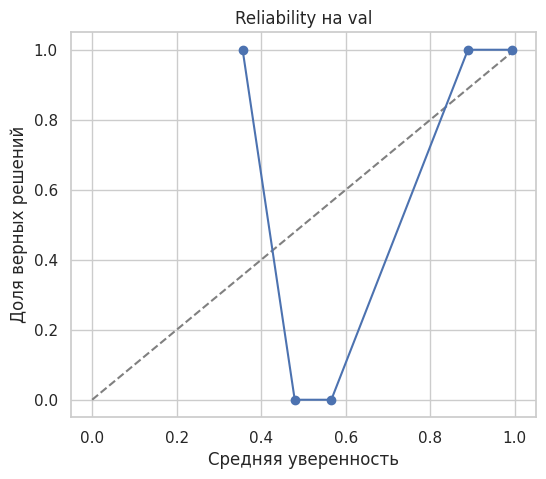

Достаточность вероятностей на реальном потоке не подтверждена этим шаблонным корпусом.


In [ ]:
# @title Ячейка 40: Калибровка уверенности (исправлено)
# Калибратор уже обучен в ячейке 37. Здесь только диагностика той же модели на val.
display(pd.Series({k:v for k,v in calibration_val.items() if k!='bins'}))
reliability = pd.DataFrame(calibration_val['bins'])
display(reliability)
plt.figure(figsize=(6,5)); plt.plot([0,1],[0,1],'--',color='gray')
plt.plot(reliability.confidence, reliability.accuracy, 'o-')
plt.xlabel('Средняя уверенность'); plt.ylabel('Доля верных решений'); plt.title('Reliability на val'); plt.show()
if calibration_val['confidence_auroc'] is None:
    print('AUROC не определён: correctness имеет один класс. Это не означает слабость score.')
print('Достаточность вероятностей на реальном потоке не подтверждена этим шаблонным корпусом.')


,0
version,selective-v3-shadow
auto_enabled,False
candidate_auto_enabled,True
confidence_threshold,0.85
similarity_threshold,0.45
parameter_status,SHADOW_ONLY_NO_BUSINESS_APPROVAL
target_error_upper,0.01
min_auto_validation,30
assumed_false_auto_cost,25.0
assumed_review_cost,1.0


,threshold,similarity_threshold,auto_n,coverage,auto_category_errors,accuracy_covered_category,category_error_upper_wilson_95,ood_dev_false_auto,assumed_cost_per_val,eligible
2,0.5,0.45,2322,0.980574,3,0.998708,0.003792,0,0.051098,True
3,0.5,0.50,2317,0.978463,1,0.999568,0.002441,0,0.032095,True
4,0.5,0.55,2310,0.975507,1,0.999567,0.002448,0,0.035051,True
5,0.5,0.60,2287,0.965794,0,1.000000,0.001677,0,0.034206,True
6,0.5,0.65,2205,0.931166,0,1.000000,0.001739,0,0.068834,True
7,0.5,0.70,1967,0.830659,0,1.000000,0.001949,0,0.169341,True
8,0.5,0.80,752,0.317568,0,1.000000,0.005083,0,0.682432,True
12,0.6,0.45,2319,0.979307,0,1.000000,0.001654,0,0.020693,True
13,0.6,0.50,2316,0.978041,0,1.000000,0.001656,0,0.021959,True
14,0.6,0.55,2309,0.975084,0,1.000000,0.001661,0,0.024916,True


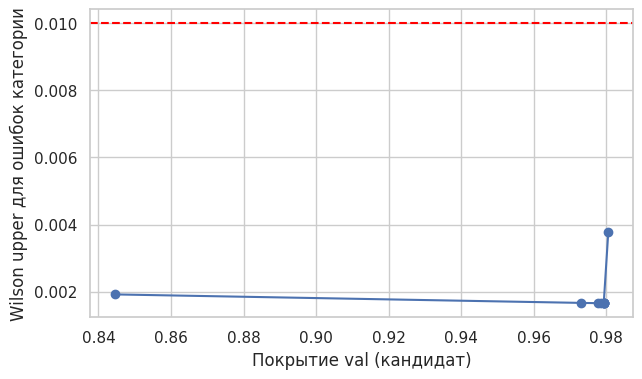

НЕ гарантия ≤1%: интервал вычислен на selection data после перебора сетки, реальные OOD не участвовали.


In [ ]:
# @title Ячейка 41: Порог уверенности для маршрутизации (исправлено)
# Порог кандидата заморожен ДО test; операции AUTO остаются отключены.
display(pd.Series(policy))
display(policy_table[policy_table.eligible].head(15))
policy_table.to_csv(REPORTS_DIR/'policy_validation_grid.csv',index=False)
if policy['candidate_auto_enabled']:
    part=policy_table[policy_table.similarity_threshold.eq(policy['similarity_threshold'])]
    plt.figure(figsize=(7,4))
    plt.plot(part.coverage,part.category_error_upper_wilson_95,'o-')
    plt.axhline(policy['target_error_upper'],linestyle='--',color='red')
    plt.xlabel('Покрытие val (кандидат)')
    plt.ylabel('Wilson upper для ошибок категории')
    plt.show()
else:
    print('Ни один shadow-кандидат не прошёл демонстрационный критерий.')
print('НЕ гарантия ≤1%: интервал вычислен на selection data после перебора сетки, реальные OOD не участвовали.')

In [ ]:
# @title Ячейка 42: Синтетический OOD-набор
# Сценарии написаны вручную, не являются данными реальных клиентов.
display(pd.concat([ood_dev, ood_test]).groupby(['role','topic']).size().unstack(fill_value=0))
print('OOD-dev участвует только в выборе политики, OOD-holdout — отдельная синтетическая диагностика.')
print('Исторические 18 OOD сохраняются как регрессионные примеры; модель на них не обучается.')


topic,gibberish,insufficient_context,multiple_requests,off_topic,technical_issue,unsupported_language
role,,,,,,
policy_development,4,4,4,4,4,4
separate_synthetic_diagnostic,4,4,4,4,4,4


OOD-dev участвует только в выборе политики, OOD-holdout — отдельная синтетическая диагностика.
Исторические 18 OOD сохраняются как регрессионные примеры; модель на них не обучается.


In [ ]:
# @title Ячейка 43: OTHER-модель и проверка на OOD (исправлено)
# OTHER означает воздержание, не классификационный класс.
# Отдельно показываем отключённую операционную маршрутизацию и SHADOW false-auto.
ood_holdout_routes=sc.batch_route(final_bundle,ood_test.text.tolist())
ood_holdout_shadow=sc.batch_route(shadow_model,ood_test.text.tolist())
ood_holdout_metrics=sc.routing_metrics(ood_holdout_routes)
ood_shadow_metrics=sc.routing_metrics(ood_holdout_shadow)
ood_shadow_metrics['false_auto_n']=ood_shadow_metrics['automatic_n']
ood_shadow_metrics['false_auto_rate']=ood_shadow_metrics['coverage']
ood_shadow_metrics['wilson_upper_95']=sc.wilson_upper(ood_shadow_metrics['false_auto_n'],len(ood_test))
ood_report=ood_test.copy()
for field in ['suggested_category','confidence','similarity','status','reason_codes']:
    ood_report['shadow_'+field]=[r[field] for r in ood_holdout_shadow]
ood_report['deployed_status']=[r['status'] for r in ood_holdout_routes]
ood_report['false_auto_shadow']=ood_report.shadow_status.eq('AUTO_RECOMMENDED')
display(ood_report)
display(ood_report.groupby('topic').false_auto_shadow.agg(['sum','count','mean']))
legacy_ood_routes=sc.batch_route(final_bundle,scenario_data.LEGACY_OOD)
legacy_ood_shadow=sc.batch_route(shadow_model,scenario_data.LEGACY_OOD)
legacy_ood_metrics=sc.routing_metrics(legacy_ood_routes)
legacy_ood_shadow_metrics=sc.routing_metrics(legacy_ood_shadow)
legacy_ood_shadow_metrics['false_auto_n']=legacy_ood_shadow_metrics['automatic_n']
legacy_ood_shadow_metrics['wilson_upper_95']=sc.wilson_upper(
    legacy_ood_shadow_metrics['automatic_n'],len(scenario_data.LEGACY_OOD))
print('Деплой (auto отключён):',ood_holdout_metrics)
print('Только SHADOW 24 фразы:',ood_shadow_metrics)
print('Только SHADOW legacy 18:',legacy_ood_shadow_metrics)
print('В ревью v2.1 обнаружено 2/24 false-auto на OOD-holdout и 3/18 на legacy; это ИСТОРИЧЕСКИЕ числа, не результат нового прогона.')
print('Regex-сценарии технических проблем пересекаются с авторским набором и не доказывают независимую полноту детектора.')
ood_report.to_csv(REPORTS_DIR/'ood_diagnostic.csv',index=False)

,text,topic,expected_action,synthetic,role,training_use,shadow_suggested_category,shadow_confidence,shadow_similarity,shadow_status,shadow_reason_codes,deployed_status,false_auto_shadow
0,Describe the rules of competitive chess,off_topic,MANUAL,True,separate_synthetic_diagnostic,False,DELIVERY,0.422386,0.343731,MANUAL_REVIEW,"[LOW_CONFIDENCE, LOW_TRAINING_SIMILARITY]",MANUAL_REVIEW,False
1,What causes the northern lights,off_topic,MANUAL,True,separate_synthetic_diagnostic,False,DELIVERY,0.875248,0.300570,MANUAL_REVIEW,[LOW_TRAINING_SIMILARITY],MANUAL_REVIEW,False
2,Suggest exercises for learning the violin,off_topic,MANUAL,True,separate_synthetic_diagnostic,False,DELIVERY,0.893944,0.257006,MANUAL_REVIEW,[LOW_TRAINING_SIMILARITY],MANUAL_REVIEW,False
3,Calculate the area of a circle with radius seven,off_topic,MANUAL,True,separate_synthetic_diagnostic,False,CONTACT,0.579124,0.205814,MANUAL_REVIEW,"[LOW_CONFIDENCE, LOW_TRAINING_SIMILARITY]",MANUAL_REVIEW,False
4,tangerine nebula floppy zigzag aardvark,gibberish,MANUAL,True,separate_synthetic_diagnostic,False,ACCOUNT,0.694997,0.174426,MANUAL_REVIEW,"[LOW_CONFIDENCE, LOW_TRAINING_SIMILARITY]",MANUAL_REVIEW,False
5,refund broccoli spaceship trapezoid,gibberish,MANUAL,True,separate_synthetic_diagnostic,False,REFUNDS,0.995194,0.401924,MANUAL_REVIEW,[LOW_TRAINING_SIMILARITY],MANUAL_REVIEW,False
6,zxzx qvqp lmnr tttx,gibberish,MANUAL,True,separate_synthetic_diagnostic,False,ACCOUNT,0.416494,0.182485,MANUAL_REVIEW,"[LOW_CONFIDENCE, LOW_TRAINING_SIMILARITY]",MANUAL_REVIEW,False
7,delivery pineapple wizard marzipan,gibberish,MANUAL,True,separate_synthetic_diagnostic,False,DELIVERY,0.672335,0.540460,MANUAL_REVIEW,[LOW_CONFIDENCE],MANUAL_REVIEW,False
8,Как восстановить доступ к личному кабинету?,unsupported_language,MANUAL,True,separate_synthetic_diagnostic,False,None,NaN,NaN,MANUAL_REVIEW,"[POSSIBLY_UNSUPPORTED_LANGUAGE, INSUFFICIENT_SUPPORTED_TEXT]",MANUAL_REVIEW,False
9,"Bonjour, je voudrais une copie de ma facture",unsupported_language,MANUAL,True,separate_synthetic_diagnostic,False,None,NaN,NaN,MANUAL_REVIEW,[POSSIBLY_UNSUPPORTED_LANGUAGE],MANUAL_REVIEW,False


,sum,count,mean
topic,,,
gibberish,0,4,0.00
insufficient_context,1,4,0.25
multiple_requests,0,4,0.00
off_topic,0,4,0.00
technical_issue,0,4,0.00
unsupported_language,0,4,0.00


Деплой (auto отключён): {'n': 24, 'automatic_n': 0, 'manual_n': 24, 'coverage': 0.0, 'manual_rate': 1.0, 'automatic_category_errors': None, 'accuracy_automatic_category': None, 'automatic_queue_errors': None, 'accuracy_automatic_queue': None, 'manual_is_not_a_classification_error': True}
Только SHADOW 24 фразы: {'n': 24, 'automatic_n': 1, 'manual_n': 23, 'coverage': 0.041666666666666664, 'manual_rate': 0.9583333333333334, 'automatic_category_errors': None, 'accuracy_automatic_category': None, 'automatic_queue_errors': None, 'accuracy_automatic_queue': None, 'manual_is_not_a_classification_error': True, 'false_auto_n': 1, 'false_auto_rate': 0.041666666666666664, 'wilson_upper_95': 0.2024222624884223}
Только SHADOW legacy 18: {'n': 18, 'automatic_n': 0, 'manual_n': 18, 'coverage': 0.0, 'manual_rate': 1.0, 'automatic_category_errors': None, 'accuracy_automatic_category': None, 'automatic_queue_errors': None, 'accuracy_automatic_queue': None, 'manual_is_not_a_classification_error': True, '

In [ ]:
# @title Ячейка 44: Демо-фразы (заранее зафиксированы)
demo_texts=scenario_data.DEMO
demo_routes=sc.batch_route(final_bundle,[t for t,_ in demo_texts])
demo_shadow=sc.batch_route(shadow_model,[t for t,_ in demo_texts])
demo_df=pd.DataFrame([{'text':t,'expected':expected,
   'suggested_category':r['suggested_category'],'decision_category':r['decision_category'],
   'queue':r['queue'],'confidence':r['confidence'],'status':r['status'],
   'shadow_status':sr['status'],'shadow_reasons':sr['reason_codes']}
   for (t,expected),r,sr in zip(demo_texts,demo_routes,demo_shadow)])
id_mask=demo_df.expected.ne('OTHER')
shadow_id=id_mask&demo_df.shadow_status.eq('AUTO_RECOMMENDED')
demo_metrics={'n':len(demo_df),'id_n':int(id_mask.sum()),
   'id_classification_correct':int((demo_df.loc[id_mask,'suggested_category']==demo_df.loc[id_mask,'expected']).sum()),
   'id_shadow_auto_n':int(shadow_id.sum()),'id_shadow_manual_n':int((id_mask&~shadow_id).sum()),
   'ood_n':int((~id_mask).sum()),
   'ood_shadow_manual_n':int((~id_mask & demo_df.shadow_status.ne('AUTO_RECOMMENDED')).sum())}
display(demo_df)
display(pd.Series(demo_metrics))
explanations=[sc.local_explanation(final_bundle,t) for t,_ in demo_texts[:3]]
display(pd.DataFrame(explanations))
demo_df.to_csv(REPORTS_DIR/'historical_demo.csv',index=False)
print('Ничего не подбирается по историческому демо. Это не независимая выборка.')

,text,expected,suggested_category,decision_category,queue,confidence,status,shadow_status,shadow_reasons
0,I replaced my phone and cannot remember the security answer,ACCOUNT,ACCOUNT,OTHER,Queue_Manual_Review,0.889131,MANUAL_REVIEW,MANUAL_REVIEW,[LOW_TRAINING_SIMILARITY]
1,Our finance team needs the paperwork proving we paid,INVOICES,DELIVERY,OTHER,Queue_Manual_Review,0.782377,MANUAL_REVIEW,MANUAL_REVIEW,"[LOW_CONFIDENCE, LOW_TRAINING_SIMILARITY]"
2,My purchase still has not shown up and I want an update,ORDER,ORDER,OTHER,Queue_Manual_Review,0.934812,MANUAL_REVIEW,AUTO_RECOMMENDED,[CATEGORY_AND_POLICY_ACCEPTED]
3,The cancelled concert money has not come back yet,REFUNDS,REFUNDS,OTHER,Queue_Manual_Review,0.988332,MANUAL_REVIEW,AUTO_RECOMMENDED,[CATEGORY_AND_POLICY_ACCEPTED]
4,I moved across town; future parcels need to go to the new place,SHIPPING,ORDER,OTHER,Queue_Manual_Review,0.289143,MANUAL_REVIEW,MANUAL_REVIEW,[LOW_CONFIDENCE]
5,Please stop the promotional messages that keep arriving,NEWSLETTER,DELIVERY,OTHER,Queue_Manual_Review,0.628622,MANUAL_REVIEW,MANUAL_REVIEW,"[INSUFFICIENT_CONTEXT, LOW_CONFIDENCE, LOW_TRAINING_SIMILARITY]"
6,My bank card is refused each time I try to finish,PAYMENT,REFUNDS,OTHER,Queue_Manual_Review,0.458489,MANUAL_REVIEW,MANUAL_REVIEW,"[LOW_CONFIDENCE, LOW_TRAINING_SIMILARITY]"
7,I would like the details needed to telephone a human,CONTACT,CONTACT,OTHER,Queue_Manual_Review,0.918511,MANUAL_REVIEW,MANUAL_REVIEW,[LOW_TRAINING_SIMILARITY]
8,Which ways are available for delivering the ticket?,DELIVERY,DELIVERY,OTHER,Queue_Manual_Review,0.905209,MANUAL_REVIEW,AUTO_RECOMMENDED,[CATEGORY_AND_POLICY_ACCEPTED]
9,Why am I being asked to pay a charge for cancelling?,CANCELLATION_FEE,PAYMENT,OTHER,Queue_Manual_Review,0.972970,MANUAL_REVIEW,AUTO_RECOMMENDED,[CATEGORY_AND_POLICY_ACCEPTED]


,0
n,15
id_n,10
id_classification_correct,5
id_shadow_auto_n,4
id_shadow_manual_n,6
ood_n,5
ood_shadow_manual_n,5


,status,class,intercept,terms
0,BASE_SCORE_CONTRIBUTIONS_NOT_CAUSAL,ACCOUNT,-0.573641,"[{'term': 'w__remember', 'contribution': 0.08293742056337725}, {'term': 'w__not remember', 'contribution':..."
1,BASE_SCORE_CONTRIBUTIONS_NOT_CAUSAL,DELIVERY,-1.094168,"[{'term': 'w__the', 'contribution': 0.7998672081204689}, {'term': 'c__ ou', 'contribution': -0.03886033010..."
2,BASE_SCORE_CONTRIBUTIONS_NOT_CAUSAL,ORDER,-0.763543,"[{'term': 'w__purchase', 'contribution': 0.19290949846974292}, {'term': 'c__has', 'contribution': 0.098944..."


Ничего не подбирается по историческому демо. Это не независимая выборка.


In [ ]:
# @title Ячейка 45: Сохранение модели и метаданных (исправлено)
artifact_path,artifact_meta=sc.save_bundle(final_bundle,MODELS_DIR,
    test_metrics={'classification':test_metrics,'shadow_routing':test_shadow_routing,
                  'operational_routing':test_routing})
semantic_encoder.save_cache()
# Fresh Python process: explicitly trusted LOCAL artifact created by this notebook.
probe_texts=[t for t,_ in demo_texts]+['I will hurt you','','Помогите с заказом']
sc.write_json(REPORTS_DIR/'parity_inputs.json',probe_texts)
probe_script="""
import json,sys
from pathlib import Path
import support_router as sc
root=Path(sys.argv[1])
m,meta=sc.load_bundle(root/'models',trust_local_artifact=True)
texts=json.loads((root/'reports/parity_inputs.json').read_text(encoding='utf-8'))
out={'probabilities':m.predict_proba(texts).tolist(),'routes':[sc.route_ticket(t,m) for t in texts]}
sc.write_json(root/'reports/fresh_process_predictions.json',out)
"""
env=dict(os.environ,PYTHONPATH=os.pathsep.join([str(PROJECT_DIR/'src'),str(PROJECT_DIR)]))
probe=subprocess.run([sys.executable,'-c',probe_script,str(PROJECT_DIR)],
               cwd=PROJECT_DIR,env=env,capture_output=True,text=True,encoding='utf-8',errors='replace')
if probe.returncode:
    raise RuntimeError('Проверка в отдельном процессе упала:\n'+probe.stderr[-3000:])
fresh=json.loads((REPORTS_DIR/'fresh_process_predictions.json').read_text(encoding='utf-8'))
assert np.allclose(final_bundle.predict_proba(probe_texts),fresh['probabilities'],rtol=0,atol=1e-12)
for text,exported in zip(probe_texts,fresh['routes']):
    live=sc.route_ticket(text,final_bundle)
    for field in ['category','decision_category','accepted_category','queue','status',
                  'confidence','reason_codes','priority','model_id','policy_version']:
        assert live[field]==exported[field],(text,field)
export_check={'fresh_process_parity':True,'n_cases':len(probe_texts),
              'probability_atol':1e-12,'artifact_sha256':artifact_meta['artifact_sha256'],
              'model_id':final_bundle.model_id,'trusted_local_only':True}
sc.write_json(REPORTS_DIR/'export_check.json',export_check)
display(pd.Series(export_check))
print('ВНИМАНИЕ: joblib.load использует pickle; meta SHA рядом с моделью НЕ аутентифицирует источник.')
print('Загружайте только свои локально обученные артефакты. vectorizer включён в RouterBundle.')

fresh_process_parity                                                                True
n_cases                                                                               18
probability_atol                                                                     0.0
artifact_sha256         5feda5f4e6da5d4d31b5defbf304a270b4b35944025e337e6929cfcd164409a0
model_id                                                         router-937116a8646a48e3
trusted_local_only                                                                  True
dtype: object

ВНИМАНИЕ: joblib.load использует pickle; meta SHA рядом с моделью НЕ аутентифицирует источник.
Загружайте только свои локально обученные артефакты. vectorizer включён в RouterBundle.


In [ ]:
# @title Ячейка 46: Сборка results.json (включая независимые оценки)
import xml.etree.ElementTree as ET
# Регрессионные тесты проверяют корректность кода, не качество на живых обращениях.
test_env=dict(os.environ,PYTHONPATH=str(PROJECT_DIR),PYTEST_DISABLE_PLUGIN_AUTOLOAD='1')
test_run=subprocess.run([sys.executable,'-m','pytest','tests','-q',
                         '--junitxml=reports/tests.xml'],cwd=PROJECT_DIR,
                         env=test_env,capture_output=True,text=True,encoding='utf-8',errors='replace')
print(test_run.stdout)
if test_run.returncode:
    print(test_run.stderr)
    raise RuntimeError('Регрессионные тесты не прошли: не создаём ложный успешный results.json')
xml=ET.parse(REPORTS_DIR/'tests.xml').getroot()
suites=[e for e in xml.iter('testsuite')]
regression_tests={k:sum(int(x.attrib.get(k,0)) for x in suites)
                  for k in ['tests','failures','errors','skipped']}
# Внешние файлы, если пользователь предоставил человечески размеченную проверку.
# Никогда не используем эти данные для fit, выбора модели, порогов или повторной сдачи test.
external_validation={'id':{'status':'NOT_PROVIDED','min_required':300},
                     'ood':{'status':'NOT_PROVIDED','min_required':200},
                     'risk_p1':{'status':'NOT_PROVIDED','required':'human labels and recall'}}
real_id_path=PROCESSED_DIR/'real_blind_id.csv'  # columns utterance,category (+ provenance outside file)
real_ood_path=PROCESSED_DIR/'real_blind_ood.csv' # columns utterance
# Real examples must be independent and collected before viewing new results.
if real_id_path.exists():
    real_id=pd.read_csv(real_id_path).fillna('')
    assert {'utterance','category'}.issubset(real_id.columns)
    assert set(real_id.category).issubset(set(sc.CATEGORIES))
    assert len(real_id)>=300 and real_id.utterance.map(sc.preprocess).nunique()==len(real_id)
    assert not set(real_id.utterance.map(sc.text_id)) & set(d.row_id)
    real_id_predictions=final_bundle.predict(real_id.utterance.tolist())
    real_id_shadow=sc.batch_route(shadow_model,real_id.utterance.tolist())
    external_validation['id']={'status':'EVALUATED_USER_SUPPLIED_PROVENANCE_NOT_AUDITED',
       'n':len(real_id),'file_sha256':sc.sha256_file(real_id_path),
       'classification':sc.classification_metrics(real_id.category,real_id_predictions),
       'shadow_routing':sc.routing_metrics(real_id_shadow,real_id.category.to_numpy())}
if real_ood_path.exists():
    real_ood=pd.read_csv(real_ood_path).fillna('')
    assert 'utterance' in real_ood.columns and len(real_ood)>=200
    assert real_ood.utterance.map(sc.preprocess).nunique()==len(real_ood)
    assert not set(real_ood.utterance.map(sc.text_id)) & set(d.row_id)
    real_ood_shadow=sc.batch_route(shadow_model,real_ood.utterance.tolist())
    n_false=sum(r['status']=='AUTO_RECOMMENDED' for r in real_ood_shadow)
    external_validation['ood']={'status':'EVALUATED_USER_SUPPLIED_OOD_LABELS_NOT_AUDITED',
       'n':len(real_ood),'file_sha256':sc.sha256_file(real_ood_path),
       'shadow_false_auto_n':n_false,'shadow_false_auto_rate':n_false/len(real_ood),
       'wilson_upper_95':sc.wilson_upper(n_false,len(real_ood))}
real_risk_path=PROCESSED_DIR/'real_blind_risk.csv'  # columns utterance,risk_label (0/1 expert annotation)
if real_risk_path.exists():
    real_risk=pd.read_csv(real_risk_path).fillna('')
    assert {'utterance','risk_label'}.issubset(real_risk.columns)
    labels=pd.to_numeric(real_risk.risk_label,errors='raise').to_numpy()
    assert set(labels).issubset({0,1}) and len(real_risk)>=100
    assert not set(real_risk.utterance.map(sc.text_id)) & set(d.row_id)
    # Independently annotated risk labels, NOT generated by the same heuristic.
    detections=[sc.detect_signals(t) for t in real_risk.utterance]
    external_validation['risk_p1']={'status':'EVALUATED_USER_SUPPLIED_LABELS_NOT_AUDITED',
        'n':len(real_risk),'file_sha256':sc.sha256_file(real_risk_path),
        'recall_and_precision':sc.risk_recall(detections,labels),
        'note':'Risk labels need expert verification; recall CI reported by positive count'}
assert set(loio_summary_df.model) == set(sc.CONFIG_NAMES)
assert set(selection_ci_df.candidate) == set(sc.CONFIG_NAMES) - {SELECTION_REFERENCE}
results={'model_id':final_bundle.model_id,'model_name':best_model_name,
   'data':split_manifest,'selection':selection_record,
   'loio_11x25':tune_df.to_dict('records'),
   'loio_paired_intent_bootstrap':selection_bootstrap,
   'loio_summary':loio_summary_df.to_dict('records'),
   'group_diagnostics':group_df.to_dict('records'),
   'flag_diagnostics':pd.concat([flag_df,best_flag_df]).to_dict('records'),
   'baseline_test':base_test_metrics,'test':test_metrics,
   'test_operational_routing':test_routing,'test_shadow_routing':test_shadow_routing,
   'short_test_slice':short_test_metrics,'mcnemar':mcnemar_result,
   'bootstrap':bootstrap_result,'calibration_val':calibration_val,
   'policy':policy,'ood_holdout_synthetic_deployed':ood_holdout_metrics,
   'ood_holdout_synthetic_shadow':ood_shadow_metrics,
   'ood_legacy_deployed':legacy_ood_metrics,'ood_legacy_shadow':legacy_ood_shadow_metrics,
   'historical_demo':demo_metrics,'export_check':export_check,
   'regression_tests':regression_tests,
   'manual_dev_diagnostic':manual_dev_metrics,
   'manual_holdout':manual_holdout_metrics,
   'manual_holdout_deployed_routing':manual_holdout_routing,
   'manual_holdout_shadow_routing':manual_holdout_shadow_routing,
   'training_extension':final_bundle.metadata['training_extension'],
   'versions':sc.runtime_versions(),'stage8_9':{'status':'PENDING'},
   'business_policy_approved':False,'real_sla_data':None,
   'external_blind_validation':external_validation,
   'review_v2_1_historical_observations':{
       'test_baseline_macro_f1':.9982,'test_final_macro_f1':.9962,
       'mcnemar_p':.39,'ood_holdout_false_auto':'2/24',
       'legacy_ood_false_auto':'3/18',
       'note':'Historical reviewer values, NOT current rerun results'},
   'limitations':['Bitext is template-rich and not production representative',
       'No independent production labelled sample supplied by default',
       'Author-written diagnostics are not blind or statistically independent',
       'No validated P1 risk detector or business-approved routing thresholds',
       'Shadow policy does not send tickets; operational automation disabled']}
sc.write_json(REPORTS_DIR/'results.json',results)
print('Saved reports/results.json. Historical reviewer numbers kept separate from newly measured results.')
print('For production use, independent labelled ID/OOD/risk samples and business sign-off are mandatory.')

.....................................................................s.. [ 32%]
......................xxxx.............................................. [ 64%]
..................s.s................................................... [ 97%]
......                                                                   [100%]
- generated xml file: support-ticket-router/reports/tests.xml -
215 passed, 3 skipped, 4 xfailed in 12.61s

Saved reports/results.json. Historical reviewer numbers kept separate from newly measured results.
For production use, independent labelled ID/OOD/risk samples and business sign-off are mandatory.


# 📝 Выводы по этапу 7

Ключевые факты ревью версии 2.1 (исторические, не результаты исправленной версии): **test насыщен** — baseline macro-F1 0.9982 (6 ошибок) против 0.9962 (10 ошибок) финальной модели, McNemar p≈0.39; выбор по DEV-10 не подтвердился на остальных 15 LOIO; на синтетическом OOD-holdout было **2/24 false-auto**, на legacy **3/18**. Высокая близость перефразировок между test и train делает такой test только регрессионной проверкой.

В версии 3.1 все 25 LOIO-фолдов участвуют в описанной заранее процедуре; обучение synthetic NEWSLETTER не может само «победить» по авторским примерам. Используется раздельная категория и очередь, включая ошибки категории внутри объединённой очереди. Shadow-пороги остаются гипотезой, эксплуатационный `auto_enabled=False`.

Эти меры **не создают отсутствующую реальную оценку**. Чтобы делать вывод о применимости, требуется внешняя человеческая разметка, включая P1-риски, и бизнес-согласование очередей и стоимости false-auto.

Лингвистические флаги интерпретируются строго по карточке **Bitext 2020**. Диагностика `flag_diagnostics` содержит 12 потенциально пересекающихся срезов и не называется контролируемым экспериментом «чистое → шумное»: разные составы категорий/интентов могут объяснить часть различий.


#***Этап 8-9 Маршрутизация обращений и веб-интерфейс***

Интерфейс загружает проверенный артефакт. Решение — рекомендация очереди и приоритета; интеграции с тикет-системой нет. История хранится отдельно в каждой сессии, содержит маскированные тексты и ограничена 100 записями.


In [ ]:
# @title Инициализация окружения и загрузка модели
model, loaded_meta = sc.load_bundle(MODELS_DIR,trust_local_artifact=True)
print('Модель:', loaded_meta['model_name'], loaded_meta['model_id'])
print('Классы:', loaded_meta['classes'])
print('Порог:', loaded_meta['policy']['confidence_threshold'], '| similarity:', loaded_meta['policy']['similarity_threshold'])
print('Локально созданный артефакт доверенный. SHA256 рядом с файлом НЕ защита от подмены; joblib небезопасен из чужих источников.')


Модель: linsvc_wc_C1 router-dd2742f49d8d41ad
Классы: ['ACCOUNT', 'CANCELLATION_FEE', 'CONTACT', 'DELIVERY', 'FEEDBACK', 'INVOICES', 'NEWSLETTER', 'ORDER', 'PAYMENT', 'REFUNDS', 'SHIPPING']
Порог: 0.85 | similarity: 0.45
Локально созданный артефакт доверенный. SHA256 рядом с файлом НЕ защита от подмены; joblib небезопасен из чужих источников.


In [ ]:
# @title Маршрутизация обращений и логика низкой уверенности
def route_ticket(text, context=None):
    return sc.route_ticket(text, model, context=context)
smoke_texts = ['I want to cancel my order', "I can't log in", 'I will hurt you',
               'I will not hurt you', 'You idiots, where is my refund?',
               'There is an unauthorized payment on my card', 'I will sue you', '', 'qzxv qqqq']
display(pd.DataFrame([{'text':t, **route_ticket(t)} for t in smoke_texts]))
# Пример серверного CRM-адаптера. Веб-пользователь не задаёт эти поля и не становится VIP по тексту.
mock_crm = {'source':'trusted_crm', 'vip_verified':True, 'open_related_ticket':True, 'contact_count':3}
print('Только демонстрация CRM:', route_ticket('Where is my refund?', context=mock_crm))
from datetime import datetime, timezone, timedelta
now = datetime.now(timezone.utc)
demo_tickets = [{'id':'ordinary-old','priority':'P3','created_at_utc':(now-timedelta(minutes=180)).isoformat()},
                {'id':'urgent','priority':'P1','created_at_utc':(now-timedelta(minutes=10)).isoformat()},
                {'id':'new-vip','priority':'P2','created_at_utc':now.isoformat()}]
scheduling_demo = sc.schedule_demo(demo_tickets, now)
display(pd.DataFrame(scheduling_demo['ordered']))
print('SLA-метрики отсутствуют. Aging/резерв/лимит — параметры синтетической демонстрации:', scheduling_demo['parameters'])


,text,schema_version,category,suggested_category,decision_category,accepted_category,queue,topic_queue,confidence,similarity,...,status,priority,risk_flags,reason_codes,model_id,policy_version,business_policy_approved,delivery_status,created_at_utc,context
0,I want to cancel my order,3.0,ORDER,ORDER,OTHER,None,Queue_Manual_Review,Queue_Orders,0.988425,0.972743,...,MANUAL_REVIEW,P3,[],[AUTO_POLICY_DISABLED],router-dd2742f49d8d41ad,selective-v3-shadow,False,NOT_SENT,2026-11-12T13:39:11.616539+00:00,"{'vip': 'unknown', 'repeat': 'unknown', 'sla_overdue': 'unknown'}"
1,I can't log in,3.0,INVOICES,INVOICES,OTHER,None,Queue_Manual_Review,Queue_Billing,0.475142,0.273735,...,MANUAL_REVIEW,P3,[],"[AUTO_POLICY_DISABLED, LOW_CONFIDENCE, LOW_TRAINING_SIMILARITY]",router-dd2742f49d8d41ad,selective-v3-shadow,False,NOT_SENT,2026-11-12T13:39:11.632170+00:00,"{'vip': 'unknown', 'repeat': 'unknown', 'sla_overdue': 'unknown'}"
2,I will hurt you,3.0,ORDER,ORDER,OTHER,None,Queue_Manual_Review,Queue_Orders,0.339785,0.503669,...,MANUAL_REVIEW,P1,[POSSIBLE_THREAT],"[POSSIBLE_THREAT_SPECIALIST_REVIEW, AUTO_POLICY_DISABLED, LOW_CONFIDENCE]",router-dd2742f49d8d41ad,selective-v3-shadow,False,NOT_SENT,2026-11-12T13:39:11.644510+00:00,"{'vip': 'unknown', 'repeat': 'unknown', 'sla_overdue': 'unknown'}"
3,I will not hurt you,3.0,CONTACT,CONTACT,OTHER,None,Queue_Manual_Review,Queue_Support,0.369503,0.477982,...,MANUAL_REVIEW,P3,[],"[AUTO_POLICY_DISABLED, LOW_CONFIDENCE]",router-dd2742f49d8d41ad,selective-v3-shadow,False,NOT_SENT,2026-11-12T13:39:11.657897+00:00,"{'vip': 'unknown', 'repeat': 'unknown', 'sla_overdue': 'unknown'}"
4,"You idiots, where is my refund?",3.0,REFUNDS,REFUNDS,OTHER,None,Queue_Manual_Review,Queue_Refunds,0.993351,0.623734,...,MANUAL_REVIEW,P3,[ABUSE_LANGUAGE],[AUTO_POLICY_DISABLED],router-dd2742f49d8d41ad,selective-v3-shadow,False,NOT_SENT,2026-11-12T13:39:11.670804+00:00,"{'vip': 'unknown', 'repeat': 'unknown', 'sla_overdue': 'unknown'}"
5,There is an unauthorized payment on my card,3.0,PAYMENT,PAYMENT,OTHER,None,Queue_Manual_Review,Queue_Payments,0.986877,0.453247,...,MANUAL_REVIEW,P1,[POSSIBLE_FRAUD],"[POSSIBLE_FRAUD_SPECIALIST_REVIEW, AUTO_POLICY_DISABLED]",router-dd2742f49d8d41ad,selective-v3-shadow,False,NOT_SENT,2026-11-12T13:39:11.684123+00:00,"{'vip': 'unknown', 'repeat': 'unknown', 'sla_overdue': 'unknown'}"
6,I will sue you,3.0,ORDER,ORDER,OTHER,None,Queue_Manual_Review,Queue_Orders,0.288289,0.494555,...,MANUAL_REVIEW,P2,[POSSIBLE_LEGAL_CLAIM],"[POSSIBLE_LEGAL_CLAIM_SPECIALIST_REVIEW, AUTO_POLICY_DISABLED, LOW_CONFIDENCE]",router-dd2742f49d8d41ad,selective-v3-shadow,False,NOT_SENT,2026-11-12T13:39:11.696865+00:00,"{'vip': 'unknown', 'repeat': 'unknown', 'sla_overdue': 'unknown'}"
7,,3.0,None,None,None,None,None,None,NaN,NaN,...,NEEDS_CLARIFICATION,P3,[],[EMPTY_OR_INVALID_INPUT],router-dd2742f49d8d41ad,selective-v3-shadow,False,NOT_SENT,2026-11-12T13:39:11.708175+00:00,{}
8,qzxv qqqq,3.0,ACCOUNT,ACCOUNT,OTHER,None,Queue_Manual_Review,Queue_Accounts,0.407732,0.000000,...,MANUAL_REVIEW,P3,[],"[AUTO_POLICY_DISABLED, LOW_CONFIDENCE, LOW_TRAINING_SIMILARITY]",router-dd2742f49d8d41ad,selective-v3-shadow,False,NOT_SENT,2026-11-12T13:39:11.708226+00:00,"{'vip': 'unknown', 'repeat': 'unknown', 'sla_overdue': 'unknown'}"


Только демонстрация CRM: {'schema_version': '3.0', 'category': 'REFUNDS', 'suggested_category': 'REFUNDS', 'decision_category': 'OTHER', 'accepted_category': None, 'queue': 'Queue_Manual_Review', 'topic_queue': 'Queue_Refunds', 'confidence': 0.9948987843030888, 'similarity': 0.8254126951646925, 'top3': {'REFUNDS': 0.9948987843030888, 'ACCOUNT': 0.0019419348793358155, 'CONTACT': 0.0008342576024363031}, 'status': 'MANUAL_REVIEW', 'priority': 'P2', 'risk_flags': [], 'reason_codes': ['VERIFIED_VIP_DEMO_POLICY', 'REPEAT_OPEN_TICKET_DEMO_POLICY', 'AUTO_POLICY_DISABLED'], 'model_id': 'router-dd2742f49d8d41ad', 'policy_version': 'selective-v3-shadow', 'business_policy_approved': False, 'delivery_status': 'NOT_SENT', 'created_at_utc': '2026-11-12T13:39:11.735283+00:00', 'context': {'vip': True, 'repeat': True, 'sla_overdue': 'unknown'}}


,id,priority,created_at_utc,age_minutes,effective_priority
0,urgent,P1,2026-11-12T13:29:11.747737+00:00,10.0,1
1,ordinary-old,P3,2026-11-12T10:39:11.747737+00:00,180.0,2
2,new-vip,P2,2026-11-12T13:39:11.747737+00:00,0.0,2


SLA-метрики отсутствуют. Aging/резерв/лимит — параметры синтетической демонстрации: {'aging_minutes': 60.0, 'reserve_every': 3, 'urgent_capacity': 10}


In [ ]:
# @title Веб-интерфейс (Дашборд) с Top-3, логированием и примерами
import gradio as gr
LAUNCH_UI = True   # True: открыть интерфейс после полного обучения или загрузки готовых моделей.
SHARE_DEMO = True  # True создаёт доступную по ссылке демонстрацию; используйте только обезличенные тексты.
HISTORY_COLUMNS = ['Время UTC','Текст (маскир.)','Категория','Очередь','Приоритет','Статус','Причины','model_id','policy_version']
def process_web_request(user_text, history):
    result, updated = sc.web_request(user_text, history, model)
    if result['status']=='NEEDS_CLARIFICATION':
        message='Нужен текст обращения.'
    elif result['category'] is None:
        message='Категория не определена для этого ввода. Нужна ручная проверка.'
    elif result['status']=='MANUAL_REVIEW':
        message='Показана предполагаемая тема. Автоматическое направление не подтверждено: оператору нужно проверить решение.'
    else:
        message='Сформирована рекомендация категории и очереди. Обращение не отправлено.'
    return (result['category'] or 'Не определена', result['queue'] or '', result['status'], result['priority'],
            '; '.join(result['reason_codes']), result['top3'],
            pd.DataFrame(updated[::-1], columns=HISTORY_COLUMNS), updated, message)
with gr.Blocks(title='Support Ticket Router', analytics_enabled=False) as demo:
    gr.Markdown('# Маршрутизация обращений в поддержку')
    gr.Markdown('**SHADOW-RESEARCH ONLY:** готовый проект НЕ включает автоотправку: предварительная категория и очередь требуют проверки оператором.')
    gr.Markdown('Демонстрация для английского языка. Введите обезличенное обращение. Решение требует проверки оператором; отправка в систему поддержки не выполняется.')
    gr.Markdown('Предполагаемая категория и решение о ручной проверке показаны отдельно. Ручная проверка не заменяет категорию на OTHER.')
    with gr.Accordion('Что означают категории',open=False):
        gr.Markdown('ACCOUNT — доступ и профиль; CANCELLATION_FEE — стоимость отмены; CONTACT — связь с поддержкой; DELIVERY — способы и общие сроки доставки; FEEDBACK — отзыв/жалоба; INVOICES — счета и платёжные документы; NEWSLETTER — подписка/отписка от рассылки; ORDER — оформление, изменение, отмена и отслеживание конкретного заказа; PAYMENT — способы и ошибки оплаты; REFUNDS — возврат денег; SHIPPING — адрес доставки.')
    session_history = gr.State([])
    with gr.Row():
        with gr.Column():
            user_text = gr.Textbox(lines=4, label='Обращение клиента')
            gr.Examples(examples=[[t] for t in ['I want to cancel my order', "I can't log in", 'Where is my refund?', 'I will sue you', 'What causes the northern lights']], inputs=user_text)
            submit = gr.Button('Анализировать', variant='primary')
            message = gr.Markdown()
        with gr.Column():
            category = gr.Textbox(label='Предполагаемая категория обращения', interactive=False)
            queue = gr.Textbox(label='Рекомендованная очередь', interactive=False)
            status = gr.Textbox(label='Статус', interactive=False)
            priority = gr.Textbox(label='Предварительный приоритет', interactive=False)
            reasons = gr.Textbox(label='Причины решения', interactive=False)
            top3 = gr.Label(label='Top-3 категорий (оценки модели)', num_top_classes=3)
    history_table = gr.Dataframe(headers=HISTORY_COLUMNS, label='История этой сессии (до 100 записей)', interactive=False)
    submit.click(process_web_request, inputs=[user_text,session_history],
        outputs=[category,queue,status,priority,reasons,top3,history_table,session_history,message])
smoke_ui = process_web_request('Contact me at demo@example.com about my invoice', [])
assert len(smoke_ui[7]) == 1 and 'demo@example.com' not in smoke_ui[7][0]['Текст (маскир.)']
assert process_web_request('', [])[7] == []
# Регрессия найденного дефекта: ручной разбор не должен скрывать предложенную тему.
for case in ['Please email me an invoice for my purchase','Please remove me from your promotional mailing list']:
    direct = sc.route_ticket(case,model)
    rendered = process_web_request(case,[])
    assert rendered[0] == (direct['category'] or 'Не определена')
    assert rendered[0] != 'OTHER'
stage8_9_checks = {'status':'BUILT_AND_HANDLER_CHECKED', 'gradio_version':gr.__version__,
    'per_session_history':True, 'masked_text_smoke':True, 'external_ticket_delivery':False,'operational_auto_enabled':False,
    'public_launch_requested':bool(SHARE_DEMO and LAUNCH_UI), 'real_colab_browser_test':False}
if not LAUNCH_UI:
    # Проверяем настоящий HTML и конфигурацию через ASGI без сетевого сервера.
    from fastapi import FastAPI
    from starlette.testclient import TestClient
    check_app = gr.mount_gradio_app(FastAPI(), demo, path='/', theme=gr.themes.Soft())
    with TestClient(check_app) as client:
        responses = {path:client.get(path) for path in ['/config','/']}
        assert all(response.status_code == 200 for response in responses.values())
        assert 'text/html' in responses['/'].headers['content-type']
    stage8_9_checks['asgi_html_and_config'] = {path:response.status_code for path,response in responses.items()}
    stage8_9_checks['browser_visual_check'] = False
if (REPORTS_DIR/'results.json').exists():
    saved_results = json.loads((REPORTS_DIR/'results.json').read_text(encoding='utf-8'))
    saved_results['stage8_9'] = stage8_9_checks
    sc.write_json(REPORTS_DIR/'results.json', saved_results)
print(stage8_9_checks)
if LAUNCH_UI:
    demo.launch(share=SHARE_DEMO, prevent_thread_lock=True, inline=True, theme=gr.themes.Soft())
else:
    print('Интерфейс создан. Для открытия поменяйте LAUNCH_UI на True и выполните эту ячейку.')


{'status': 'BUILT_AND_HANDLER_CHECKED', 'gradio_version': '6.0.0', 'per_session_history': True, 'masked_text_smoke': True, 'external_ticket_delivery': False, 'operational_auto_enabled': False, 'public_launch_requested': True, 'real_colab_browser_test': False}
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://54b13e8fe4ada901c2.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# Выводы по этапам 8-9 (Заключение)

Весь Colab-ноутбук использует одну функцию `sc.route_ticket` в офлайн-оценке, регрессионных тестах и Gradio. Модель показывает предполагаемую категорию и Top-3, но пока **никого автоматически не перенаправляет**. `accepted_category=None` и `decision_category=OTHER` означают отказ от автоматического решения, а не ошибку тематической классификации.

Три обязательных замечания ревью: (1) test Bitext насыщен и плохо различает модели; (2) в прежней версии синтетический OOD-holdout давал **2/24** автоматических решений на нерелевантных обращениях; (3) прежний выбор модели по авторскому DEV-10 **не воспроизводился** на остальных 15 LOIO-интентах. Исправленный код пересчитывает метрики заново и отличает их от исторических результатов.

Проверки угроз, подозрительных платежей, технических проблем, нескольких запросов и недостаточного контекста — демонстрационные правила, **не обученный и не валидированный P1-классификатор**. Флаги P1 должны быть проверены на независимой экспертной разметке с упором на recall. Нужны реальные 300–500 ID, ≥200 OOD и подтверждённые правила очередей. Отложенные `real_blind_id.csv`, `real_blind_ood.csv` и `real_blind_risk.csv` могут быть оценены после фиксации модели, но без проверки происхождения не становятся независимыми по факту загрузки.

Веб-интерфейс не отправляет обращения в CRM, история сессии лишь частично маскирует персональные данные. `joblib` загружает pickle: используйте только артефакты, которым доверяете; SHA256 рядом с файлом не доказывает подлинность. Результат: MVP и исследование в теневом режиме, а не готовая к работе автоматическая поддержка.

# Этапы 10-12: интеграция, тестирование, документация

**Как устроен ноутбук.** Код проекта лежит в пакете `support_router` (папка `src/` репозитория), а ноутбук его импортирует: ячейка 1 больше не записывает модули строками. Функции перенесены из `support_core.py` версии 3.1.1 без изменений, поэтому все вызовы `sc.…` в ячейках этапов 1-9 остались прежними. В этих ячейках изменены только ячейка 1 (откуда брать код), строка импорта в проверке ячейки 45 и явная кодировка UTF-8 в ячейках 1, 45, 46 и в ячейке веб-интерфейса: без неё ноутбук падал на Windows. Модель от переноса не изменилась: скрипт обучения на пакете дал вероятности, совпадающие с моделью ноутбука до последнего знака на 3 442 фразах.

**Как пересчитать.** «Выполнить всё» пересчитывает ноутбук целиком, а ячейка 57 в конце сверяет ключевые цифры отчёта и презентации с новым прогоном.

# Этап 10. Интеграция

Модель, маршрутизация и интерфейс собраны в приложения поверх пакета `support_router`. Они ничего не обучают: загружают модель, сохранённую в ячейке 45, и принимают решения той же функцией `route_ticket`, что и весь ноутбук.

- **HTTP-сервис на FastAPI** (`support_router.api`): `POST /v1/route` и `/v1/route/batch` для CRM, `/health`, `/ready`, паспорт модели `/v1/model` и метрики Prometheus `/metrics`.
- **Интерфейс Gradio** (`app.py`): тот же экран, что на этапе 9, плюс строка теневого режима, раздел «О модели» и слова, которые сильнее всего повлияли на тему. Умеет размечать CSV-файлы.
- **Docker**: `Dockerfile` собирает образ сервиса вместе с моделью, `docker-compose.yml` поднимает его вместе с Prometheus и правилами алертов.

Ниже приложения проверяются в отдельных процессах Python, как будто их запускает другой человек.

In [50]:
# @title Ячейка 47: Из чего состоит проект
# @markdown Этап 10. Код в пакете `support_router`, рядом два приложения и файлы для Docker и мониторинга.
import ast
modules = []
for path in sorted((PROJECT_DIR/'src/support_router').glob('*.py')):
    tree = ast.parse(path.read_text(encoding='utf-8'))
    doc = (ast.get_docstring(tree) or '').split('\n')[0]
    modules.append({'модуль': path.stem, 'строк': len(path.read_text(encoding='utf-8').splitlines()), 'что делает': doc})
display(pd.DataFrame(modules))
files = ['app.py', 'Dockerfile', 'docker-compose.yml', 'requirements.txt', 'requirements-api.txt', 'pyproject.toml',
         'monitoring/prometheus.yml', 'monitoring/alert_rules.yml', 'monitoring/alert_rules_test.yml',
         'docs/architecture.md', 'docs/api.md', 'docs/runbook.md', 'README.md']
display(pd.DataFrame([{'файл': f, 'есть': (PROJECT_DIR/f).exists()} for f in files]))
assert all((PROJECT_DIR/f).exists() for f in files), 'в проекте не хватает файлов'
from support_router import api as router_api
print('Адреса HTTP-сервиса:', sorted(r.path for r in router_api.create_app(MODELS_DIR).routes
                                    if r.path.startswith(('/v1', '/health', '/ready', '/metrics'))))
print('requirements-api.txt (образ Docker):')
print((PROJECT_DIR/'requirements-api.txt').read_text(encoding='utf-8'))


,модуль,строк,что делает
0,__init__,114,Маршрутизация обращений в поддержку интернет-магазина.
1,api,259,HTTP-сервис маршрутизации на FastAPI.
2,artifacts,76,Сохранение и проверяемая загрузка модели.
3,category_examples,28,Explicit supplemental TRAIN examples for the missing unsubscribe operation.
4,config,40,"Константы проекта: версии, темы и очереди, флаги Bitext."
5,data,205,"Очистка датасета, группы похожих фраз и разбиение без утечки."
6,evaluation,176,"Метрики, LOIO, бутстреп и проверка маршрутизации."
7,explain,27,Вклад признаков в линейную часть модели (не причинное объяснение).
8,manual_cases,78,"Author-written category diagnostics, separate from the supplied Bitext CSV."
9,models,149,"Конфигурации моделей, обучение и откалиброванный RouterBundle."


,файл,есть
0,app.py,True
1,Dockerfile,True
2,docker-compose.yml,True
3,requirements.txt,True
4,requirements-api.txt,True
5,pyproject.toml,True
6,monitoring/prometheus.yml,True
7,monitoring/alert_rules.yml,True
8,monitoring/alert_rules_test.yml,True
9,docs/architecture.md,True


Адреса HTTP-сервиса: ['/health', '/metrics', '/ready', '/v1/model', '/v1/route', '/v1/route/batch']
requirements-api.txt (образ Docker):
# Сервис FastAPI (Docker). scikit-learn должен совпадать с версией, которой обучена модель.
numpy==2.4.6
pandas==2.2.3
scipy==1.16.3
scikit-learn==1.8.0
joblib==1.6.0
threadpoolctl==3.8.0
fastapi==0.163.2
starlette==0.52.1
pydantic==2.12.4
uvicorn==0.54.0
prometheus-client==0.26.0



In [51]:
# @title Ячейка 48: Проверка приложений в отдельных процессах
# @markdown Проверки снаружи, как будто приложения запускает другой человек: самопроверка Gradio-приложения,
# @markdown разметка CSV-файла, работающий сервер Gradio и HTTP-сервис FastAPI с неверными запросами и метриками.
import socket
from gradio_client import Client
APP_ENV = dict(os.environ, PYTHONPATH=os.pathsep.join([str(PROJECT_DIR/'src'), str(PROJECT_DIR)]),
               GRADIO_ANALYTICS_ENABLED='False',
               NO_PROXY='127.0.0.1,localhost', no_proxy='127.0.0.1,localhost')

# Журналы серверов пишем в файлы, а не в канал: на Windows буфер канала около 4 КБ, и непрочитанный канал
# останавливает сервер посреди проверки.
LOG_DIR = REPORTS_DIR/'server_logs'
LOG_DIR.mkdir(parents=True, exist_ok=True)

def log_tail(path):
    return path.read_text(encoding='utf-8', errors='replace')[-3000:] if path.exists() else ''

def run_app(*args, timeout=600):
    return subprocess.run([sys.executable, 'app.py', *args], cwd=PROJECT_DIR, env=APP_ENV,
                          capture_output=True, text=True, encoding='utf-8', errors='replace', timeout=timeout)

# 1. Самопроверка: модель загружается, хеши сходятся, рабочий режим сам ничего не отправляет.
self_check = run_app('--check')
print(self_check.stdout)
assert self_check.returncode == 0 and 'CHECK OK' in self_check.stdout, self_check.stderr[-3000:]

# 2. Разметка CSV: решения совпадают с теми, что ноутбук получает напрямую, тексты маскируются.
batch_texts = [t for t, _ in scenario_data.DEMO] + [
    "I'm going to kill you", 'Contact me at demo@example.com or +44 20 7946 0958 about my invoice', '', '   ']
batch_in, batch_out = REPORTS_DIR/'app_batch_input.csv', REPORTS_DIR/'app_batch_output.csv'
pd.DataFrame({'id': [f'case-{i:02d}' for i in range(len(batch_texts))], 'text': batch_texts}).to_csv(batch_in, index=False)
batch_run = run_app('--batch', str(batch_in), '--out', str(batch_out))
assert batch_run.returncode == 0, batch_run.stderr[-3000:]
exported = pd.read_csv(batch_out, keep_default_na=False, dtype=str)
live = sc.batch_route(model, batch_texts)
live_shadow = sc.batch_route(sc.shadow_bundle(model), batch_texts)
assert len(exported) == len(batch_texts)
for i, (r, sr) in enumerate(zip(live, live_shadow)):
    row = exported.iloc[i]
    assert row['id'] == f'case-{i:02d}'
    for field in ['category', 'suggested_category', 'queue', 'status', 'priority']:
        assert row[field] == ('' if r[field] is None else r[field]), (i, field)
    assert row['reason_codes'] == ';'.join(r['reason_codes']) and row['shadow_status'] == sr['status']
    if r['confidence'] is not None:
        assert abs(float(row['confidence']) - r['confidence']) < 1e-12
assert not exported.text_masked.str.contains('demo@example.com|7946', regex=True).any()
display(exported[['id', 'text_masked', 'suggested_category', 'status', 'priority', 'shadow_status', 'reason_codes']])

# 3. Сервер: внешняя система шлёт текст и получает тот же ответ, что даёт route_ticket.
def free_port():
    with socket.socket() as probe:
        probe.bind(('127.0.0.1', 0))
        return probe.getsockname()[1]

port = free_port()
gradio_log = LOG_DIR/'gradio.log'
with open(gradio_log, 'wb') as gradio_err:
    server = subprocess.Popen([sys.executable, 'app.py', '--port', str(port)], cwd=PROJECT_DIR, env=APP_ENV,
                              stdout=subprocess.DEVNULL, stderr=gradio_err)
api_texts = ['I want to cancel my order', "I'm going to sue you", 'Где мой заказ?', '',
             'Reset my password and check my refund']
api_rows = []
try:
    client, started = None, time.time()
    while client is None and time.time() - started < 180:
        if server.poll() is not None:
            raise RuntimeError(log_tail(gradio_log))
        try:
            client = Client(f'http://127.0.0.1:{port}/', verbose=False)
        except Exception:
            time.sleep(2)
    assert client is not None, 'сервер не ответил за 3 минуты'
    for text in api_texts:
        remote = client.predict(text, api_name='/route_json')
        local = sc.route_ticket(text, model)
        for field in ['category', 'suggested_category', 'queue', 'status', 'priority', 'reason_codes',
                      'risk_flags', 'model_id', 'policy_version']:
            assert remote[field] == local[field], (text, field)
        api_rows.append({'text': text, 'category': remote['category'], 'status': remote['status'],
                         'priority': remote['priority'], 'risk_flags': remote['risk_flags'],
                         'shadow_status': remote['shadow']['status']})
    shown = client.predict('I want to cancel my order', api_name='/analyze')
    assert shown[0] == (sc.route_ticket('I want to cancel my order', model)['category'] or 'Не определена')
finally:
    server.terminate()
    server.wait(timeout=30)
display(pd.DataFrame(api_rows))


# 4. HTTP-сервис FastAPI: тот же ответ, что route_ticket; неверные запросы получают 422; метрики считаются.
import urllib.error, urllib.request
api_port = free_port()
api_log = LOG_DIR/'fastapi.log'
with open(api_log, 'wb') as api_err:
    api_server = subprocess.Popen([sys.executable, '-m', 'uvicorn', 'support_router.api:app', '--host', '127.0.0.1',
                                   '--port', str(api_port)], cwd=PROJECT_DIR, env=APP_ENV,
                                  stdout=subprocess.DEVNULL, stderr=api_err)

def call(method, path, body=None):
    data = None if body is None else json.dumps(body).encode('utf-8')
    req = urllib.request.Request(f'http://127.0.0.1:{api_port}{path}', data=data, method=method,
                                 headers={'content-type': 'application/json'})
    try:
        with urllib.request.urlopen(req, timeout=10) as response:
            return response.status, response.read().decode('utf-8')
    except urllib.error.HTTPError as error:
        return error.code, error.read().decode('utf-8')

fastapi_rows, invalid = [], {}
try:
    started = time.time()
    while True:
        try:
            if call('GET', '/health')[0] == 200:
                break
        except OSError:
            pass
        if api_server.poll() is not None:
            raise RuntimeError(log_tail(api_log))
        if time.time() - started > 120:
            raise RuntimeError('сервис FastAPI не поднялся за 2 минуты')
        time.sleep(1)
    status, body = call('GET', '/ready')
    assert status == 200, body
    for text in api_texts:
        status, body = call('POST', '/v1/route', {'text': text, 'ticket_id': 'notebook-check'})
        remote, local = json.loads(body), sc.route_ticket(text, model)
        assert status == 200
        for field in ['category', 'suggested_category', 'queue', 'status', 'priority', 'reason_codes',
                      'risk_flags', 'model_id', 'policy_version']:
            assert remote[field] == local[field], (text, field)
        fastapi_rows.append({'text': text, 'status': remote['status'], 'priority': remote['priority'],
                             'category': remote['category'], 'shadow_status': remote['shadow']['status']})
    for name, body in [('число вместо текста', {'text': 1}), ('нет поля text', {'txt': 'refund'}),
                       ('лишнее поле', {'text': 'refund', 'vip': True}), ('текст длиннее 5000', {'text': 'a' * 5001})]:
        invalid[name] = call('POST', '/v1/route', body)[0]
    assert set(invalid.values()) == {422}, invalid
    metrics_text = call('GET', '/metrics')[1]
    assert 'router_decisions_total' in metrics_text and 'router_model_loaded 1.0' in metrics_text
finally:
    api_server.terminate()
    api_server.wait(timeout=30)
display(pd.DataFrame(fastapi_rows))
print('FastAPI, неверные запросы:', invalid)

def req_lines(name):
    lines = (PROJECT_DIR/name).read_text(encoding='utf-8').splitlines()
    return [line.strip() for line in lines if line.strip() and not line.lstrip().startswith('#')]

stage10 = {'status': 'APP_BUILT_AND_CHECKED_IN_SEPARATE_PROCESS',
           'app_sha256': sc.sha256_file(PROJECT_DIR/'app.py'),
           'requirements': req_lines('requirements.txt'), 'requirements_api': req_lines('requirements-api.txt'),
           'self_check': True,
           'batch_parity': {'n': len(batch_texts), 'contact_data_masked': True},
           'server_api_parity': {'n': len(api_texts), 'endpoint': '/route_json', 'ui_endpoint': '/analyze'},
           'fastapi_parity': {'n': len(fastapi_rows), 'endpoint': '/v1/route'},
           'fastapi_invalid_requests': invalid,
           'model_id': model.model_id, 'operational_auto_enabled': bool(model.policy.get('auto_enabled')),
           'external_ticket_delivery': False}
saved_results = json.loads((REPORTS_DIR/'results.json').read_text(encoding='utf-8'))
saved_results['stage10'] = stage10
sc.write_json(REPORTS_DIR/'results.json', saved_results)
print(f'Этап 10 готов: самопроверка, {len(batch_texts)} строк CSV, {len(api_texts)} запросов к серверу Gradio и '
      f'{len(fastapi_rows)} к сервису FastAPI дали те же решения, что route_ticket в ноутбуке; неверные запросы '
      f'получили 422. Модель {model.model_id}, автоотправка выключена.')


Модель linsvc_wc_C1 (router-937116a8646a48e3) загружена, политика selective-v3-shadow, автоотправка: False
                                 text category              status priority      risk_flags       shadow_status
            I want to cancel my order    ORDER       MANUAL_REVIEW       P3                    AUTO_RECOMMENDED
                       I can't log in INVOICES       MANUAL_REVIEW       P3                       MANUAL_REVIEW
                  Where is my refund?  REFUNDS       MANUAL_REVIEW       P3                    AUTO_RECOMMENDED
                I'm going to kill you INVOICES       MANUAL_REVIEW       P1 POSSIBLE_THREAT       MANUAL_REVIEW
                  I will not hurt you  CONTACT       MANUAL_REVIEW       P3                       MANUAL_REVIEW
                                          None NEEDS_CLARIFICATION       P3                 NEEDS_CLARIFICATION
                            qzxv qqqq  ACCOUNT       MANUAL_REVIEW       P3                       MANUAL_REVI

,id,text_masked,suggested_category,status,priority,shadow_status,reason_codes
0,case-00,I replaced my phone and cannot remember the security answer,ACCOUNT,MANUAL_REVIEW,P3,MANUAL_REVIEW,AUTO_POLICY_DISABLED;LOW_TRAINING_SIMILARITY
1,case-01,Our finance team needs the paperwork proving we paid,DELIVERY,MANUAL_REVIEW,P3,MANUAL_REVIEW,AUTO_POLICY_DISABLED;LOW_CONFIDENCE;LOW_TRAINING_SIMILARITY
2,case-02,My purchase still has not shown up and I want an update,ORDER,MANUAL_REVIEW,P3,AUTO_RECOMMENDED,AUTO_POLICY_DISABLED
3,case-03,The cancelled concert money has not come back yet,REFUNDS,MANUAL_REVIEW,P3,AUTO_RECOMMENDED,AUTO_POLICY_DISABLED
4,case-04,I moved across town; future parcels need to go to the new place,ORDER,MANUAL_REVIEW,P3,MANUAL_REVIEW,AUTO_POLICY_DISABLED;LOW_CONFIDENCE
5,case-05,Please stop the promotional messages that keep arriving,DELIVERY,MANUAL_REVIEW,P3,MANUAL_REVIEW,INSUFFICIENT_CONTEXT;AUTO_POLICY_DISABLED;LOW_CONFIDENCE;LOW_TRAINING_SIMILARITY
6,case-06,My bank card is refused each time I try to finish,REFUNDS,MANUAL_REVIEW,P3,MANUAL_REVIEW,AUTO_POLICY_DISABLED;LOW_CONFIDENCE;LOW_TRAINING_SIMILARITY
7,case-07,I would like the details needed to telephone a human,CONTACT,MANUAL_REVIEW,P3,MANUAL_REVIEW,AUTO_POLICY_DISABLED;LOW_TRAINING_SIMILARITY
8,case-08,Which ways are available for delivering the ticket?,DELIVERY,MANUAL_REVIEW,P3,AUTO_RECOMMENDED,AUTO_POLICY_DISABLED
9,case-09,Why am I being asked to pay a charge for cancelling?,PAYMENT,MANUAL_REVIEW,P3,AUTO_RECOMMENDED,AUTO_POLICY_DISABLED


,text,category,status,priority,risk_flags,shadow_status
0,I want to cancel my order,ORDER,MANUAL_REVIEW,P3,[],AUTO_RECOMMENDED
1,I'm going to sue you,CONTACT,MANUAL_REVIEW,P2,[POSSIBLE_LEGAL_CLAIM],MANUAL_REVIEW
2,Где мой заказ?,None,MANUAL_REVIEW,P3,[],MANUAL_REVIEW
3,,None,NEEDS_CLARIFICATION,P3,[],NEEDS_CLARIFICATION
4,Reset my password and check my refund,ACCOUNT,MANUAL_REVIEW,P3,[],MANUAL_REVIEW


,text,status,priority,category,shadow_status
0,I want to cancel my order,MANUAL_REVIEW,P3,ORDER,AUTO_RECOMMENDED
1,I'm going to sue you,MANUAL_REVIEW,P2,CONTACT,MANUAL_REVIEW
2,Где мой заказ?,MANUAL_REVIEW,P3,None,MANUAL_REVIEW
3,,NEEDS_CLARIFICATION,P3,None,NEEDS_CLARIFICATION
4,Reset my password and check my refund,MANUAL_REVIEW,P3,ACCOUNT,MANUAL_REVIEW


FastAPI, неверные запросы: {'число вместо текста': 422, 'нет поля text': 422, 'лишнее поле': 422, 'текст длиннее 5000': 422}
Этап 10 готов: самопроверка, 19 строк CSV, 5 запросов к серверу Gradio и 5 к сервису FastAPI дали те же решения, что route_ticket в ноутбуке; неверные запросы получили 422. Модель router-937116a8646a48e3, автоотправка выключена.


### Как запустить

- **Сервис в Docker** (на своём компьютере, в папке проекта): `docker compose up --build`, затем http://localhost:8000/docs, Prometheus на http://localhost:9090.
- **Сервис без Docker:** `uvicorn support_router.api:app --port 8000` из папки проекта (нужны `pip install -r requirements.txt` и `pip install -e .`).
- **Интерфейс в Colab:** в новой ячейке `!python app.py --share`. Gradio напечатает временную публичную ссылку; ячейка будет занята, пока сервер работает, остановить его можно кнопкой ■.
- **Разметить файл:** `python app.py --batch tickets.csv --out routed.csv`, в файле нужна колонка `text`.
- **Обучить модель без ноутбука:** `python -m support_router.train`.

# Этап 11. Тестирование

Задача этапа: проверить систему на новых примерах и нестандартных формулировках и исправить найденные ошибки. Проверка идёт в четыре шага.

1. **Автотесты.** Тесты этапов 1-9 и новые: приложение Gradio, нестандартные входы, найденный дефект правил риска, HTTP API (неверные запросы, пустые обращения, маршрутизация, готовность) и метрики с правилами алертов.
2. **Новые фразы.** Два набора написаны 13 ноября для прежней версии проекта, ещё до версии 3.1: 220 обращений по 11 темам (половина намеренно без слов-подсказок вроде refund или invoice) и 100 обращений не по адресу. Наборы заморожены: файлы сверяются по SHA256, по ним ничего не подбирается, и оцениваются они один раз.
3. **Ручная проверка** 30 нестандартных формулировок: опечатки, капс, другой язык, несколько тем, угрозы.
4. **Таблица находок:** что исправлено, что нет и почему.

Новые фразы написаны отдельно от датасета, но не настоящими клиентами. Это честная проверка на незнакомых формулировках, однако не замена реальным данным: до планки ячейки 46 (300 реальных обращений по темам и 200 не по адресу) они не дотягивают ни по объёму, ни по происхождению.

In [52]:
# @title Ячейка 49: Автотесты
# @markdown Этап 11. Все тесты проекта: этапы 1-9, приложение Gradio, нестандартные входы, найденный дефект
# @markdown правил риска, HTTP API, метрики и правила алертов.
import xml.etree.ElementTree as ET
test_env = dict(os.environ, PYTEST_DISABLE_PLUGIN_AUTOLOAD='1', NO_PROXY='127.0.0.1,localhost', no_proxy='127.0.0.1,localhost')
stage11_run = subprocess.run([sys.executable, '-m', 'pytest', 'tests', '-q', '--color=no', '--disable-warnings',
                              '-p', 'no:cacheprovider', '--junitxml=reports/tests_stage11.xml'],
                             cwd=PROJECT_DIR, env=test_env, capture_output=True, text=True, encoding='utf-8', errors='replace', timeout=1800)
print(stage11_run.stdout[-1200:])
if stage11_run.returncode:
    print(stage11_run.stderr[-3000:])
    raise RuntimeError('Тесты не прошли: этап 11 не засчитываем')
cases = list(ET.parse(REPORTS_DIR/'tests_stage11.xml').getroot().iter('testcase'))
def outcome(case):
    skipped = case.find('skipped')
    if skipped is None:
        return 'прошёл'
    return 'известный пропуск' if 'xfail' in skipped.attrib.get('type', '') else 'пропущен'
by_file = pd.DataFrame([{'файл': c.attrib.get('classname', '').split('.')[-1] + '.py', 'итог': outcome(c)}
                        for c in cases])
by_file = pd.crosstab(by_file['файл'], by_file['итог'], margins=True, margins_name='всего')
display(by_file)
counts = by_file.loc['всего']
stage11_tests = {'tests': len(cases), 'passed': int(counts.get('прошёл', 0)),
                 'skipped': int(counts.get('пропущен', 0)), 'xfailed_known_gaps': int(counts.get('известный пропуск', 0)),
                 'failures': 0, 'errors': 0,
                 'per_file': by_file.drop(index='всего').reset_index().to_dict('records')}


итог                        прошёл  всего
файл                                     
test_api.py                     50     50
test_app.py                     16     16
test_monitoring.py               6      6
test_nonstandard_inputs.py      61     61
test_support_core.py            88     88
всего                          221    221

........................................................................ [ 32%]
........................................................................ [ 65%]
........................................................................ [ 97%]
.....                                                                    [100%]
------ generated xml file: /workspace/work/repo/reports/tests_stage11.xml ------
221 passed in 10.27s



In [53]:
# @title Ячейка 50: Замороженные наборы новых фраз
# @markdown 220 обращений по 11 темам (половина намеренно без слов-подсказок) и 100 обращений не по адресу.
# @markdown Написаны 13 ноября, до появления версии 3.1, и с тех пор не менялись: SHA256 сверяется.
# @markdown По ним ничего не подбирается и не исправляется; ячейка 51 оценивает их один раз.
FROZEN_SETS = {'hard_test.csv': 'f018ae35067d53b3bfbea7d402389b399cf2ba4956a377e675376aad6743e547',
               'ood_eval.csv': '5e3c4a8327511816c0b3f9a52702796ab3a214efd31533a8267463576eebbd39'}
EVAL_DIR = PROJECT_DIR/'data/eval'
for name, digest in FROZEN_SETS.items():
    assert sc.sha256_file(EVAL_DIR/name) == digest, f'{name} отличается от замороженной версии'
hard = pd.read_csv(EVAL_DIR/'hard_test.csv', keep_default_na=False)
ood_new = pd.read_csv(EVAL_DIR/'ood_eval.csv', keep_default_na=False)
assert len(hard) == 220 and set(hard.category) == set(sc.CATEGORIES) and len(ood_new) == 100

# Пересечения с тем, что модель или её авторы уже видели.
seen_by_team = {}
for name, groups in [('ручной DEV', manual_cases.DEV), ('ручной HOLDOUT', manual_cases.HOLDOUT),
                     ('OOD-dev', scenario_data.DEV), ('OOD-holdout', scenario_data.HOLDOUT)]:
    for texts in groups.values():
        seen_by_team.update({sc.preprocess(t): name for t in texts})
seen_by_team.update({sc.preprocess(t): 'legacy OOD' for t in scenario_data.LEGACY_OOD})
seen_by_team.update({sc.preprocess(t): 'демо' for t, _ in scenario_data.DEMO})
seen_by_team.update({sc.preprocess(x['text']): 'дополнение обучения' for x in category_examples.EXAMPLES})
bitext_texts = set(d.text)
overlap_rows = []
for set_name, frame in [('hard_test', hard), ('ood_eval', ood_new)]:
    for text in frame.text:
        key = sc.preprocess(text)
        if key in bitext_texts or key in seen_by_team:
            overlap_rows.append({'набор': set_name, 'текст': text,
                                 'где уже есть': 'Bitext' if key in bitext_texts else seen_by_team[key]})
print('Совпадений с Bitext:', sum(r['где уже есть'] == 'Bitext' for r in overlap_rows),
      '| с фразами этапов 1-9:', sum(r['где уже есть'] != 'Bitext' for r in overlap_rows))
display(pd.DataFrame(overlap_rows))
if overlap_rows:
    print('Совпадения случайные: это обычные короткие фразы. Каждая меняет итог не больше чем на одну фразу.')
display(hard.groupby(['category', 'difficulty']).size().unstack())
display(ood_new.topic.value_counts().rename('фраз'))


Совпадений с Bitext: 0 | с фразами этапов 1-9: 1


,набор,текст,где уже есть
0,hard_test,Do you offer express delivery?,ручной DEV


Совпадения случайные: это обычные короткие фразы. Каждая меняет итог не больше чем на одну фразу.


difficulty,natural,no_keywords
category,,
ACCOUNT,10,10
CANCELLATION_FEE,10,10
CONTACT,10,10
DELIVERY,10,10
FEEDBACK,10,10
INVOICES,10,10
NEWSLETTER,10,10
ORDER,10,10
PAYMENT,10,10


topic
off_topic          25
out_of_scope       15
app_failure        15
gibberish          15
other_language     15
multiple_topics    15
Name: фраз, dtype: int64

,фраз,тема верна: модель,тема верна: базовая,рабочий режим: сам,"теневой: сам, верная очередь","теневой: сам, чужая очередь",теневой: к оператору
все 220,220,115 (52.3%),107 (48.6%),0,65,1,154
обычные формулировки,110,98 (89.1%),90 (81.8%),0,63,0,47
без слов-подсказок,110,17 (15.5%),17 (15.5%),0,2,1,107


Модель против базовой на тех же фразах (точный биномиальный тест по расхождениям): {'a_correct_b_wrong': 8, 'a_wrong_b_correct': 16, 'p_value': 0.15158963203430176, 'interpretation': 'paired binary errors, not significance of macro-F1; dependent templates limit inference'}


,обычные формулировки: модель,без слов-подсказок: модель,обычные формулировки: базовая,без слов-подсказок: базовая
ACCOUNT,10/10,6/10,10/10,7/10
CANCELLATION_FEE,8/10,0/10,5/10,0/10
CONTACT,10/10,2/10,10/10,3/10
DELIVERY,7/10,0/10,9/10,1/10
FEEDBACK,7/10,0/10,6/10,0/10
INVOICES,10/10,0/10,8/10,0/10
NEWSLETTER,10/10,0/10,10/10,0/10
ORDER,10/10,1/10,10/10,1/10
PAYMENT,9/10,2/10,8/10,1/10
REFUNDS,10/10,6/10,8/10,4/10


Теневой режим отправил бы сам в чужую очередь:


,text,category,prediction,difficulty,confidence,similarity
54,Where do I write to your team?,CONTACT,FEEDBACK,no_keywords,0.895964,0.62729


,фраз,теневой режим отправил бы сам,нужное правило сработало
сбой сайта или приложения,15,0,1 из 15
бессмыслица,15,0,
несколько тем сразу,15,3,5 из 15
вопросы не о магазине,25,2,
другой язык,15,0,7 из 15
"о магазине, но вне 11 тем",15,0,


Не по адресу, но теневой режим отправил бы сам:


,text,topic,suggested_category,confidence,similarity
3,Help me write an essay about the French Revolution.,off_topic,FEEDBACK,0.910153,0.534936
11,Write a poem about autumn.,off_topic,FEEDBACK,0.958102,0.458797
89,"Where is my package, and can you also tell me your refund policy?",multiple_topics,REFUNDS,0.861305,0.707668
91,Can you update my address and tell me what payment methods you accept?,multiple_topics,PAYMENT,0.985383,0.824877
96,I want to complain about your service and get my money back.,multiple_topics,REFUNDS,0.854780,0.486767


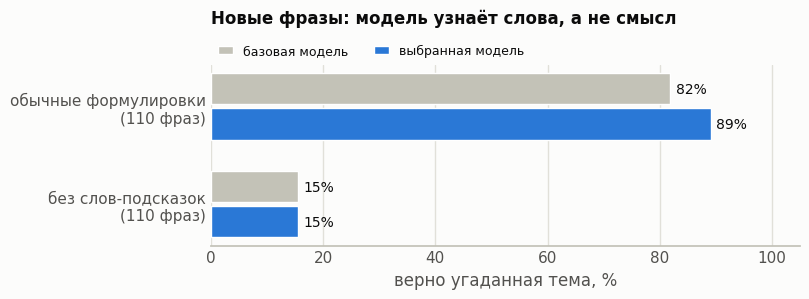

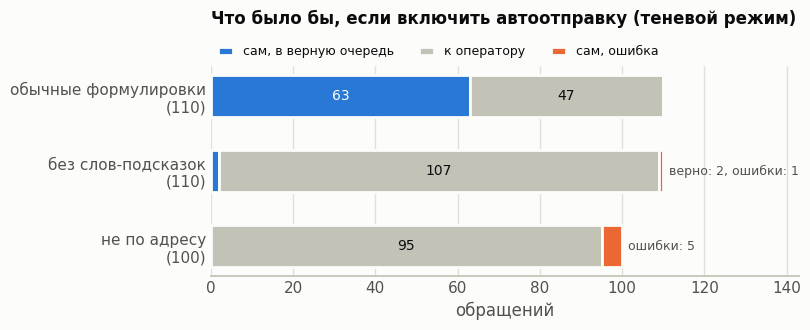

Рабочий режим на всех 320 фразах: сам не отправил ни одной, всё ушло оператору или попросило текст.


In [54]:
# @title Ячейка 51: Новые фразы, единственная оценка
# @markdown Сравниваем выбранную модель с базовой (TF-IDF по словам + логистическая регрессия) на одних и тех же фразах.
# @markdown Рабочий режим проверяем на главное обещание: сам ничего не отправляет. Теневой режим показывает,
# @markdown что было бы при включённой автоотправке с порогами этапа 7 (уверенность 0.85, сходство 0.45).
shadow_live = sc.shadow_bundle(model)
DIFFICULTY_RU = {'natural': 'обычные формулировки', 'no_keywords': 'без слов-подсказок'}
TOPIC_RU = {'off_topic': 'вопросы не о магазине', 'out_of_scope': 'о магазине, но вне 11 тем',
            'app_failure': 'сбой сайта или приложения', 'gibberish': 'бессмыслица',
            'other_language': 'другой язык', 'multiple_topics': 'несколько тем сразу'}
EXPECTED_RULE = {'other_language': 'POSSIBLY_UNSUPPORTED_LANGUAGE',
                 'app_failure': 'TECHNICAL_ISSUE_NEEDS_REVIEW',
                 'multiple_topics': 'POSSIBLE_MULTIPLE_REQUESTS'}
ALLOWED_DEPLOYED = ['MANUAL_REVIEW', 'NEEDS_CLARIFICATION']

# --- 220 обращений по 11 темам ---
hard_texts = hard.text.tolist()
hard_pred = np.asarray(model.predict(hard_texts))
hard_base = np.asarray(baseline_final.predict(hard_texts))
hard_routes = sc.batch_route(model, hard_texts)
hard_shadow = sc.batch_route(shadow_live, hard_texts)
hard_report = hard.assign(
    prediction=hard_pred, baseline_prediction=hard_base,
    correct=hard_pred == hard.category.to_numpy(), baseline_correct=hard_base == hard.category.to_numpy(),
    confidence=[r['confidence'] for r in hard_shadow], similarity=[r['similarity'] for r in hard_shadow],
    deployed_status=[r['status'] for r in hard_routes], shadow_status=[r['status'] for r in hard_shadow],
    shadow_queue=[r['queue'] for r in hard_shadow], reasons=[';'.join(r['reason_codes']) for r in hard_shadow])
hard_report['true_queue'] = hard_report.category.map(sc.CATEGORY_TO_QUEUE)
hard_report['shadow_auto'] = hard_report.shadow_status.eq('AUTO_RECOMMENDED')
hard_report['shadow_wrong_queue'] = hard_report.shadow_auto & hard_report.shadow_queue.ne(hard_report.true_queue)
assert hard_report.deployed_status.isin(ALLOWED_DEPLOYED).all(), 'рабочий режим не должен отправлять сам'
hard_report.to_csv(REPORTS_DIR/'stage11_hard_test_predictions.csv', index=False)


def hard_summary(part):
    auto = part.shadow_auto
    wrong = int(part.shadow_wrong_queue.sum())
    return {'n': len(part), 'model_correct': int(part.correct.sum()),
            'model_accuracy': float(part.correct.mean()),
            'baseline_correct': int(part.baseline_correct.sum()),
            'baseline_accuracy': float(part.baseline_correct.mean()),
            'deployed_auto': int(part.deployed_status.eq('AUTO_RECOMMENDED').sum()),
            'shadow_auto': int(auto.sum()), 'shadow_auto_right_queue': int(auto.sum()) - wrong,
            'shadow_wrong_queue': wrong, 'shadow_wrong_category': int((auto & ~part.correct).sum()),
            'shadow_manual': int((~auto).sum()),
            'shadow_wrong_queue_wilson_upper': sc.wilson_upper(wrong, int(auto.sum()))}


hard_results = {'all': hard_summary(hard_report)}
for level, part in hard_report.groupby('difficulty'):
    hard_results[level] = hard_summary(part)
hard_results['paired_vs_baseline'] = sc.paired_error_test(hard.category.to_numpy(), hard_base, hard_pred)
hard_results['per_category'] = {
    cat: {level: {'model': int(g.correct.sum()), 'baseline': int(g.baseline_correct.sum()), 'n': len(g)}
          for level, g in part.groupby('difficulty')}
    for cat, part in hard_report.groupby('category')}

hard_table = pd.DataFrame({DIFFICULTY_RU.get(k, 'все 220'): {
    'фраз': v['n'],
    'тема верна: модель': f"{v['model_correct']} ({v['model_accuracy']:.1%})",
    'тема верна: базовая': f"{v['baseline_correct']} ({v['baseline_accuracy']:.1%})",
    'рабочий режим: сам': v['deployed_auto'],
    'теневой: сам, верная очередь': v['shadow_auto_right_queue'],
    'теневой: сам, чужая очередь': v['shadow_wrong_queue'],
    'теневой: к оператору': v['shadow_manual']} for k, v in hard_results.items()
    if k in ['natural', 'no_keywords', 'all']}).T
display(hard_table)
print('Модель против базовой на тех же фразах (точный биномиальный тест по расхождениям):',
      hard_results['paired_vs_baseline'])
per_category_table = pd.DataFrame({
    cat: {f'{DIFFICULTY_RU[level]}: модель': f"{x['model']}/{x['n']}" for level, x in levels.items()} |
         {f'{DIFFICULTY_RU[level]}: базовая': f"{x['baseline']}/{x['n']}" for level, x in levels.items()}
    for cat, levels in hard_results['per_category'].items()}).T
display(per_category_table)
wrong_auto = hard_report[hard_report.shadow_wrong_queue]
print('Теневой режим отправил бы сам в чужую очередь:')
display(wrong_auto[['text', 'category', 'prediction', 'difficulty', 'confidence', 'similarity']])

# --- 100 обращений не по адресу ---
ood_texts_new = ood_new.text.tolist()
ood_routes_new = sc.batch_route(model, ood_texts_new)
ood_shadow_new = sc.batch_route(shadow_live, ood_texts_new)
ood_report_new = ood_new.assign(
    suggested_category=[r['suggested_category'] for r in ood_shadow_new],
    confidence=[r['confidence'] for r in ood_shadow_new], similarity=[r['similarity'] for r in ood_shadow_new],
    deployed_status=[r['status'] for r in ood_routes_new], shadow_status=[r['status'] for r in ood_shadow_new],
    shadow_queue=[r['queue'] for r in ood_shadow_new], reasons=[';'.join(r['reason_codes']) for r in ood_shadow_new])
ood_report_new['false_auto'] = ood_report_new.shadow_status.eq('AUTO_RECOMMENDED')
ood_report_new['rule_fired'] = [(EXPECTED_RULE[t] in r['reason_codes']) if t in EXPECTED_RULE else None
                                for t, r in zip(ood_new.topic, ood_shadow_new)]
assert ood_report_new.deployed_status.isin(ALLOWED_DEPLOYED).all(), 'рабочий режим не должен отправлять сам'
ood_report_new.to_csv(REPORTS_DIR/'stage11_ood_predictions.csv', index=False)
ood_results = {'n': len(ood_report_new), 'deployed_auto': 0,
               'shadow_false_auto': int(ood_report_new.false_auto.sum()),
               'shadow_false_auto_wilson_upper': sc.wilson_upper(int(ood_report_new.false_auto.sum()),
                                                                 len(ood_report_new)),
               'by_topic': {}}
for topic, part in ood_report_new.groupby('topic'):
    ood_results['by_topic'][topic] = {
        'n': len(part), 'shadow_false_auto': int(part.false_auto.sum()),
        'rule': EXPECTED_RULE.get(topic),
        'rule_fired': int(part.rule_fired.sum()) if topic in EXPECTED_RULE else None}
ood_table = pd.DataFrame({TOPIC_RU[t]: {
    'фраз': v['n'], 'теневой режим отправил бы сам': v['shadow_false_auto'],
    'нужное правило сработало': '' if v['rule'] is None else f"{v['rule_fired']} из {v['n']}"}
    for t, v in ood_results['by_topic'].items()}).T
display(ood_table)
print('Не по адресу, но теневой режим отправил бы сам:')
display(ood_report_new[ood_report_new.false_auto][['text', 'topic', 'suggested_category', 'confidence', 'similarity']])

# --- Графики ---
FIG_DIR = REPORTS_DIR/'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
INK, INK_2, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#fcfcfb'
BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#c3c2b7'
style = {'axes.spines.top': False, 'axes.spines.right': False, 'axes.spines.left': False,
         'axes.edgecolor': GRAY, 'axes.facecolor': SURFACE, 'figure.facecolor': SURFACE,
         'savefig.facecolor': SURFACE, 'axes.titlelocation': 'left', 'axes.titleweight': 'bold',
         'axes.titlesize': 12, 'axes.titlecolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
         'xtick.labelcolor': INK_2, 'ytick.labelcolor': INK_2, 'text.color': INK, 'font.size': 10}


def finish(ax, title, xlabel):
    ax.xaxis.grid(True, color=GRID, linewidth=1)
    ax.yaxis.grid(False)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    ax.set_xlabel(xlabel, color=INK_2)
    ax.set_title(title, pad=30)
    ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=9,
              handlelength=1.2, borderaxespad=0.2)


with plt.rc_context(style):
    fig, ax = plt.subplots(figsize=(8.2, 3.1))
    rows = ['natural', 'no_keywords']
    ys = np.arange(len(rows))
    for offset, key, color, label in [(-.18, 'baseline_accuracy', GRAY, 'базовая модель'),
                                      (.18, 'model_accuracy', BLUE, 'выбранная модель')]:
        values = [hard_results[r][key] * 100 for r in rows]
        ax.barh(ys + offset, values, height=.32, color=color, label=label, zorder=3)
        for y, v in zip(ys + offset, values):
            ax.text(v + 1, y, f'{v:.0f}%', va='center', color=INK, fontsize=10)
    ax.set_yticks(ys, [f"{DIFFICULTY_RU[r]}\n({hard_results[r]['n']} фраз)" for r in rows])
    ax.invert_yaxis()
    ax.set_xlim(0, 105)
    finish(ax, 'Новые фразы: модель узнаёт слова, а не смысл', 'верно угаданная тема, %')
    fig.tight_layout()
    fig.savefig(FIG_DIR/'stage11_topic_accuracy.png', dpi=160, bbox_inches='tight')
    plt.show()

    fig, ax = plt.subplots(figsize=(8.2, 3.4))
    segments = [('сам, в верную очередь', 'верно', BLUE, 'white'), ('к оператору', 'к оператору', GRAY, INK),
                ('сам, ошибка', 'ошибки', ORANGE, 'white')]
    bars = [('обычные формулировки', [hard_results['natural'][k] for k in
                                      ['shadow_auto_right_queue', 'shadow_manual', 'shadow_wrong_queue']]),
            ('без слов-подсказок', [hard_results['no_keywords'][k] for k in
                                    ['shadow_auto_right_queue', 'shadow_manual', 'shadow_wrong_queue']]),
            ('не по адресу', [0, ood_results['n'] - ood_results['shadow_false_auto'],
                              ood_results['shadow_false_auto']])]
    ys = np.arange(len(bars))
    left = np.zeros(len(bars))
    small = {y: [] for y in ys}
    for idx, (label, short, color, text_color) in enumerate(segments):
        values = np.array([b[1][idx] for b in bars], dtype=float)
        ax.barh(ys, values, left=left, color=color, height=.55, label=label, edgecolor=SURFACE,
                linewidth=2, zorder=3)
        for y, l0, v in zip(ys, left, values):
            if v >= 8:
                ax.text(l0 + v / 2, y, f'{int(v)}', ha='center', va='center', color=text_color, fontsize=10)
            elif v > 0:
                small[y].append(f'{short}: {int(v)}')
        left += values
    for y, total in zip(ys, left):
        if small[y]:
            ax.text(total + 1.5, y, ', '.join(small[y]), va='center', color=INK_2, fontsize=9)
    ax.set_yticks(ys, [f'{b[0]}\n({int(sum(b[1]))})' for b in bars])
    ax.invert_yaxis()
    ax.set_xlim(0, max(left) * 1.3)
    finish(ax, 'Что было бы, если включить автоотправку (теневой режим)', 'обращений')
    fig.tight_layout()
    fig.savefig(FIG_DIR/'stage11_shadow_outcomes.png', dpi=160, bbox_inches='tight')
    plt.show()
print('Рабочий режим на всех 320 фразах: сам не отправил ни одной, всё ушло оператору или попросило текст.')


In [55]:
# @title Ячейка 52: Ручная проверка нестандартных формулировок
# @markdown Каждая строка: что проверяем, текст, какую тему ждём (или что обращение обязано уйти оператору)
# @markdown и какое правило должно сработать. «Пройдено» означает: рабочий режим сам не отправил, теневой не
# @markdown отправил бы в чужую очередь, нужное правило сработало. Отдельно видно, угадана ли тема.
LONG_STORY = ('Hello, I have been a customer of yours for many years and I have always been happy. '
              'Last month my sister told me about a concert in our city, so I bought two tickets for us '
              'on your website. We were both very excited and even booked a hotel nearby. Yesterday I '
              'received a message saying that the concert was cancelled because the singer is ill. I '
              'understand that these things happen and nobody is to blame. Still, the tickets were '
              'expensive, so I would like to get a refund as soon as possible.')
POLITE = ('Hello, I hope you are doing well. I was wondering if you could possibly help me, I would '
          'like to get an invoice for my purchase. Thank you very much!')
# (группа, что проверяем, текст, ожидаемая тема или None, обязательно к оператору, ожидаемый флаг или код)
NONSTANDARD = [
    ('форма текста', 'капс и восклицания', 'I WANT A REFUND NOW!!!', 'REFUNDS', False, None),
    ('форма текста', 'лишние пробелы и переносы', '  I   want\n to cancel \t my order  ', 'ORDER', False, None),
    ('форма текста', 'опечатки', 'i wnat to chnage my shiping adress', 'SHIPPING', False, None),
    ('форма текста', 'опечатки и капс', 'CANT LOGIN TO MY ACOUNT!!!', 'ACCOUNT', False, None),
    ('форма текста', 'сокращения', 'pls cancel my order asap thx', 'ORDER', False, None),
    ('форма текста', 'смайлики', 'where is my order 😡😡', 'ORDER', False, None),
    ('форма текста', 'вежливо и длинно', POLITE, 'INVOICES', False, None),
    ('форма текста', 'одно слово', 'refund', 'REFUNDS', False, None),
    ('форма текста', 'короткая жалоба', "I can't log in", 'ACCOUNT', False, None),
    ('форма текста', 'шаблон вместо номера', 'I have a problem with order {{Order Number}}', 'ORDER', False, None),
    ('форма текста', 'номер заказа цифрами', 'my order 48213 has not arrived yet', 'ORDER', False, None),
    ('форма текста', 'отрицание', 'I do not want a refund, I want to change my order', 'ORDER', False, None),
    ('форма текста', 'HTML-разметка', '<b>cancel</b> my order please', 'ORDER', False, None),
    ('форма текста', 'длинная история', LONG_STORY, 'REFUNDS', False, None),
    ('форма текста', 'эмоции без просьбы', 'you are the worst company ever', 'FEEDBACK', False, None),
    ('не по адресу', 'приветствие без просьбы', 'hello', None, True, None),
    ('не по адресу', 'вопрос не о магазине', 'What is the capital of France?', None, True, None),
    ('не по адресу', 'русский язык', 'Где мой заказ?', None, True, 'POSSIBLY_UNSUPPORTED_LANGUAGE'),
    ('не по адресу', 'смесь языков', 'Привет, I need a refund', None, True, 'POSSIBLY_UNSUPPORTED_LANGUAGE'),
    ('не по адресу', 'испанский язык', 'Quiero cancelar mi pedido', None, True, 'POSSIBLY_UNSUPPORTED_LANGUAGE'),
    ('не по адресу', 'только знаки', '?!?!', None, True, 'INSUFFICIENT_SUPPORTED_TEXT'),
    ('не по адресу', 'похоже на код', "'; DROP TABLE tickets; --", None, True, None),
    ('не по адресу', 'только ссылка', 'https://example.com/help', None, True, None),
    ('несколько тем', 'две темы', 'My payment failed and I need to change my shipping address', None, True,
     'POSSIBLE_MULTIPLE_REQUESTS'),
    ('несколько тем', 'три темы', 'Reset my password, return my money, and cancel my order', None, True,
     'POSSIBLE_MULTIPLE_REQUESTS'),
    ('риски', 'угроза через «I\'m»', "I'm going to kill you", None, True, 'POSSIBLE_THREAT'),
    ('риски', 'иск через «gonna»', "I'm gonna sue you", None, True, 'POSSIBLE_LEGAL_CLAIM'),
    ('риски', 'отрицание угрозы', "I'm not going to hurt anyone, I just want my refund", 'REFUNDS', False,
     'NO_RISK_FLAG'),
    ('риски', 'взлом другим порядком слов', 'Someone hacked my account and ordered things I never asked for',
     None, True, 'POSSIBLE_FRAUD'),
    ('риски', 'мошенничество новыми словами', 'I see a fraudulent charge on my card', None, True, 'POSSIBLE_FRAUD'),
]
manual_rows = []
for group, kind, text, expected, must_operator, signal in NONSTANDARD:
    r, sh = sc.route_ticket(text, model), sc.route_ticket(text, shadow_live)
    shadow_auto = sh['status'] == 'AUTO_RECOMMENDED'
    if must_operator or expected is None:
        shadow_ok = not shadow_auto
    else:
        shadow_ok = not shadow_auto or sh['queue'] == sc.CATEGORY_TO_QUEUE[expected]
    signals = set(r['risk_flags']) | set(r['reason_codes'])
    if signal == 'NO_RISK_FLAG':
        signal_ok = not {'POSSIBLE_THREAT', 'POSSIBLE_FRAUD', 'POSSIBLE_LEGAL_CLAIM'} & set(r['risk_flags'])
    else:
        signal_ok = signal is None or signal in signals
    manual_rows.append({
        'группа': group, 'что проверяем': kind, 'текст': text if len(text) < 70 else text[:67] + '...',
        'ждём': expected or 'к оператору', 'модель думает': r['suggested_category'] or 'нет',
        'уверенность': None if r['confidence'] is None else round(r['confidence'], 3),
        'приоритет': r['priority'], 'рабочий режим': r['status'],
        'теневой режим': f"сам: {sh['queue']}" if shadow_auto else sh['status'],
        'тема': '' if expected is None else ('✓' if r['suggested_category'] == expected else '✗'),
        'правило': '' if signal is None else ('✓' if signal_ok else '✗'),
        'пройдено': r['status'] != 'AUTO_RECOMMENDED' and shadow_ok and signal_ok})
manual_report = pd.DataFrame(manual_rows)
manual_report.to_csv(REPORTS_DIR/'stage11_nonstandard_cases.csv', index=False)
with pd.option_context('display.max_colwidth', 70):
    display(manual_report)
nonstandard_results = {
    'n': len(manual_report), 'passed': int(manual_report['пройдено'].sum()),
    'topic_expected_n': int(manual_report['тема'].ne('').sum()),
    'topic_correct': int(manual_report['тема'].eq('✓').sum()),
    'failed': manual_report.loc[~manual_report['пройдено'], ['что проверяем', 'текст']].to_dict('records')}
print(f"Пройдено {nonstandard_results['passed']} из {nonstandard_results['n']}; "
      f"тема угадана в {nonstandard_results['topic_correct']} из {nonstandard_results['topic_expected_n']} "
      'случаев, где у обращения одна понятная тема.')


           группа                 что проверяем  ... правило пройдено
0    форма текста            капс и восклицания  ...             True
1    форма текста     лишние пробелы и переносы  ...             True
2    форма текста                      опечатки  ...             True
3    форма текста               опечатки и капс  ...             True
4    форма текста                    сокращения  ...             True
5    форма текста                      смайлики  ...             True
6    форма текста              вежливо и длинно  ...             True
7    форма текста                    одно слово  ...             True
8    форма текста               короткая жалоба  ...             True
9    форма текста          шаблон вместо номера  ...             True
10   форма текста          номер заказа цифрами  ...             True
11   форма текста                     отрицание  ...             True
12   форма текста                 HTML-разметка  ...             True
13   форма текста   

Пройдено 29 из 30; тема угадана в 12 из 16 случаев, где у обращения одна понятная тема.


In [56]:
# @title Ячейка 53: Что нашли и что исправили
# @markdown Сравниваем текущие правила рисков с версией 3.1.0.
# @markdown Ниже доказательство, что она ничего не меняет на данных проекта, и полная таблица находок.

def risk_rules_v310(text):
    """Правила рисков версии 3.1.0 без изменений: только для сравнения «до и после»."""
    t = sc.preprocess(text)
    quoted = re.sub(r'"[^"\n]*"|“[^”\n]*”', " ", t)
    reported = bool(re.search(r"\b(threatened me|threatening me|sent me (?:a )?threat|someone threatened)\b", t))
    direct = bool(re.search(r"\bi(?: will|'ll| am going to| intend to)\s+"
                            r"(?:kill|hurt|attack|shoot|make)\s+"
                            r"(?:you|your|the courier|the driver|staff|someone|you pay)\b", quoted))
    direct = direct or bool(re.search(r"\bi(?: will|'ll)\s+make you pay\b", quoted))
    fraud = bool(re.search(r"\b(unauthori[sz]ed (?:payment|charge|transaction)|(?:account|card) (?:was |has been )?(?:hacked|stolen|compromised)|did not authori[sz]e|do not recogni[sz]e (?:this|the|a) (?:charge|payment))\b", t))
    legal = bool(re.search(r"\b(i(?: will|'ll| intend to| am going to) (?:sue|take (?:you|this) to court)|formal (?:legal )?(?:claim|notice)|legal (?:notice|proceedings)|my lawyer (?:has|will|is))\b", quoted))
    abuse = bool(re.search(r"\b(?:idiots?|morons?|stupid|fuck(?:ing)?|shit|assholes?)\b", quoted))
    fraud = fraud or bool(re.search(r"\b(?:i (?:did not|didn't|never) (?:make|place|approve) "
                                  r"(?:this|that|the) (?:purchase|order|payment|transaction)|"
                                  r"someone (?:used|is using) my (?:card|account)|"
                                  r"this (?:purchase|charge|payment) (?:is not|was not) mine)\b", t))
    return [f for f, on in [('POSSIBLE_THREAT', direct or reported), ('POSSIBLE_FRAUD', fraud),
                            ('POSSIBLE_LEGAL_CLAIM', legal), ('ABUSE_LANGUAGE', abuse)] if on]


project_texts = raw.utterance.tolist()
for groups in [manual_cases.DEV, manual_cases.HOLDOUT, scenario_data.DEV, scenario_data.HOLDOUT]:
    for texts in groups.values():
        project_texts += list(texts)
project_texts += list(scenario_data.LEGACY_OOD) + [t for t, _ in scenario_data.DEMO]
project_texts += [x['text'] for x in category_examples.EXAMPLES]
changed_on_project = [t for t in project_texts if risk_rules_v310(t) != sc.detect_signals(t)['risk_flags']]
changed_on_frozen = [t for t in hard.text.tolist() + ood_new.text.tolist()
                     if risk_rules_v310(t) != sc.detect_signals(t)['risk_flags']]
n_project = f'{len(project_texts):,}'.replace(',', ' ')
if not changed_on_project and not changed_on_frozen:
    print(f'Правки 3.1.1–3.1.2 не меняет ни одного флага ни на {n_project} фразах проекта '
          '(весь Bitext и все наборы этапов 1-9), ни на замороженных наборах.')
else:
    print(f'Правки 3.1.1–3.1.2 меняет флаги у {len(changed_on_project)} из {n_project} фраз проекта '
          f'и у {len(changed_on_frozen)} фраз замороженных наборов.')
assert not changed_on_project, changed_on_project[:5]

fixed_examples = ["I'm going to kill you", "I'm gonna sue you", 'The courier threatened to hurt me',
                  'Someone hacked my account', 'My card got hacked', 'I never placed this order',
                  "This transaction isn't mine", "There is a charge I don't recognise on my card"]
fixed_examples += ['I see a fraudulent charge on my card', 'I have been scammed by your seller',
                 "I'm gonna kill ya", 'i m going to kill you']
open_examples = []
display(pd.DataFrame([{'фраза': t, 'было (3.1.0)': ', '.join(risk_rules_v310(t)) or 'нет флага',
                       'стало (3.1.2)': ', '.join(sc.detect_signals(t)['risk_flags']) or 'нет флага',
                       'приоритет': sc.route_ticket(t, model)['priority']}
                      for t in fixed_examples + open_examples]))

hr, orr, bt = hard_results, ood_results, ood_results['by_topic']
nk = hr['no_keywords']
def operator_note(topic):
    info = bt[topic]
    if info['shadow_false_auto']:
        return f"теневой режим отправил бы сам {info['shadow_false_auto']} из {info['n']}"
    return (f"все {info['n']} всё равно ушли бы к оператору: {info['rule_fired']} по правилу, остальные потому, "
            "что модель не уверена или фраза не похожа на обучающие")


tech_note, lang_note = operator_note('app_failure'), operator_note('other_language')
findings = [
    {'что нашли': 'Угрозы, иски и мошенничество в другом написании не получали флаг риска: '
                  '«I\'m going to kill you», «gonna sue», «threatened to hurt me», «someone hacked my account», '
                  '«I never placed this order», «a charge I don\'t recognise»',
     'где': 'ручная проверка', 'статус': 'исправлено',
     'что сделали': 'Версия 3.1.1, модуль rules: в существующие шаблоны добавлены сокращения, другой порядок слов, '
                    'прошедшее время и синоним на том же месте. На фразах проекта флаги не изменились, '
                    'выводы этапов 1-9 тоже. Добавлены регрессионные тесты.'},
    {'что нашли': 'Ложный P1 на «I will make you a list» и пропуски прямых сообщений о мошенничестве и угрозах.',
     'где': 'ручная проверка', 'статус': 'исправлено',
     'что сделали': 'Сузили ветку make you pay, добавили варианты прямых сообщений и парные отрицательные примеры. '
                    'Синтетический набор data/eval/risk_regression.csv проверяет регрессии по каждому флагу.'},
    {'что нашли': f"Без слов-подсказок модель угадывает тему в {nk['model_correct']} из {nk['n']} фраз, "
                  + ('базовая столько же' if nk['baseline_correct'] == nk['model_correct']
                     else f"базовая в {nk['baseline_correct']}"),
     'где': 'замороженный набор 220', 'статус': 'ограничение модели',
     'что сделали': f"TF-IDF узнаёт слова, а не смысл. Защищает порог: теневой режим отправил бы сам только "
                    f"{nk['shadow_auto']} из {nk['n']} таких фраз, остальные ушли бы оператору."},
    {'что нашли': f"Две темы в одном обращении: правило сработало на {bt['multiple_topics']['rule_fired']} из 15, "
                  f"теневой режим отправил бы сам {bt['multiple_topics']['shadow_false_auto']}",
     'где': 'набор «не по адресу»', 'статус': 'открыто',
     'что сделали': 'Не исправлено: расширение словаря тем меняет отбор обращений для порога на этапе 7. '
                    'В рабочем режиме такие обращения всё равно видит оператор.'},
    {'что нашли': f"Сбои сайта и приложения: правило сработало на {bt['app_failure']['rule_fired']} из 15",
     'где': 'набор «не по адресу»', 'статус': 'открыто',
     'что сделали': f'Не исправлено: слова вроде error встречаются и в обычных вопросах об оплате. '
                    f'Из этих обращений {tech_note}.'},
    {'что нашли': f"Другой язык распознан в {bt['other_language']['rule_fired']} из 15: правило знает только "
                  'несколько алфавитов и десяток слов',
     'где': 'набор «не по адресу»', 'статус': 'открыто',
     'что сделали': f'Не исправлено, для сервиса нужен настоящий определитель языка. Из этих обращений {lang_note}.'},
    {'что нашли': f"Теневой режим отправил бы сам {orr['shadow_false_auto']} из {orr['n']} обращений не по адресу "
                  f"и {hr['all']['shadow_wrong_queue']} из {hr['all']['n']} обычных в чужую очередь",
     'где': 'оба замороженных набора', 'статус': 'учтено',
     'что сделали': 'Автоотправка остаётся выключенной, как решили на этапе 7: сначала реальные обращения '
                    '(не меньше 300 по темам и 200 не по адресу) и согласование с бизнесом.'},
    {'что нашли': 'Короткие и неоднозначные фразы: «I can\'t log in» модель относит к INVOICES, '
                  'шаблон {{Order Number}} к PAYMENT, «I do not want a refund…» к REFUNDS',
     'где': 'ручная проверка', 'статус': 'ограничение модели',
     'что сделали': 'Уверенность у таких ответов низкая, поэтому даже теневой режим отдаёт их оператору. '
                    'Лечится данными, а не правилами.'},
]
findings_table = pd.DataFrame(findings)[['что нашли', 'где', 'что сделали', 'статус']]
with pd.option_context('display.max_colwidth', 400):
    display(findings_table)
findings_table.to_csv(REPORTS_DIR/'stage11_findings.csv', index=False)

stage11 = {
    'code_version': sc.VERSION,
    'fix': {'what': 'Risk rule variants, first-person fraud reports and narrower make-you-pay matching',
            'project_texts_checked': len(project_texts), 'project_texts_changed': len(changed_on_project),
            'frozen_texts_changed': len(changed_on_frozen),
            'fixed_examples': fixed_examples, 'open_examples': open_examples},
    'tests': stage11_tests,
    'frozen_sets': {name: {'sha256': digest, 'written': '2026-11-13', 'role': 'post-selection diagnostic'}
                    for name, digest in FROZEN_SETS.items()},
    'frozen_overlap_with_project': overlap_rows,
    'hard_test': hard_results, 'ood_new': ood_results, 'nonstandard_manual': nonstandard_results,
    'findings': findings, 'independence_note': 'Phrases written by the project assistant, not real customers; '
    'below the 300 ID / 200 OOD real-data bar of results.json external_validation.'}
saved_results = json.loads((REPORTS_DIR/'results.json').read_text(encoding='utf-8'))
saved_results['stage11'] = stage11
sc.write_json(REPORTS_DIR/'results.json', saved_results)
print('Итоги этапа 11 записаны в reports/results.json (раздел stage11).')


                                             фраза  ... приоритет
0                            I'm going to kill you  ...        P1
1                                I'm gonna sue you  ...        P2
2                The courier threatened to hurt me  ...        P1
3                        Someone hacked my account  ...        P1
4                               My card got hacked  ...        P1
5                        I never placed this order  ...        P1
6                      This transaction isn't mine  ...        P1
7   There is a charge I don't recognise on my card  ...        P1
8             I see a fraudulent charge on my card  ...        P1
9               I have been scammed by your seller  ...        P1
10                               I'm gonna kill ya  ...        P1
11                           i m going to kill you  ...        P1

[12 rows x 4 columns]

                                                                                                                                                                                                                       что нашли  ...              статус
0  Угрозы, иски и мошенничество в другом написании не получали флаг риска: «I'm going to kill you», «gonna sue», «threatened to hurt me», «someone hacked my account», «I never placed this order», «a charge I don't recognise»  ...          исправлено
1                                                                                                                                   Ложный P1 на «I will make you a list» и пропуски прямых сообщений о мошенничестве и угрозах.  ...          исправлено
2                                                                                                                                                  Без слов-подсказок модель угадывает тему в 17 из 110 фраз, базовая столько же  ...  ограничение модели


Правки 3.1.1–3.1.2 не меняет ни одного флага ни на 21 689 фразах проекта (весь Bitext и все наборы этапов 1-9), ни на замороженных наборах.
Итоги этапа 11 записаны в reports/results.json (раздел stage11).


In [57]:
# @title Ячейка 54: Выводы этапа 11
# @markdown Текст собирается из результатов этого прогона, поэтому цифры в нём всегда совпадают с таблицами выше.
from IPython.display import Markdown
hr, orr, ns, tests = hard_results, ood_results, nonstandard_results, stage11_tests
nat, nk = hr['natural'], hr['no_keywords']
paired = hr['paired_vs_baseline']
total_new = hr['all']['n'] + orr['n']
skip_note = f", {tests['skipped']} пропущены без семантического энкодера" if tests['skipped'] else ''


def plural(value, one, few, many):
    k = abs(int(value)) % 100
    if 11 <= k <= 14:
        return many
    return {1: one, 2: few, 3: few, 4: few}.get(k % 10, many)


num_ru = lambda x: f'{x:,}'.replace(',', ' ')


def compare(model_n, base_n):
    if model_n == base_n:
        return f'столько же, сколько базовая ({base_n})'
    return f'базовая угадала {base_n}'


shadow_auto_all = hr['all']['shadow_auto']
errors_seen = hr['all']['shadow_wrong_queue'] + orr['shadow_false_auto']
errors_note = ('Ошибок немного, но на нескольких сотнях фраз нельзя подтвердить уровень ошибок ниже 1%, '
               'которого требует этап 7.' if errors_seen else
               'Ошибок нет, но на нескольких сотнях фраз нельзя подтвердить уровень ошибок ниже 1%, '
               'которого требует этап 7.')
test_f1 = json.loads((REPORTS_DIR/'results.json').read_text(encoding='utf-8'))['test']['macro_f1']
summary_md = f"""
### Выводы этапа 11

**Главное обещание выполнено.** В рабочем режиме система не отправила сама ни одного из {total_new} новых
обращений: каждое ушло оператору с подсказкой темы или с просьбой прислать текст. Из {tests['tests']}
автотестов прошли {tests['passed']}, ни один не упал; {tests['xfailed_known_gaps']} записаны как известные пропуски
правил рисков{skip_note}.

**Модель узнаёт слова, а не смысл.** Когда клиент пишет обычными словами, тема угадана в
{nat['model_correct']} из {nat['n']} обращений ({nat['model_accuracy']:.0%}), {compare(nat['model_correct'], nat['baseline_correct'])}.
Когда слов-подсказок нет, модель угадывает только {nk['model_correct']} из {nk['n']}, {compare(nk['model_correct'], nk['baseline_correct'])}.
По всем 220 фразам модель права там, где базовая ошиблась, {paired['a_wrong_b_correct']} {plural(paired['a_wrong_b_correct'], 'раз', 'раза', 'раз')}, а наоборот
{paired['a_correct_b_wrong']} {plural(paired['a_correct_b_wrong'], 'раз', 'раза', 'раз')} (p = {paired['p_value']:.2f}), то есть на новых фразах разница с базовой
моделью статистически не доказана. Цифры test Bitext (macro-F1 {test_f1:.3f}) этого не показывают: test собран
из тех же шаблонов, что и обучение.

**Выключенная автоотправка оправдана.** В теневом режиме, то есть если бы автоотправку включили с порогами
этапа 7, система сама отправила бы {shadow_auto_all} из {hr['all']['n']} обычных обращений, из них
{hr['all']['shadow_wrong_queue']} в чужую очередь, и ещё {orr['shadow_false_auto']} из {orr['n']} обращений
не по адресу. {errors_note}

**Правила приоритета.** Нейтральная фраза «I will make you a list» остаётся P3.
Прямое сообщение «I see a fraudulent charge on my card» получает флаг мошенничества и P1.
Регрессионные примеры проверяют конкретные формулировки. Полнота на реальном потоке неизвестна.

Ручная проверка: пройдено {ns['passed']} из {ns['n']} нестандартных формулировок, тема угадана в
{ns['topic_correct']} из {ns['topic_expected_n']} случаев с одной понятной темой. Не пройденные строки
описаны в таблице находок.
"""
display(Markdown(summary_md))



### Выводы этапа 11

**Главное обещание выполнено.** В рабочем режиме система не отправила сама ни одного из 320 новых
обращений: каждое ушло оператору с подсказкой темы или с просьбой прислать текст. Из 221
автотестов прошли 221, ни один не упал; 0 записаны как известные пропуски
правил рисков.

**Модель узнаёт слова, а не смысл.** Когда клиент пишет обычными словами, тема угадана в
98 из 110 обращений (89%), базовая угадала 90.
Когда слов-подсказок нет, модель угадывает только 17 из 110, столько же, сколько базовая (17).
По всем 220 фразам модель права там, где базовая ошиблась, 16 раз, а наоборот
8 раз (p = 0.15), то есть на новых фразах разница с базовой
моделью статистически не доказана. Цифры test Bitext (macro-F1 0.996) этого не показывают: test собран
из тех же шаблонов, что и обучение.

**Выключенная автоотправка оправдана.** В теневом режиме, то есть если бы автоотправку включили с порогами
этапа 7, система сама отправила бы 66 из 220 обычных обращений, из них
1 в чужую очередь, и ещё 5 из 100 обращений
не по адресу. Ошибок немного, но на нескольких сотнях фраз нельзя подтвердить уровень ошибок ниже 1%, которого требует этап 7.

**Правила приоритета.** Нейтральная фраза «I will make you a list» остаётся P3.
Прямое сообщение «I see a fraudulent charge on my card» получает флаг мошенничества и P1.
Регрессионные примеры проверяют конкретные формулировки. Полнота на реальном потоке неизвестна.

Ручная проверка: пройдено 29 из 30 нестандартных формулировок, тема угадана в
12 из 16 случаев с одной понятной темой. Не пройденные строки
описаны в таблице находок.


# Этап 12. Документация и итоги

Описание проекта лежит в репозитории: `README.md` (запуск, результаты), `docs/architecture.md` (части системы и их связи), `docs/api.md` (HTTP API), `docs/runbook.md` (метрики, оповещения и что делать при сбоях), а также отчёт и презентация в `docs/`. Ниже ячейка 55 собирает отчёт о результатах этого прогона из `results.json`, ячейка 56 упаковывает проект и проверяет архив распаковкой в пустую папку, ячейка 57 сверяет цифры отчёта и презентации с прогоном, ячейка 58 подводит итог проекта.

In [58]:
# @title Ячейка 55: Отчёт о результатах этого прогона
# @markdown Этап 12. Описание проекта лежит в README и docs/, а здесь из `reports/results.json` собирается
# @markdown отчёт `reports/results.md` с цифрами именно этого прогона, чтобы они не расходились с ноутбуком.
from IPython.display import Markdown
R = json.loads((REPORTS_DIR/'results.json').read_text(encoding='utf-8'))


def plural(value, one, few, many):
    k = abs(int(value)) % 100
    if 11 <= k <= 14:
        return many
    return {1: one, 2: few, 3: few, 4: few}.get(k % 10, many)


S11 = R['stage11']
hard_all, hard_nat, hard_nk = (S11['hard_test'][k] for k in ['all', 'natural', 'no_keywords'])
ood11 = S11['ood_new']
splits = R['data']['splits']
loio = sorted(R['loio_summary'], key=lambda x: -x['all25_mean_recall'])
loio_base = next(x for x in loio if x['model'].startswith('lr_word'))
loio_best = next(x for x in loio if x['model'] == R['model_name'])
pct = lambda x: f'{x:.1%}'
num = lambda x: f'{x:,}'.replace(',', ' ')
loio_rows = '\n'.join(f"| {x['model']} | {pct(x['all25_mean_recall'])} |" for x in loio)
ts = R['test_shadow_routing']
tests11 = S11['tests']
open_findings = [f for f in S11['findings'] if f['статус'] != 'исправлено']
open_rows = '\n'.join(f"- {f['что нашли']} ({f['статус']}). {f['что сделали']}" for f in open_findings)
skipped_note = f", {tests11['skipped']} пропущены (нужен семантический энкодер или promtool)" if tests11['skipped'] else ''

RESULTS_MD = f"""# Результаты прогона

Модель `{R['model_name']}`, номер `{R['model_id']}`, код версии {S11['code_version']}. Отчёт собран ноутбуком
из `reports/results.json`; как устроен проект и как его запустить, описано в `README.md` и `docs/`.

## Данные

{num(R['data']['cleaning']['raw_rows'])} {plural(R['data']['cleaning']['raw_rows'], 'обращение', 'обращения', 'обращений')} Bitext,
после очистки {num(R['data']['cleaning']['clean_rows'])}. Похожие фразы объединены в {num(R['data']['grouping']['n_groups'])}
{plural(R['data']['grouping']['n_groups'], 'группу', 'группы', 'групп')}; части выборки: обучение {num(splits['train']['rows'])},
калибровка {num(splits['calibration']['rows'])}, выбор порога {num(splits['val']['rows'])}, test {num(splits['test']['rows'])}.

## Выбор модели (LOIO, 25 интентов)

| Конфигурация | LOIO |
|---|---|
{loio_rows}

## Качество

| Проверка | Выбранная модель | Базовая |
|---|---|---|
| Test Bitext, {num(R['test']['n'])} {plural(R['test']['n'], 'фраза', 'фразы', 'фраз')} | macro-F1 {R['test']['macro_f1']:.4f}, ошибок {R['test']['errors']} | macro-F1 {R['baseline_test']['macro_f1']:.4f}, ошибок {R['baseline_test']['errors']} |
| LOIO, 25 интентов | {pct(loio_best['all25_mean_recall'])} | {pct(loio_base['all25_mean_recall'])} |
| Новые фразы обычными словами, {hard_nat['n']} | {hard_nat['model_correct']} ({pct(hard_nat['model_accuracy'])}) | {hard_nat['baseline_correct']} ({pct(hard_nat['baseline_accuracy'])}) |
| Новые фразы без слов-подсказок, {hard_nk['n']} | {hard_nk['model_correct']} ({pct(hard_nk['model_accuracy'])}) | {hard_nk['baseline_correct']} ({pct(hard_nk['baseline_accuracy'])}) |

![Новые фразы](figures/stage11_topic_accuracy.png)

## Что было бы при включённой автоотправке (теневой режим)

Пороги: уверенность не ниже {R['policy']['confidence_threshold']}, сходство с обучением не ниже {R['policy']['similarity_threshold']}.

| Набор | Рабочий режим: сам | Теневой: сам, верная очередь | Теневой: сам, ошибка | Теневой: к оператору |
|---|---|---|---|---|
| Test Bitext, {num(ts['n'])} | 0 | {num(ts['automatic_n'] - ts['automatic_queue_errors'])} | {ts['automatic_queue_errors']} | {num(ts['manual_n'])} |
| Новые фразы, {hard_all['n']} | 0 | {hard_all['shadow_auto_right_queue']} | {hard_all['shadow_wrong_queue']} | {hard_all['shadow_manual']} |
| Не по адресу, {ood11['n']} | 0 | не бывает | {ood11['shadow_false_auto']} | {ood11['n'] - ood11['shadow_false_auto']} |

![Теневой режим](figures/stage11_shadow_outcomes.png)

## Тестирование

Автотестов {tests11['tests']}: прошли {tests11['passed']}, упавших нет, {tests11['xfailed_known_gaps']} записаны как известные
пропуски правил рисков{skipped_note}. На {num(S11['fix']['project_texts_checked'])} фразах проекта правка правил риска
версии {S11['code_version']} изменила флаги у {S11['fix']['project_texts_changed']} фраз. Что осталось открытым:

{open_rows}
"""
(REPORTS_DIR/'results.md').write_text(RESULTS_MD, encoding='utf-8')
print('reports/results.md:', len(RESULTS_MD.splitlines()), 'строк')
display(Markdown(RESULTS_MD.replace('](figures/', '](reports/figures/')))


# Результаты прогона

Модель `linsvc_wc_C1`, номер `router-937116a8646a48e3`, код версии 3.1.2. Отчёт собран ноутбуком
из `reports/results.json`; как устроен проект и как его запустить, описано в `README.md` и `docs/`.

## Данные

21 534 обращения Bitext,
после очистки 19 700. Похожие фразы объединены в 3 646
групп; части выборки: обучение 11 970,
калибровка 2 240, выбор порога 2 368, test 3 122.

## Выбор модели (LOIO, 25 интентов)

| Конфигурация | LOIO |
|---|---|
| linsvc_wc_C1 | 81.8% |
| semantic_lr_C1 | 79.7% |
| semantic_aug_lr_C1 | 79.7% |
| semantic_svc_C1 | 76.1% |
| linsvc_w_C0.5 | 72.6% |
| linsvc_w_C1 | 72.0% |
| linsvc_w_C3 | 71.8% |
| lr_word (baseline) | 68.6% |
| sgd_w_a1e-4 | 62.0% |
| sgd_w_a5e-5 | 59.3% |
| sgd_w_a2e-5 | 58.8% |

## Качество

| Проверка | Выбранная модель | Базовая |
|---|---|---|
| Test Bitext, 3 122 фразы | macro-F1 0.9963, ошибок 10 | macro-F1 0.9935, ошибок 16 |
| LOIO, 25 интентов | 81.8% | 68.6% |
| Новые фразы обычными словами, 110 | 98 (89.1%) | 90 (81.8%) |
| Новые фразы без слов-подсказок, 110 | 17 (15.5%) | 17 (15.5%) |

![Новые фразы](reports/figures/stage11_topic_accuracy.png)

## Что было бы при включённой автоотправке (теневой режим)

Пороги: уверенность не ниже 0.85, сходство с обучением не ниже 0.45.

| Набор | Рабочий режим: сам | Теневой: сам, верная очередь | Теневой: сам, ошибка | Теневой: к оператору |
|---|---|---|---|---|
| Test Bitext, 3 122 | 0 | 3 062 | 6 | 54 |
| Новые фразы, 220 | 0 | 65 | 1 | 154 |
| Не по адресу, 100 | 0 | не бывает | 5 | 95 |

![Теневой режим](reports/figures/stage11_shadow_outcomes.png)

## Тестирование

Автотестов 221: прошли 221, упавших нет, 0 записаны как известные
пропуски правил рисков. На 21 689 фразах проекта правка правил риска
версии 3.1.2 изменила флаги у 0 фраз. Что осталось открытым:

- Без слов-подсказок модель угадывает тему в 17 из 110 фраз, базовая столько же (ограничение модели). TF-IDF узнаёт слова, а не смысл. Защищает порог: теневой режим отправил бы сам только 3 из 110 таких фраз, остальные ушли бы оператору.
- Две темы в одном обращении: правило сработало на 5 из 15, теневой режим отправил бы сам 3 (открыто). Не исправлено: расширение словаря тем меняет отбор обращений для порога на этапе 7. В рабочем режиме такие обращения всё равно видит оператор.
- Сбои сайта и приложения: правило сработало на 1 из 15 (открыто). Не исправлено: слова вроде error встречаются и в обычных вопросах об оплате. Из этих обращений все 15 всё равно ушли бы к оператору: 1 по правилу, остальные потому, что модель не уверена или фраза не похожа на обучающие.
- Другой язык распознан в 7 из 15: правило знает только несколько алфавитов и десяток слов (открыто). Не исправлено, для сервиса нужен настоящий определитель языка. Из этих обращений все 15 всё равно ушли бы к оператору: 7 по правилу, остальные потому, что модель не уверена или фраза не похожа на обучающие.
- Теневой режим отправил бы сам 5 из 100 обращений не по адресу и 1 из 220 обычных в чужую очередь (учтено). Автоотправка остаётся выключенной, как решили на этапе 7: сначала реальные обращения (не меньше 300 по темам и 200 не по адресу) и согласование с бизнесом.
- Короткие и неоднозначные фразы: «I can't log in» модель относит к INVOICES, шаблон {{Order Number}} к PAYMENT, «I do not want a refund…» к REFUNDS (ограничение модели). Уверенность у таких ответов низкая, поэтому даже теневой режим отдаёт их оператору. Лечится данными, а не правилами.


reports/results.md: 63 строк


In [59]:
# @title Ячейка 56: Архив проекта и проверка в чистой папке
# @markdown Собираем в один zip всё, что нужно для запуска, и проверяем его как посторонний человек:
# @markdown распаковываем в пустую папку, запускаем самопроверку приложения и все автотесты.
import zipfile, tempfile
ARCHIVE = PROJECT_DIR/'support-ticket-router.zip'
SKIP_PARTS = {'__pycache__', '.pytest_cache', '.ruff_cache', '.git', '.ipynb_checkpoints'}
ARCHIVE_DIRS = ['src', 'scripts', 'tests', 'docs', 'monitoring', 'notebooks', 'data/eval']
ARCHIVE_FILES = ['README.md', 'pyproject.toml', 'requirements.txt', 'requirements-api.txt', 'Dockerfile',
                 '.dockerignore', 'docker-compose.yml', '.gitignore', 'app.py',
                 'models/router.joblib', 'models/router_meta.json', 'models/encoder/encoder_manifest.json',
                 'data/processed/split_manifest.json']
for folder in ARCHIVE_DIRS:
    ARCHIVE_FILES += sorted(str(p.relative_to(PROJECT_DIR)) for p in (PROJECT_DIR/folder).rglob('*')
                            if p.is_file() and not SKIP_PARTS & set(p.parts))
ARCHIVE_FILES += sorted(str(p.relative_to(PROJECT_DIR)) for p in REPORTS_DIR.glob('*')
                        if p.is_file() and p.suffix in {'.json', '.csv', '.md'} and p.stat().st_size < 3_000_000)
ARCHIVE_FILES += sorted(str(p.relative_to(PROJECT_DIR)) for p in (REPORTS_DIR/'figures').glob('*.png'))
ARCHIVE_FILES = list(dict.fromkeys(f for f in ARCHIVE_FILES if (PROJECT_DIR/f).exists()))


def build_archive():
    with zipfile.ZipFile(ARCHIVE, 'w', zipfile.ZIP_DEFLATED) as zf:
        for rel in ARCHIVE_FILES:
            zf.write(PROJECT_DIR/rel, rel)
    return ARCHIVE.stat().st_size


build_archive()
clean_dir = Path(tempfile.mkdtemp(prefix='router_clean_'))
with zipfile.ZipFile(ARCHIVE) as zf:
    zf.extractall(clean_dir)
clean_env = dict(os.environ, PYTHONPATH=os.pathsep.join([str(clean_dir/'src'), str(clean_dir)]),
                 PYTEST_DISABLE_PLUGIN_AUTOLOAD='1', SUPPORT_SKIP_SEMANTIC_TESTS='1', GRADIO_ANALYTICS_ENABLED='False',
                 NO_PROXY='127.0.0.1,localhost', no_proxy='127.0.0.1,localhost')
clean_env.pop('SUPPORT_ROUTER_HOME', None)
clean_env.pop('SUPPORT_ROUTER_MODELS_DIR', None)
clean_check = subprocess.run([sys.executable, 'app.py', '--check'], cwd=clean_dir, env=clean_env,
                             capture_output=True, text=True, encoding='utf-8', errors='replace', timeout=600)
assert clean_check.returncode == 0 and 'CHECK OK' in clean_check.stdout, clean_check.stderr[-3000:]
clean_tests = subprocess.run([sys.executable, '-m', 'pytest', '-q', '--color=no', '--disable-warnings',
                              '-p', 'no:cacheprovider'], cwd=clean_dir, env=clean_env,
                             capture_output=True, text=True, encoding='utf-8', errors='replace', timeout=1800)
assert clean_tests.returncode == 0, clean_tests.stdout[-3000:] + clean_tests.stderr[-3000:]
clean_summary = clean_tests.stdout.strip().splitlines()[-1]
print('Чистая папка:', clean_dir)
print('Самопроверка приложения: CHECK OK')
print('Автотесты из архива:', clean_summary, '(семантические пропущены, чтобы не скачивать энкодер заново)')

saved_results = json.loads((REPORTS_DIR/'results.json').read_text(encoding='utf-8'))
saved_results['stage12'] = {'archive': ARCHIVE.name, 'files': ARCHIVE_FILES,
                            'clean_folder_app_check': True, 'clean_folder_tests': clean_summary,
                            'results_report': 'reports/results.md'}
sc.write_json(REPORTS_DIR/'results.json', saved_results)
size = build_archive()  # пересобираем, чтобы в архиве был results.json с разделом stage12
print(f'Архив {ARCHIVE.name}: {len(ARCHIVE_FILES)} файлов, {size/1e6:.1f} МБ')
display(pd.Series([f for f in ARCHIVE_FILES if '/' not in f or f.split('/')[0] in {'src', 'monitoring', 'docs', 'models'}],
                  name='главные файлы архива'))
if 'google.colab' in sys.modules and os.environ.get('SUPPORT_NONINTERACTIVE') != '1':
    from google.colab import files
    files.download(str(ARCHIVE))


0                                   README.md
1                              pyproject.toml
2                            requirements.txt
3                        requirements-api.txt
4                                  Dockerfile
5                               .dockerignore
6                          docker-compose.yml
7                                  .gitignore
8                                      app.py
9                        models/router.joblib
10                    models/router_meta.json
11       models/encoder/encoder_manifest.json
12             src/support_router/__init__.py
13                  src/support_router/api.py
14            src/support_router/artifacts.py
15    src/support_router/category_examples.py
16               src/support_router/config.py
17                 src/support_router/data.py
18           src/support_router/evaluation.py
19              src/support_router/explain.py
20         src/support_router/manual_cases.py
21               src/support_route

Чистая папка: /tmp/router_clean_3yajvula
Самопроверка приложения: CHECK OK
Автотесты из архива: 219 passed, 2 skipped in 10.12s (семантические пропущены, чтобы не скачивать энкодер заново)
Архив support-ticket-router.zip: 82 файлов, 20.0 МБ


In [60]:
# @title Ячейка 57: Сравнение исторических слайдов версии 3.1.1 с текущим прогоном
# @markdown Цифры на слайдах взяты из прогона, по которому собрана презентация. Здесь они сравниваются
# @markdown с тем, что получилось сейчас. Расхождение не ошибка ноутбука, а сигнал поправить слайд.
R = json.loads((REPORTS_DIR/'results.json').read_text(encoding='utf-8'))
S11 = R['stage11']
H, O, T11 = S11['hard_test'], S11['ood_new'], S11['tests']
TS = R['test_shadow_routing']
loio = {x['model']: x['all25_mean_recall'] for x in R['loio_summary']}
vs_base = next(x for x in R['loio_paired_intent_bootstrap'] if x['candidate'].startswith('lr_word'))
per_file = {row['файл']: row['всего'] for row in T11['per_file']}
n = lambda x: f'{x:,}'.replace(',', ' ')
p1 = lambda x: f'{x:.1%}'
SLIDES = [
    ('Данные', 'обращений в датасете', '21 534', n(R['data']['cleaning']['raw_rows'])),
    ('Данные', 'строк после очистки', '19 700', n(R['data']['cleaning']['clean_rows'])),
    ('Данные', 'удалено дублей', '1 834', n(R['data']['cleaning']['deduplicated_rows'])),
    ('Данные', 'групп похожих фраз', '3 646', n(R['data']['grouping']['n_groups'])),
    ('Данные', 'разбиение', '11 970 / 2 240 / 2 368 / 3 122',
     ' / '.join(n(R['data']['splits'][k]['rows']) for k in ['train', 'calibration', 'val', 'test'])),
    ('Модель', 'LOIO выбранной', '81.8%', p1(loio[R['model_name']])),
    ('Модель', 'LOIO базовой', '68.6%', p1(next(v for k, v in loio.items() if k.startswith('lr_word')))),
    ('Модель', 'интентов, где выбранная лучше базовой', '22', str(vs_base['candidate_losses'])),
    ('Три проверки качества', 'test macro-F1', '0.996', f"{R['test']['macro_f1']:.3f}"),
    ('Три проверки качества', 'ошибок на test', '10 из 3 122', f"{R['test']['errors']} из {n(R['test']['n'])}"),
    ('Три проверки качества', 'новые фразы: тема верна', '115 из 220 (52.3%)',
     f"{H['all']['model_correct']} из {H['all']['n']} ({p1(H['all']['model_accuracy'])})"),
    ('Три проверки качества', 'обычные слова: модель / базовая', '89.1% / 81.8%',
     f"{p1(H['natural']['model_accuracy'])} / {p1(H['natural']['baseline_accuracy'])}"),
    ('Три проверки качества', 'без подсказок: модель / базовая', '15.5% / 15.5%',
     f"{p1(H['no_keywords']['model_accuracy'])} / {p1(H['no_keywords']['baseline_accuracy'])}"),
    ('Порог и автоотправка', 'уверенность / сходство', '0.85 / 0.45',
     f"{R['policy']['confidence_threshold']} / {R['policy']['similarity_threshold']}"),
    ('Порог и автоотправка', 'test: верно / оператору / ошибка', '3 062 / 54 / 6',
     f"{n(TS['automatic_n'] - TS['automatic_queue_errors'])} / {TS['manual_n']} / {TS['automatic_queue_errors']}"),
    ('Порог и автоотправка', 'новые фразы: верно / оператору / ошибка', '65 / 154 / 1',
     f"{H['all']['shadow_auto_right_queue']} / {H['all']['shadow_manual']} / {H['all']['shadow_wrong_queue']}"),
    ('Порог и автоотправка', 'не по адресу: оператору / ошибка', '95 / 5',
     f"{O['n'] - O['shadow_false_auto']} / {O['shadow_false_auto']}"),
    ('Тестирование и найденная проблема', 'автотестов, известных пропусков', '222, 4',
     f"{T11['tests']}, {T11['xfailed_known_gaps']}"),
    ('Тестирование и найденная проблема', 'тестов HTTP API', '48', str(per_file['test_api.py'])),
    ('Тестирование и найденная проблема', 'тестов метрик и алертов', '6', str(per_file['test_monitoring.py'])),
    ('Тестирование и найденная проблема', 'упавших тестов', '0', str(T11['failures'] + T11['errors'])),
    ('Тестирование и найденная проблема', 'рабочий режим отправил сам', '0 из 320',
     f"{H['all']['deployed_auto'] + O['deployed_auto']} из {H['all']['n'] + O['n']}"),
    ('Тестирование и найденная проблема', 'нестандартных формулировок пройдено', '28 из 30',
     f"{S11['nonstandard_manual']['passed']} из {S11['nonstandard_manual']['n']}"),
    ('Тестирование и найденная проблема', 'фраз проекта / изменённых флагов', '21 689 / 0',
     f"{n(S11['fix']['project_texts_checked'])} / {S11['fix']['project_texts_changed']}"),
    ('Выводы и ограничения', 'без слов-подсказок тема верна', '15%', f"{H['no_keywords']['model_accuracy']:.0%}"),
]
api_example = sc.route_ticket('Someone hacked my account', model)
SLIDES += [
    ('Рефакторинг', 'файлов пакета', '19', str(len(list((PROJECT_DIR/'src'/'support_router').glob('*.py'))))),
    ('Рефакторинг', 'тестов команды', '88', str(per_file['test_support_core.py'])),
    ('Архитектура', 'правил алертов', '11',
     str(len(re.findall(r'^\s*- alert:', (PROJECT_DIR/'monitoring'/'alert_rules.yml').read_text(encoding='utf-8'), flags=re.M)))),
    ('HTTP API и Docker', 'Someone hacked my account', 'MANUAL_REVIEW, P1, POSSIBLE_FRAUD, ACCOUNT, Queue_Manual_Review',
     ', '.join([api_example['status'], api_example['priority'], *api_example['risk_flags'],
                str(api_example['category']), str(api_example['queue'])])),
]
check = pd.DataFrame(SLIDES, columns=['слайд', 'что', 'на слайде', 'в этом прогоне'])
check['совпадает'] = np.where(check['на слайде'] == check['в этом прогоне'], '✓', 'поправить слайд')
display(check)
mismatch = check[check['совпадает'] != '✓']
if mismatch.empty:
    print(f"Все {len(check)} {plural(len(check), 'цифра', 'цифры', 'цифр')} презентации совпадают с этим прогоном.")
else:
    print(f'Не совпадают {len(mismatch)} из {len(check)}: поправьте эти места на слайдах.')


                                слайд  ...        совпадает
0                              Данные  ...                ✓
1                              Данные  ...                ✓
2                              Данные  ...                ✓
3                              Данные  ...                ✓
4                              Данные  ...                ✓
5                              Модель  ...                ✓
6                              Модель  ...                ✓
7                              Модель  ...                ✓
8               Три проверки качества  ...                ✓
9               Три проверки качества  ...                ✓
10              Три проверки качества  ...                ✓
11              Три проверки качества  ...                ✓
12              Три проверки качества  ...                ✓
13               Порог и автоотправка  ...                ✓
14               Порог и автоотправка  ...                ✓
15               Порог и автоотправка  .

Не совпадают 3 из 29: поправьте эти места на слайдах.


In [61]:
# @title Ячейка 58: Итог проекта
# @markdown Текст собирается из `results.json` этого прогона, поэтому цифры в нём совпадают с ноутбуком.
from IPython.display import Markdown
R = json.loads((REPORTS_DIR/'results.json').read_text(encoding='utf-8'))
S11 = R['stage11']
H, O = S11['hard_test'], S11['ood_new']
loio = {x['model']: x['all25_mean_recall'] for x in R['loio_summary']}
best, base = loio[R['model_name']], next(v for k, v in loio.items() if k.startswith('lr_word'))
tests = S11['tests']
p = lambda x: f'{x:.1%}'
num_ru = lambda x: f'{x:,}'.replace(',', ' ')

final_md = f"""
## Итог проекта

За двенадцать этапов собрана система, которая читает обращение клиента, предлагает одну из 11 тем и
очередь, ставит приоритет и отмечает риски. Данные разбиты так, что похожие фразы не попадают одновременно
в обучение и проверку. Модель выбрана по тому, как она узнаёт целиком незнакомые интенты, а не по test,
который собран из тех же шаблонов. Порог автоотправки выбран, но сама автоотправка выключена и работает
только в теневом режиме. Код вынесен из ноутбука в пакет `support_router`, поверх него работают HTTP-сервис
FastAPI, интерфейс Gradio и Docker-образ, за сервисом следят метрики Prometheus и правила алертов. Всё это
проверено автотестами и новыми фразами, найденный дефект исправлен.

| Проверка | Результат |
|---|---|
| Test Bitext, {num_ru(R['test']['n'])} {'фразы' if R['test']['n'] % 10 in (2, 3, 4) and R['test']['n'] % 100 not in (12, 13, 14) else 'фраз'} | macro-F1 {R['test']['macro_f1']:.3f}, ошибок {R['test']['errors']} (базовая {R['baseline_test']['macro_f1']:.3f}, ошибок {R['baseline_test']['errors']}) |
| Новые интенты (LOIO, 25 штук) | {p(best)} верных ответов, базовая {p(base)} |
| Новые фразы с обычными словами | тема верна в {H['natural']['model_correct']} из {H['natural']['n']} |
| Новые фразы без слов-подсказок | тема верна в {H['no_keywords']['model_correct']} из {H['no_keywords']['n']} |
| Теневой режим на новых фразах | сам отправил бы {H['all']['shadow_auto']} из {H['all']['n']}, в чужую очередь {H['all']['shadow_wrong_queue']} |
| Теневой режим на обращениях не по адресу | сам отправил бы {O['shadow_false_auto']} из {O['n']} |
| Рабочий режим на всех проверках | сам не отправил ни одного обращения |
| Автотесты | {tests['tests']}: прошли {tests['passed']}, упавших нет, известных пропусков {tests['xfailed_known_gaps']}, пропущено {tests['skipped']} |
"""
display(Markdown(final_md))


## Итог проекта

За двенадцать этапов собрана система, которая читает обращение клиента, предлагает одну из 11 тем и
очередь, ставит приоритет и отмечает риски. Данные разбиты так, что похожие фразы не попадают одновременно
в обучение и проверку. Модель выбрана по тому, как она узнаёт целиком незнакомые интенты, а не по test,
который собран из тех же шаблонов. Порог автоотправки выбран, но сама автоотправка выключена и работает
только в теневом режиме. Код вынесен из ноутбука в пакет `support_router`, поверх него работают HTTP-сервис
FastAPI, интерфейс Gradio и Docker-образ, за сервисом следят метрики Prometheus и правила алертов. Всё это
проверено автотестами и новыми фразами, найденный дефект исправлен.

| Проверка | Результат |
|---|---|
| Test Bitext, 3 122 фразы | macro-F1 0.996, ошибок 10 (базовая 0.994, ошибок 16) |
| Новые интенты (LOIO, 25 штук) | 81.8% верных ответов, базовая 68.6% |
| Новые фразы с обычными словами | тема верна в 98 из 110 |
| Новые фразы без слов-подсказок | тема верна в 17 из 110 |
| Теневой режим на новых фразах | сам отправил бы 66 из 220, в чужую очередь 1 |
| Теневой режим на обращениях не по адресу | сам отправил бы 5 из 100 |
| Рабочий режим на всех проверках | сам не отправил ни одного обращения |
| Автотесты | 221: прошли 221, упавших нет, известных пропусков 0, пропущено 0 |
